# EDA general de ENASIC 2022 y de todas las fuentes del repo

**Alcance.** Exploración amplia, *no* acotada al nicho ya mapeado (cuidadoras de alta intensidad, tipología AGEB, focalización). El objetivo es saber **qué hay, con qué calidad y qué permite (y qué no permite) cada fuente**, para decidir con evidencia qué más vale la pena usar.

**Reglas que respeta este cuaderno** (las del proyecto):
- Toda cifra sale de una celda ejecutable; nada se escribe de memoria. Las lecturas en texto se redactan *después* de ver el resultado.
- Cada afirmación nueva se marca **[confirmada]** (verificada en datos de esta corrida), **[probable]** (consistente con los datos pero sin prueba directa) o **[desconocida]** (no se pudo verificar con lo que hay en el repo).
- Sin conclusiones por alcaldía con ENASIC ni con ninguna encuesta nacional: aquí solo se examina **si la fuente lo permite**.
- Los microdatos de ENASIC se leen localmente; este cuaderno **no** imprime registros individuales, solo agregados.

**Cómo leerlo.** §0 prepara el entorno · §1 inventario · §2 ENASIC (seis tablas) · §3 fuentes agregadas CDMX · §4 contexto nacional y pobreza · §5 Censo/AGEB/geografía · §6 DENUE · §7 Data Warehouse · §8 cruces entre fuentes · §9 hallazgos, límites y preguntas abiertas.

## 0. Entorno y utilidades

In [1]:
import warnings, zipfile, re, unicodedata, sqlite3, subprocess, glob, os, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

pd.set_option('display.width', 220, 'display.max_columns', 60, 'display.max_colwidth', 90,
              'display.max_rows', 200, 'display.float_format', lambda v: f'{v:,.3f}')
plt.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 9, 'axes.titlesize': 10})

def _raiz():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / 'Analysis' / 'datos').exists():
            return q
    raise FileNotFoundError('No encuentro la raíz del repo (carpeta con Analysis/datos).')

RAIZ = _raiz(); DATOS = RAIZ / 'Analysis' / 'datos'; ENA = DATOS / 'enasic'
SALIDA = RAIZ / 'Analysis' / 'eda_general'; SALIDA.mkdir(exist_ok=True)
print('Raíz del repo:', RAIZ)
print('pandas', pd.__version__, '| numpy', np.__version__)

def leer_csv(src, **kw):
    """Lee CSV probando utf-8-sig y latin-1 (las fuentes INEGI/DENUE mezclan codificaciones)."""
    for enc in ('utf-8-sig', 'latin-1'):
        try:
            if hasattr(src, 'seek'): src.seek(0)
            return pd.read_csv(src, encoding=enc, low_memory=False, **kw)
        except UnicodeDecodeError:
            continue
    raise

def limpiar_cols(df):
    df = df.copy(); df.columns = [str(c).replace('﻿', '').replace('ï»¿', '').strip() for c in df.columns]; return df

def sin_acentos(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode()
    return ' '.join(s.upper().replace('.', '').split())

def perfil_cols(df):
    """Perfil por columna: tipo, nulos, únicos, rango/ejemplo."""
    filas = []
    for c in df.columns:
        s = df[c]; num = pd.api.types.is_numeric_dtype(s)
        filas.append({'columna': c, 'tipo': str(s.dtype), 'nulos': int(s.isna().sum()), 'pct_nulo': 100 * s.isna().mean(),
                      'unicos': s.nunique(dropna=True),
                      'min': s.min() if num and s.notna().any() else None, 'max': s.max() if num and s.notna().any() else None,
                      'ejemplo': (s.dropna().iloc[0] if s.notna().any() else None) if not num else None})
    return pd.DataFrame(filas)

def resumen(df, nombre):
    return {'tabla': nombre, 'filas': len(df), 'cols': df.shape[1], 'dup_filas': int(df.duplicated().sum()),
            'pct_nulo_global': 100 * df.isna().to_numpy().mean(), 'MB': df.memory_usage(deep=True).sum() / 1e6}

def _patrones_gitignore():
    f = RAIZ / '.gitignore'
    if not f.exists(): return None
    return [l.strip() for l in f.read_text(encoding='utf-8').splitlines() if l.strip() and not l.lstrip().startswith(('#', '!'))]

PAT_GI = _patrones_gitignore()

def git_ignorado(ruta):
    """Aproximación a .gitignore (sin negaciones): True si algún patrón del .gitignore cubre la ruta; None si no hay .gitignore."""
    import fnmatch
    if PAT_GI is None: return None
    rel = str(Path(ruta).relative_to(RAIZ)).replace('\\', '/'); partes = rel.split('/')
    for p in PAT_GI:
        solo_dir = p.endswith('/'); q = p.rstrip('/')
        if '/' in q:                                     # patrón con ruta: prefijo desde la raíz
            if rel == q or rel.startswith(q + '/') or fnmatch.fnmatch(rel, q): return True
        elif solo_dir:                                   # carpeta con ese nombre en cualquier nivel
            if q in partes[:-1]: return True
        elif any(fnmatch.fnmatch(x, q) for x in partes):
            return True
    return False

Raíz del repo: /sessions/rcw-012w6vc4gu4jin27dnlsryxy/mnt/pp26-2
pandas 2.3.3 | numpy 2.2.6


## 1. Inventario de fuentes

Primero, qué hay físicamente: archivos de datos, tamaño, formato y si git los ignora (relevante para la regla de protección de datos y para saber qué puede reconstruir otra persona del equipo).

In [2]:
exts = {'.csv', '.zip', '.xlsx', '.shp', '.dbf', '.sqlite', '.pdf', '.txt'}
filas = []
carpetas = [DATOS, RAIZ / 'Data', RAIZ / 'DW', RAIZ / 'Analysis' / 'enut2024_participacion_laboral']
for base in carpetas:
    for f in base.rglob('*'):
        if f.is_file() and f.suffix.lower() in exts and 'catalogos' not in f.parts and 'diccionario_de_datos' not in f.parts \
           and 'metadatos' not in f.parts and 'modelo_entidad_relacion' not in f.parts:
            filas.append({'ruta': str(f.relative_to(RAIZ)).replace('\\', '/'), 'ext': f.suffix.lower(), 'MB': f.stat().st_size / 1e6})
inv = pd.DataFrame(filas).sort_values('MB', ascending=False).reset_index(drop=True)
inv['git_ignora'] = [git_ignorado(RAIZ / r) for r in inv.ruta]
print(f'{len(inv)} archivos de datos/documentación (sin contar los archivos de catálogos, diccionarios y metadatos de ENASIC)')
display(inv.groupby('ext').agg(archivos=('ruta', 'size'), MB=('MB', 'sum')).round(1))
display(inv.head(25))
print('\nArchivos de datos NO ignorados por .gitignore (aprox.) y con tamaño > 5 MB:')
display(inv[(inv.git_ignora == False) & (inv.MB > 5)])

66 archivos de datos/documentación (sin contar los archivos de catálogos, diccionarios y metadatos de ENASIC)


,archivos,MB
ext,,
.csv,48,298.800
.dbf,2,0.100
.pdf,4,13.300
.shp,2,2.900
.sqlite,1,10.100
.txt,3,0.000
.xlsx,1,8.900
.zip,5,40.700


,ruta,ext,MB,git_ignora
0,Data/raw/denue_inegi_09_.csv,.csv,260.023,True
1,Analysis/datos/enasic/conjunto_de_datos_tcsdempo_enasic_2022/conjunto_de_datos/conjunt...,.csv,13.344,True
2,Analysis/datos/censo2020_ageb/ageb_mza_urbana_09_cpv2020_csv.zip,.zip,12.991,True
3,Analysis/datos/enigh2022_coneval/pobreza22.csv.zip,.zip,10.389,True
4,Analysis/datos/conapo_marginacion/CONAPO_Indices_marginacion_2020_ent_mun_p1-153.pdf,.pdf,10.366,False
5,DW/observatorio_dw.sqlite,.sqlite,10.076,True
6,Analysis/datos/CONEVAL_pobreza_grupos_poblacionales_municipal_2010_2015_2020.xlsx,.xlsx,8.890,False
7,Analysis/datos/coneval_irs/grs_ageb_2020.csv.zip,.zip,8.557,True
8,Analysis/datos/enasic/conjunto_de_datos_tpob_cui_enasic_2022/conjunto_de_datos/conjunt...,.csv,8.491,True
9,Analysis/datos/enasic/conjunto_de_datos_tper_ele_enasic_2022/conjunto_de_datos/conjunt...,.csv,5.676,True



Archivos de datos NO ignorados por .gitignore (aprox.) y con tamaño > 5 MB:


,ruta,ext,MB,git_ignora
4,Analysis/datos/conapo_marginacion/CONAPO_Indices_marginacion_2020_ent_mun_p1-153.pdf,.pdf,10.366,False
6,Analysis/datos/CONEVAL_pobreza_grupos_poblacionales_municipal_2010_2015_2020.xlsx,.xlsx,8.890,False


## 2. ENASIC 2022 (Encuesta Nacional para el Sistema de Cuidados)

Seis tablas del conjunto de datos público de INEGI. Antes de calcular nada: arquitectura, llaves, diseño muestral y calidad. **Todas las estimaciones usan el factor de expansión de su tabla y errores estándar por linealización (estrato + UPM)**; si un resultado no lleva intervalo, no es una estimación poblacional.

### 2.1 Carga, diccionario y catálogos

In [3]:
ENA_T = {'viv': 'tvivienda', 'hog': 'thogar', 'res': 'tcsdempo', 'ele': 'tper_ele', 'cui': 'tpob_cui', 'uni': 'thog_unip'}
ENA_DESC = {'viv': 'Vivienda', 'hog': 'Hogar', 'res': 'Residentes del hogar', 'ele': 'Persona elegida',
            'cui': 'Población cuidadora', 'uni': 'Hogar unipersonal'}
PESO = {'viv': 'FAC_VIV', 'hog': 'FAC_HOG', 'res': 'FAC_HOG', 'ele': 'FAC_ELE', 'cui': 'FAC_CUI', 'uni': 'FAC_UNI'}

def _dir(k): return ENA / f'conjunto_de_datos_{ENA_T[k]}_enasic_2022'

def leer_ena(k):
    f = glob.glob(str(_dir(k) / 'conjunto_de_datos' / '*.csv'))[0]
    cols = pd.read_csv(f, nrows=0).columns
    return pd.read_csv(f, dtype={c: str for c in cols if c.startswith('LLAVE')}, low_memory=False)

def leer_dic(k):
    d = pd.read_csv(glob.glob(str(_dir(k) / 'diccionario_de_datos' / '*.csv'))[0]).iloc[:, :6]
    d.columns = ['etiqueta', 'long', 'tipo', 'nem', 'catalogo', 'rango']
    d['nem'] = d.nem.astype(str).str.strip().str.upper(); d['catalogo'] = d.catalogo.astype(str).str.strip().str.lower()
    return d.set_index('nem')

E = {k: leer_ena(k) for k in ENA_T}
DIC = {k: leer_dic(k) for k in ENA_T}
_cat_cache = {}
def catalogo(k, nombre):
    """{código(str sin ceros): descripción} del catálogo `nombre` de la tabla k; None si no existe."""
    clave = (k, nombre)
    if clave not in _cat_cache:
        f = _dir(k) / 'catalogos' / f'{nombre}.csv'
        if not f.exists(): _cat_cache[clave] = None
        else:
            c = limpiar_cols(leer_csv(f, dtype=str)); c.columns = ['cve', 'descrip'] + list(c.columns[2:])
            def norm(v):
                v = str(v).strip()
                try: return str(int(float(v)))
                except ValueError: return v
            _cat_cache[clave] = {norm(a): str(b).strip() for a, b in zip(c.cve, c.descrip)}
    return _cat_cache[clave]

def cat_de(k, var):
    if var not in DIC[k].index: return None
    n = DIC[k].loc[var, 'catalogo']
    if isinstance(n, pd.Series): n = n.iloc[0]
    return catalogo(k, n) if n not in ('nan', '') else None

def etiqueta(k, var):
    if var not in DIC[k].index: return var
    e = DIC[k].loc[var, 'etiqueta']; e = e.iloc[0] if isinstance(e, pd.Series) else e
    return re.sub(r'^Pregunta\s+\S+\s*', '', str(e))

tabla_dim = pd.DataFrame([{**resumen(E[k], k), 'descripcion': ENA_DESC[k], 'peso': PESO[k],
                           'vars_en_diccionario': len(DIC[k]), 'vars_con_catalogo': int((DIC[k].catalogo.isin(['nan', '']) == False).sum())}
                          for k in E]).set_index('tabla')
display(tabla_dim)

,filas,cols,dup_filas,pct_nulo_global,MB,descripcion,peso,vars_en_diccionario,vars_con_catalogo
tabla,,,,,,,,,
viv,6423,44,0,2.905,2.608,Vivienda,FAC_VIV,44,36
hog,6508,72,0,42.595,4.458,Hogar,FAC_HOG,72,53
res,21776,181,0,79.174,35.147,Residentes del hogar,FAC_HOG,181,158
ele,5579,275,0,43.842,13.200,Persona elegida,FAC_ELE,275,263
cui,5677,432,0,62.174,20.562,Población cuidadora,FAC_CUI,432,424
uni,928,315,0,55.585,2.493,Hogar unipersonal,FAC_UNI,315,307


### 2.2 Llaves, integridad referencial y qué no hay (geografía)

In [4]:
def pct_en(a, b):  # % de valores de a que existen en b
    return 100 * a.isin(set(b)).mean()

rel = pd.DataFrame([
    ('hogar → vivienda (LLAVEVIV)', pct_en(E['hog'].LLAVEVIV, E['viv'].LLAVEVIV)),
    ('residente → hogar (LLAVEHOG)', pct_en(E['res'].LLAVEHOG, E['hog'].LLAVEHOG)),
    ('persona elegida → hogar', pct_en(E['ele'].LLAVEHOG, E['hog'].LLAVEHOG)),
    ('cuidadora → hogar', pct_en(E['cui'].LLAVEHOG, E['hog'].LLAVEHOG)),
    ('unipersonal → hogar', pct_en(E['uni'].LLAVEHOG, E['hog'].LLAVEHOG)),
    ('persona elegida (LLAVEMOD) → residente (LLAVESDE)', pct_en(E['ele'].LLAVEMOD, E['res'].LLAVESDE)),
    ('cuidadora (LLAVEMOD) → residente (LLAVESDE)', pct_en(E['cui'].LLAVEMOD, E['res'].LLAVESDE)),
    ('unipersonal (LLAVEMOD) → residente (LLAVESDE)', pct_en(E['uni'].LLAVEMOD, E['res'].LLAVESDE)),
], columns=['relación', '% con llave existente'])
display(rel)

print('Viviendas:', len(E['viv']), '| hogares:', len(E['hog']), '| viviendas con >1 hogar:', int((E['hog'].groupby('LLAVEVIV').size() > 1).sum()))
print('Hogares sin ningún residente listado:', int((~E['hog'].LLAVEHOG.isin(set(E['res'].LLAVEHOG))).sum()))
print('Hogares con ≥1 cuidadora:', E['cui'].LLAVEHOG.nunique(), '| con persona elegida:', E['ele'].LLAVEHOG.nunique(), '| unipersonales:', E['uni'].LLAVEHOG.nunique())

solap = {a + '∩' + b: len(set(E[a].LLAVEMOD) & set(E[b].LLAVEMOD)) for a, b in [('ele', 'cui'), ('ele', 'uni'), ('cui', 'uni')]}
print('Personas presentes en más de una tabla de persona (LLAVEMOD):', solap)

patron_geo = re.compile(r'^(ENT|CVE|MUN|LOC|AGEB|EDO|ESTADO|DOMINIO|TAM_LOC|REGION)', re.I)
print('\nColumnas con apariencia geográfica en las 6 tablas:', {k: [c for c in E[k].columns if patron_geo.match(c)] for k in E})
muestra = E['viv'].assign(pref=lambda d: d.LLAVEVIV.str[:-2].astype(int))
print('LLAVEVIV[:-2] == UPM_DIS en', f"{100 * (muestra.pref == muestra.UPM_DIS).mean():.1f}% de viviendas")
meta = (_dir('res') / 'metadatos' / 'metadatos_enasic_2022.txt').read_text(encoding='utf-8', errors='ignore')
print('\nLíneas del metadato INEGI sobre cobertura/representatividad:')
for ln in meta.splitlines():
    if re.search(r'represent|entidad|nacional|cobertura|dominio|desagreg', ln, re.I): print(' -', ln.strip()[:260])

,relación,% con llave existente
0,hogar → vivienda (LLAVEVIV),100.000
1,residente → hogar (LLAVEHOG),100.000
2,persona elegida → hogar,100.000
3,cuidadora → hogar,100.000
4,unipersonal → hogar,100.000
5,persona elegida (LLAVEMOD) → residente (LLAVESDE),100.000
6,cuidadora (LLAVEMOD) → residente (LLAVESDE),100.000
7,unipersonal (LLAVEMOD) → residente (LLAVESDE),100.000


Viviendas: 6423 | hogares: 6508 | viviendas con >1 hogar: 70
Hogares sin ningún residente listado: 0
Hogares con ≥1 cuidadora: 3949 | con persona elegida: 5579 | unipersonales: 928
Personas presentes en más de una tabla de persona (LLAVEMOD): {'ele∩cui': 2283, 'ele∩uni': 535, 'cui∩uni': 120}

Columnas con apariencia geográfica en las 6 tablas: {'viv': [], 'hog': [], 'res': [], 'ele': [], 'cui': [], 'uni': []}
LLAVEVIV[:-2] == UPM_DIS en 100.0% de viviendas

Líneas del metadato INEGI sobre cobertura/representatividad:
 - Title: Encuesta Nacional para el Sistema de Cuidados 2022
 - Description: La ENASIC busca profundizar en objetivos, integrando la perspectiva de la demanda, la cobertura, impacto en quienes proveen cuidados, requerimientos sobre el mercado, entre otros. Además, para complementar el estudio de los cuidados, así como para
 - Generar información estadística sobre la demanda de cuidados en los hogares y las personas que brindan cuidados; identificar la demanda y cobertura p

### 2.3 Diseño muestral: estratos, UPM y pesos

,n,N_expandido(M),peso_min,peso_mediana,peso_max,CV_pesos,deff_Kish,n_efectivo_por_pesos,estratos,UPM,estratos_con_1_UPM,UPM_min_por_estrato
tabla,,,,,,,,,,,,
viv,6423,38.321,708,"4,481.000",34887,0.903,1.815,"3,539.369",148,896,0,2
hog,6508,38.786,708,"4,456.000",34887,0.901,1.812,"3,590.984",148,896,0,2
res,21776,128.857,708,"4,481.000",34887,0.885,1.784,"12,206.599",148,896,0,2
ele,5579,80.237,696,"9,366.000",165693,1.085,2.176,"2,563.308",148,895,0,2
cui,5677,31.652,718,"4,251.000",36676,0.874,1.763,"3,220.301",148,861,0,2
uni,928,5.731,718,"4,577.000",32864,0.909,1.826,508.251,143,531,17,1


Residentes: hogares cuyo FAC_HOG no es único dentro del hogar: 0
FAC_HOG igual entre tabla hogar y tabla residentes: True


Población expandida por residentes ENASIC: 128.9 M | suma POB_TOT municipal CONAPO 2020: 126.0 M | razón 1.023
Hogares expandidos ENASIC: 38.8 M | tamaño medio ponderado del hogar: 3.32


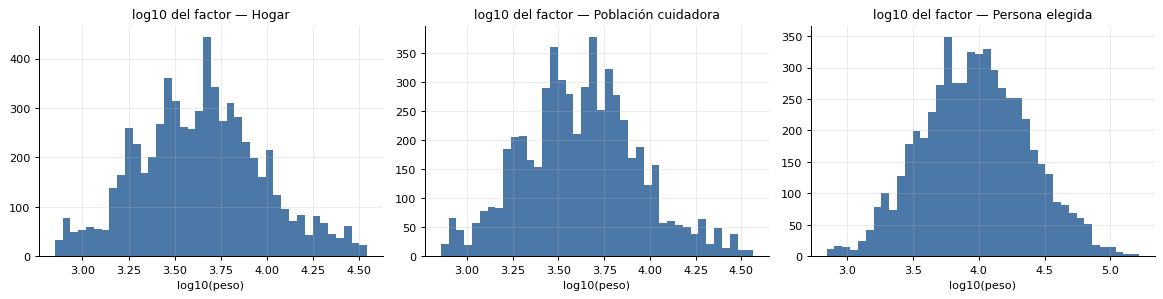

In [5]:
def kish_deff(w):
    w = np.asarray(w, float); return len(w) * (w ** 2).sum() / w.sum() ** 2

def razon(df, y, x=None, w='FAC', h='EST_DIS', c='UPM_DIS'):
    """Estimador de razón Σw·y / Σw·x con error estándar por linealización (estrato, UPM). Devuelve (R, SE)."""
    yv = df[y].astype(float).to_numpy(); xv = np.ones(len(df)) if x is None else df[x].astype(float).to_numpy()
    wv = df[w].to_numpy(float); den = (wv * xv).sum()
    R = (wv * yv).sum() / den; z = wv * (yv - R * xv) / den
    g = pd.DataFrame({'h': df[h].to_numpy(), 'c': df[c].to_numpy(), 'z': z}).groupby(['h', 'c']).z.sum().reset_index()
    var = 0.0
    for _, s in g.groupby('h'):
        n = len(s)
        if n > 1: var += n / (n - 1) * ((s.z - s.z.mean()) ** 2).sum()
    return R, np.sqrt(var)

dis = []
for k in E:
    d = E[k]; w = PESO[k]
    upm_por_est = d.groupby('EST_DIS').UPM_DIS.nunique()
    dis.append({'tabla': k, 'n': len(d), 'N_expandido(M)': d[w].sum() / 1e6, 'peso_min': d[w].min(), 'peso_mediana': d[w].median(),
                'peso_max': d[w].max(), 'CV_pesos': d[w].std() / d[w].mean(), 'deff_Kish': kish_deff(d[w]),
                'n_efectivo_por_pesos': len(d) / kish_deff(d[w]), 'estratos': d.EST_DIS.nunique(), 'UPM': d.UPM_DIS.nunique(),
                'estratos_con_1_UPM': int((upm_por_est == 1).sum()), 'UPM_min_por_estrato': int(upm_por_est.min())})
dis = pd.DataFrame(dis).set_index('tabla'); display(dis)

hh = E['res'].groupby('LLAVEHOG').FAC_HOG.nunique()
print('Residentes: hogares cuyo FAC_HOG no es único dentro del hogar:', int((hh > 1).sum()))
f_h = E['hog'].set_index('LLAVEHOG').FAC_HOG; f_r = E['res'].groupby('LLAVEHOG').FAC_HOG.first()
print('FAC_HOG igual entre tabla hogar y tabla residentes:', bool((f_h.reindex(f_r.index) == f_r).all()))
pob_ena = E['res'].FAC_HOG.sum()
imm = limpiar_cols(leer_csv(DATOS / 'conapo_marginacion' / 'imm_2020.csv'))
print(f"Población expandida por residentes ENASIC: {pob_ena/1e6:,.1f} M | suma POB_TOT municipal CONAPO 2020: {imm.POB_TOT.sum()/1e6:,.1f} M | razón {pob_ena/imm.POB_TOT.sum():.3f}")
print(f"Hogares expandidos ENASIC: {E['hog'].FAC_HOG.sum()/1e6:,.1f} M | tamaño medio ponderado del hogar: {pob_ena/E['hog'].FAC_HOG.sum():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for k, a in zip(['hog', 'cui', 'ele'], ax):
    a.hist(np.log10(E[k][PESO[k]]), bins=40, color='#4c78a8'); a.set_title(f'log10 del factor — {ENA_DESC[k]}'); a.set_xlabel('log10(peso)')
plt.tight_layout(); plt.show()

### 2.4 Catálogo completo de variables y calidad de datos

Se construye un catálogo de **todas** las variables de las seis tablas: etiqueta, tipo inferido, nulos, categorías, categoría modal ponderada y proporción de códigos “no sabe / no responde / no especificado”. Se guarda en `Analysis/eda_general/catalogo_variables_enasic.csv` (solo metadatos y agregados; sin microdatos).

In [6]:
def _k(v):
    try: return str(int(float(v)))
    except (ValueError, TypeError): return str(v)

NR = re.compile(r'no sabe|no responde|no especific|ns/nr|no aplica|no identific', re.I)
ESTRUCT = re.compile(r'^(LLAVE|UPM_DIS|EST_DIS|FAC_)')

def construir_catalogo():
    filas = []
    for k, df in E.items():
        w = PESO[k]
        for v in df.columns:
            if ESTRUCT.match(v): continue
            s = df[v]; ok = s.notna()
            cat = cat_de(k, v); mod = re.match(r'^(P\d+[A-Z]?)', v)
            f = {'tabla': k, 'var': v, 'modulo': mod.group(1) if mod else 'derivada/otra', 'etiqueta': etiqueta(k, v),
                 'catalogo': (DIC[k].loc[v, 'catalogo'] if v in DIC[k].index else None), 'n_valido': int(ok.sum()),
                 'pct_nulo': 100 * (1 - ok.mean()), 'n_unicos': s.nunique()}
            if ok.sum() == 0:
                f['tipo'] = 'vacía'
            else:
                vals = s[ok].map(_k)
                g = pd.Series(df.loc[ok, w].to_numpy(), index=vals.to_numpy()).groupby(level=0).sum()
                f['modal'] = g.idxmax(); f['pct_modal_pond'] = 100 * g.max() / g.sum()
                if cat:
                    desc = {c: cat.get(c, '?') for c in g.index}
                    ds = set(x.lower() for x in desc.values())
                    f['tipo'] = 'binaria Sí/No' if ds <= {'sí', 'si', 'no', 'no sabe', 'no responde', 'no especificado'} and ('sí' in ds or 'si' in ds) else 'categórica'
                    f['pct_sin_etiqueta'] = 100 * g[[c for c in g.index if c not in cat]].sum() / g.sum()
                    f['pct_nr'] = 100 * g[[c for c in g.index if NR.search(desc[c])]].sum() / g.sum()
                    f['modal_desc'] = cat.get(f['modal'], '?')
                    if f['pct_sin_etiqueta'] > 50:   # el catálogo solo lista códigos especiales (p. ej. 99 = no sabe): la variable es numérica
                        f['tipo'] = 'numérica con códigos especiales'
                else:
                    f['tipo'] = 'numérica/abierta' if pd.api.types.is_numeric_dtype(s) else 'texto'
            filas.append(f)
    return pd.DataFrame(filas)

CAT = construir_catalogo()
CAT.to_csv(SALIDA / 'catalogo_variables_enasic.csv', index=False, encoding='utf-8')
print('Variables catalogadas:', len(CAT))
display(CAT.groupby(['tabla', 'tipo']).size().unstack(fill_value=0))
display(CAT.groupby('tabla').agg(vars=('var', 'size'), pct_nulo_mediano=('pct_nulo', 'median'),
        vacias=('tipo', lambda x: (x == 'vacía').sum()), constantes=('n_unicos', lambda x: (x == 1).sum())))

Variables catalogadas: 1286


tipo,binaria Sí/No,categórica,numérica con códigos especiales,numérica/abierta,vacía
tabla,,,,,
cui,322,86,16,2,0
ele,162,94,7,6,0
hog,20,2,30,15,0
res,69,64,24,17,1
uni,207,92,8,1,1
viv,30,6,0,4,0


,vars,pct_nulo_mediano,vacias,constantes
tabla,,,,
cui,426,80.218,0,24
ele,269,45.223,0,2
hog,67,0.000,0,1
res,175,98.057,1,12
uni,309,56.142,1,43
viv,40,0.000,0,0


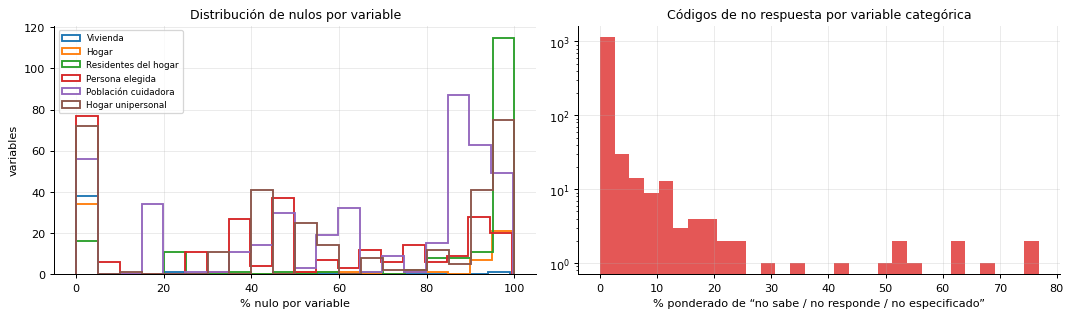

Variables con >15% de respuestas “no sabe/no responde/no especificado” (top 15):


,tabla,var,etiqueta,n_valido,pct_nr
1135,uni,P6_34A_3,¿Con cuánto la (lo) apoyan al mes?,4,76.794
1060,uni,P5_28_7,"En su lugar de trabajo, ¿le permiten tener tiempo de lactancia materna (llegar tarde o...",407,74.874
799,cui,P6_29_8,En la siguiente pregunta siéntase con la libertad de responder lo que piensa. Recuerde...,4599,67.735
702,cui,P6_10_8,"El cuidar a una persona puede afectar de diferentes maneras a la persona cuidadora, lo...",636,63.952
365,ele,P5_28_7,"En su lugar de trabajo, ¿le permiten tener tiempo de lactancia materna (llegar tarde o...",3081,63.082
634,cui,P5_28_7,"En su lugar de trabajo, ¿le permiten tener tiempo de lactancia materna (llegar tarde o...",2420,54.140
701,cui,P6_10_7,"El cuidar a una persona puede afectar de diferentes maneras a la persona cuidadora, lo...",636,52.320
1056,uni,P5_28_3,"En su lugar de trabajo, ¿le permiten tener a sus hijas o hijos en su lugar de trabajo?",407,51.396
1087,uni,P6_34A_1,¿Con cuánto la (lo) apoyan al mes?,4,51.117
798,cui,P6_29_7,En la siguiente pregunta siéntase con la libertad de responder lo que piensa. Recuerde...,4599,41.621



Categóricas con códigos en los datos que NO están en su catálogo (posible inconsistencia diccionario/datos):


,tabla,var,etiqueta,catalogo,pct_sin_etiqueta
1087,uni,P6_34A_1,¿Con cuánto la (lo) apoyan al mes?,p6_34a_1,48.883
303,ele,P5_14_1,"Considerando ida y vuelta, ¿cuánto tiempo hace regularmente de su casa a su lugar de t...",p5_14_1,47.129
998,uni,P5_14_1,"Considerando ida y vuelta, ¿cuánto tiempo hace regularmente de su casa a su lugar de t...",p5_14_1,45.035
572,cui,P5_14_1,"Considerando ida y vuelta, ¿cuánto tiempo hace regularmente de su casa a su lugar de t...",p5_14_1,40.066
217,res,P4_37,¿Cuánto pagan mensualmente por el horario extendido de la escuela de (NOMBRE)?,p4_37,39.549
163,res,P4_10,¿Cuánto pagan mensualmente?,p4_10,38.797
547,ele,CT_NHA,Condición de tenencia y número de hijas e hijos autodeclarados,cpea,37.236
134,res,P3_14,"¿Cuánto pagan mensualmente en la educación inicial, estancia, guardería, preescolar o ...",p3_14,35.506
238,res,P4_49,¿(NOMBRE) cuántas horas diarias se queda sola(o) en el hogar?,p4_49,34.143
166,res,P4_12,¿(NOMBRE) cuántas horas diarias se queda sola(o) en el hogar?,p4_12,28.249



Caso a vigilar: CT_NHA en tabla de persona elegida usa el catálogo cpea (el de actividad económica) aunque su etiqueta habla de hijas e hijos:
 etiqueta: Condición de tenencia y número de hijas e hijos autodeclarados | catálogo en cuidadoras: ct_nha
 categorías observadas en ele.CT_NHA: ['2', '3'] | catálogo cpea: {'1': 'Población económicamente activa', '2': 'Población no económicamente activa'}


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k in E:
    ax[0].hist(CAT[CAT.tabla == k].pct_nulo, bins=20, histtype='step', label=ENA_DESC[k], lw=1.5)
ax[0].set_xlabel('% nulo por variable'); ax[0].set_ylabel('variables'); ax[0].legend(fontsize=7); ax[0].set_title('Distribución de nulos por variable')
cc = CAT[CAT.tipo.isin(['categórica', 'binaria Sí/No', 'numérica con códigos especiales'])]
ax[1].hist(cc.pct_nr.dropna(), bins=30, color='#e45756'); ax[1].set_yscale('log'); ax[1].set_xlabel('% ponderado de “no sabe / no responde / no especificado”')
ax[1].set_title('Códigos de no respuesta por variable categórica'); plt.tight_layout(); plt.show()

print('Variables con >15% de respuestas “no sabe/no responde/no especificado” (top 15):')
display(cc.sort_values('pct_nr', ascending=False).head(15)[['tabla', 'var', 'etiqueta', 'n_valido', 'pct_nr']])
print('\nCategóricas con códigos en los datos que NO están en su catálogo (posible inconsistencia diccionario/datos):')
inc = CAT[CAT.tipo.isin(['categórica', 'binaria Sí/No']) & (CAT.pct_sin_etiqueta > 0)]
display(inc.sort_values('pct_sin_etiqueta', ascending=False)[['tabla', 'var', 'etiqueta', 'catalogo', 'pct_sin_etiqueta']].head(25) if len(inc) else 'Ninguna: todos los códigos observados tienen etiqueta.')
print('\nCaso a vigilar: CT_NHA en tabla de persona elegida usa el catálogo', DIC['ele'].loc['CT_NHA', 'catalogo'], '(el de actividad económica) aunque su etiqueta habla de hijas e hijos:')
print(' etiqueta:', DIC['ele'].loc['CT_NHA', 'etiqueta'], '| catálogo en cuidadoras:', DIC['cui'].loc['CT_NHA', 'catalogo'])
print(' categorías observadas en ele.CT_NHA:', sorted(E['ele'].CT_NHA.dropna().map(_k).unique()), '| catálogo cpea:', cat_de('ele', 'CT_NHA'))

**Estructura del cuestionario.** Las variables `P#_*` siguen los módulos del instrumento; los nulos masivos suelen ser *saltos de pregunta* (la pregunta solo aplica a un subuniverso), no datos faltantes. Distinguirlo exige conocer el filtro de cada pregunta: el diccionario público no lo trae completo, así que el % nulo **no** puede leerse como mala calidad sin revisar el flujo.

In [8]:
mods = (CAT.groupby(['tabla', 'modulo']).agg(vars=('var', 'size'), pct_nulo_mediano=('pct_nulo', 'median'), n_valido_max=('n_valido', 'max'),
        pregunta_ejemplo=('etiqueta', 'first')).reset_index())
mods['pregunta_ejemplo'] = mods.pregunta_ejemplo.str.slice(0, 95)
display(mods[mods.modulo != 'derivada/otra'].sort_values(['tabla', 'vars'], ascending=[True, False]))

,tabla,modulo,vars,pct_nulo_mediano,n_valido_max,pregunta_ejemplo
1,cui,P6,251,88.797,5677,(NOMBRE(S)) necesita(n) cuidados por las dificultades que tiene(n) para realizar disti...
0,cui,P5,100,59.908,5677,¿Usted habla algún dialecto o lengua indígena?
2,cui,P7,48,42.188,5677,"Cuando las hijas y los hijos son pequeños, están enfermos o no pueden valerse por sí m..."
4,ele,P5,100,47.984,5579,¿Usted habla algún dialecto o lengua indígena?
7,ele,P9,71,8.460,5579,"Durante su infancia y adolescencia, es decir hasta los 17 años (15 o 16 años), ¿quién ..."
6,ele,P7,48,38.233,5579,"Cuando las hijas y los hijos son pequeños, están enfermos o no pueden valerse por sí m..."
5,ele,P6,30,74.798,5579,¿Usted ha recibido algún tipo de capacitación o entrenamiento para brindar cuidados?
9,hog,P2,30,98.686,6508,¿En este hogar contratan trabajadoras(es) domésticas(os) de entrada por salida (o de v...
10,hog,P3A,26,0.000,6508,"En su hogar, ¿quién o quiénes participan en hacer reparaciones a su vivienda, muebles,..."
13,res,P4,127,98.512,16590,"La semana pasada a (NOMBRE), ¿alguna persona del hogar le dio de comer, la(o) bañó, vi..."


### 2.5 Verificaciones de coherencia básicas (edad, sexo, redondeo de edades)

In [9]:
for k in ['res', 'ele', 'cui', 'uni']:
    d = E[k]; print(f'{k:>3}: EDAD min={d.EDAD.min()} max={d.EDAD.max()} nulos={d.EDAD.isna().sum()} | SEXO códigos={sorted(d.SEXO.dropna().map(_k).unique())}')
print('\nCatálogo de SEXO (res):', cat_de('res', 'SEXO'))
SEXO = cat_de('res', 'SEXO') or {'1': 'Hombre', '2': 'Mujer'}

def whipple(edad, w):
    """Índice de Whipple (ponderado) en 23–62 años: 100 = sin preferencia por edades terminadas en 0 o 5; 500 = extrema."""
    m = (edad >= 23) & (edad <= 62); e = edad[m]; ww = w[m]
    return 500 * ww[(e % 5 == 0)].sum() / ww.sum()
wh = pd.DataFrame({k: {'Whipple': whipple(E[k].EDAD.to_numpy(float), E[k][PESO[k]].to_numpy()),
                       'pct_edad_terminada_0_5': 100 * (E[k].EDAD.mod(5) == 0).mean()} for k in ['res', 'ele', 'cui', 'uni']}).T
display(wh)
print('Referencia: 100 = sin redondeo; <105 “muy preciso”; 105–110 “preciso”; >110 hay preferencia por dígitos.')

res: EDAD min=0 max=99 nulos=0 | SEXO códigos=['1', '2']
ele: EDAD min=15 max=60 nulos=0 | SEXO códigos=['1', '2']
cui: EDAD min=15 max=98 nulos=0 | SEXO códigos=['1', '2']
uni: EDAD min=18 max=97 nulos=0 | SEXO códigos=['1', '2']

Catálogo de SEXO (res): {'1': 'Hombre', '2': 'Mujer'}


,Whipple,pct_edad_terminada_0_5
res,113.967,22.089
ele,119.376,23.194
cui,109.534,21.561
uni,104.461,22.414


Referencia: 100 = sin redondeo; <105 “muy preciso”; 105–110 “preciso”; >110 hay preferencia por dígitos.


### 2.6 Utilidades de estimación y primera mirada poblacional

`dist()` devuelve distribuciones ponderadas con IC 95 % (linealización por estrato/UPM). Con sub-poblaciones se estima por **dominio** (no se filtran los datos antes de calcular el error).

In [10]:
def dist(k, var, dom=None, etiquetar=True, top=None, min_n=0):
    """Distribución ponderada de `var` en la tabla k (opcional: dominio booleano `dom`). Devuelve %, SE e IC95."""
    d = E[k].copy(); w = PESO[k]
    d['_d'] = 1.0 if dom is None else np.asarray(dom, float)
    ok = d[var].notna().astype(float) * d['_d']; d['_ok'] = ok
    cat = cat_de(k, var) if etiquetar else None
    filas = []
    for c in sorted(d.loc[ok > 0, var].map(_k).unique(), key=lambda x: (len(x), x)):
        d['_y'] = ((d[var].map(_k) == c).astype(float) * ok)
        n = int(d._y.sum())
        R, se = razon(d, '_y', '_ok', w=w)
        filas.append({'codigo': c, 'categoria': (cat or {}).get(c, ''), 'n': n, 'pct': 100 * R, 'se': 100 * se,
                      'ic95_inf': 100 * (R - 1.96 * se), 'ic95_sup': 100 * (R + 1.96 * se)})
    r = pd.DataFrame(filas)
    if min_n: r = r[r.n >= min_n]
    return r.sort_values('pct', ascending=False).head(top) if top else r

def prop(k, var, valor, dom=None):
    """% ponderado de var==valor entre válidos (y dentro de dom). Devuelve (pct, se, n_valido)."""
    d = E[k].copy(); w = PESO[k]
    d['_d'] = 1.0 if dom is None else np.asarray(dom, float)
    d['_ok'] = d[var].notna().astype(float) * d['_d']; d['_y'] = (d[var].map(_k) == str(valor)).astype(float) * d._ok
    if d._ok.sum() == 0: return np.nan, np.nan, 0
    R, se = razon(d, '_y', '_ok', w=w); return 100 * R, 100 * se, int(d._ok.sum())

print('SEXO en residentes (población expandida):'); display(dist('res', 'SEXO'))

SEXO en residentes (población expandida):


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
0,1,Hombre,10445,47.782,0.364,47.069,48.496
1,2,Mujer,11331,52.218,0.364,51.504,52.931


### 2.7 Residentes del hogar: pirámide, parentesco, escolaridad

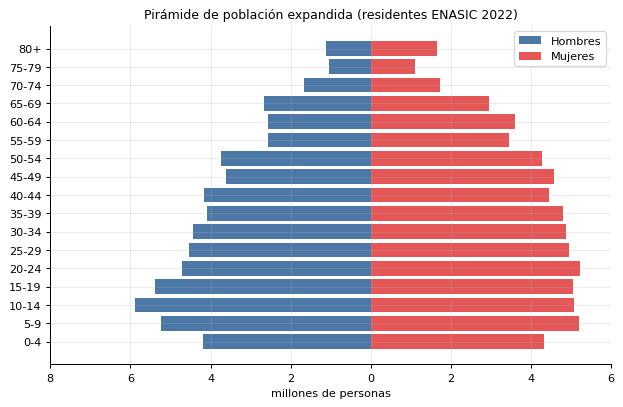

Índice de masculinidad ponderado: 91.5 hombres por 100 mujeres | mediana de edad ponderada: 32

Parentesco con el jefe/a (PAREN):


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
2,3,Hija(o),8019,36.512,0.415,35.698,37.327
0,1,Jefa(e),6508,30.100,0.323,29.467,30.733
1,2,Esposa(o) o compañera(o),3966,18.066,0.241,17.594,18.538
3,4,Nieta(o),1666,7.801,0.318,7.177,8.425
8,9,Otro (ESPECIFIQUE),664,2.888,0.226,2.445,3.331
4,5,Nuera o yerno,403,1.918,0.133,1.657,2.179
5,6,Hermana(o) o cuñada(o),258,1.329,0.139,1.056,1.602
6,7,Madre o padre,210,1.018,0.099,0.824,1.212
7,8,Suegra (o),82,0.368,0.051,0.268,0.469


Nivel de escolaridad (NIV) — universo: todos los residentes con dato:


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
0,0,Ninguno,1226,5.810,0.264,5.292,6.328
1,1,Preescolar o kinder,910,4.326,0.182,3.970,4.682
2,2,Primaria,5689,27.449,0.546,26.378,28.519
3,3,Secundaria,5192,24.560,0.449,23.679,25.441
4,4,Normal básica,39,0.141,0.029,0.084,0.198
5,5,Carrera técnica con secundaria terminada,340,1.560,0.130,1.305,1.815
6,6,Preparatoria o bachillerato,3552,16.837,0.395,16.063,17.612
7,7,Carrera técnica con preparatoria terminada,325,1.765,0.135,1.501,2.030
8,8,Licenciatura o ingeniería (profesional),3256,15.540,0.488,14.584,16.496
9,9,Especialidad,57,0.203,0.046,0.113,0.293


In [11]:
r = E['res'].copy(); r['sexo'] = r.SEXO.map(_k).map(SEXO)
bins = list(range(0, 85, 5)) + [200]; labs = [f'{a}-{a+4}' for a in range(0, 80, 5)] + ['80+']
r['gedad'] = pd.cut(r.EDAD, bins=bins, right=False, labels=labs)
pir = r.groupby(['gedad', 'sexo']).FAC_HOG.sum().unstack() / 1e6
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(pir.index.astype(str), -pir['Hombre'], color='#4c78a8', label='Hombres'); ax.barh(pir.index.astype(str), pir['Mujer'], color='#e45756', label='Mujeres')
ax.set_xlabel('millones de personas'); ax.set_title('Pirámide de población expandida (residentes ENASIC 2022)'); ax.legend()
ax.set_xticks(ax.get_xticks()); ax.set_xticklabels([f'{abs(x):.0f}' for x in ax.get_xticks()]); plt.tight_layout(); plt.show()
razon_sexos = 100 * pir['Hombre'].sum() / pir['Mujer'].sum()
print(f'Índice de masculinidad ponderado: {razon_sexos:.1f} hombres por 100 mujeres | mediana de edad ponderada: ', end='')
o = r.sort_values('EDAD'); cw = o.FAC_HOG.cumsum() / o.FAC_HOG.sum(); print(int(o.EDAD[cw >= .5].iloc[0]))
print('\nParentesco con el jefe/a (PAREN):'); display(dist('res', 'PAREN').sort_values('pct', ascending=False).head(12))
print('Nivel de escolaridad (NIV) — universo: todos los residentes con dato:'); display(dist('res', 'NIV'))

### 2.8 Hogares: tamaño, jefatura y necesidad de cuidados (variables derivadas HN_*)

In [12]:
h = E['hog']
hn = [c for c in h.columns if c.startswith('HN_')] + ['HOG_UNI']
filas = []
for c in hn:
    cat = cat_de('hog', c) or {}
    for val, desc in cat.items():
        if re.match(r's[ií]', desc, re.I):
            p, se, n = prop('hog', c, val); filas.append({'var': c, 'etiqueta': etiqueta('hog', c), 'pct_hogares_Si': p, 'se': se, 'ic95_inf': p - 1.96 * se, 'ic95_sup': p + 1.96 * se, 'n': n})
display(pd.DataFrame(filas))
print('Catálogo HN_CDISC:', cat_de('hog', 'HN_CDISC'))
print('\nSexo de jefatura:'); display(dist('hog', 'SEXO_JEFE'))
print('Edad de la jefatura (ponderada):', h.groupby(pd.cut(h.EDAD_JEFE, [0, 29, 44, 59, 74, 120])).FAC_HOG.sum().div(h.FAC_HOG.sum()).mul(100).round(1).to_dict())
tam = E['res'].groupby('LLAVEHOG').size().rename('tam').reset_index().merge(h[['LLAVEHOG', 'FAC_HOG']], on='LLAVEHOG')
print('Tamaño del hogar (residentes listados), distribución ponderada:'); print((tam.groupby(tam.tam.clip(upper=8)).FAC_HOG.sum() / tam.FAC_HOG.sum() * 100).round(1).to_dict())

# Necesidad de cuidados por tipo de jefatura (dominio): ¿es mayor en hogares con jefatura femenina?
jef = h.SEXO_JEFE.map(_k).map(cat_de('hog', 'SEXO_JEFE') or {})
filas = []
for c in [x for x in hn if x.startswith('HN_') and x != 'HN_CSINETEM']:
    sic = [k for k, v in (cat_de('hog', c) or {}).items() if re.match(r's[ií]', v, re.I)][0]
    row = {'necesidad': etiqueta('hog', c)}
    for g in sorted(jef.dropna().unique()):
        p, se, n = prop('hog', c, sic, dom=(jef == g)); row[f'{g} %'] = p; row[f'{g} ±'] = 1.96 * se
    filas.append(row)
display(pd.DataFrame(filas))

,var,etiqueta,pct_hogares_Si,se,ic95_inf,ic95_sup,n
0,HN_C,Hogar que necesita cuidados,78.099,0.675,76.776,79.422,6508
1,HN_CDISC,Hogar que necesita cuidados por discapacidad,12.743,0.515,11.733,13.754,6508
2,HN_C0005,Hogar que necesita cuidados niños(as) 00-05,21.550,0.736,20.108,22.992,6508
3,HN_C0617,Hogar que necesita cuidados niños - adolescentes 06-17,40.816,0.958,38.938,42.694,6508
4,HN_C60MA,Hogar que necesita cuidados adultos 60 y más,31.969,0.991,30.027,33.911,6508
5,HN_CETEM,Hogar que necesita cuidados enfermos temporales,1.665,0.192,1.290,2.041,6508
6,HN_CSINETEM,Hogar que necesita cuidados sin enfermos temporales,77.810,0.681,76.476,79.145,6508


Catálogo HN_CDISC: {'1': 'Sí', '2': 'No'}

Sexo de jefatura:


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
0,1,Hombre,4278,65.330,0.865,63.633,67.026
1,2,Mujer,2230,34.670,0.865,32.974,36.367


Edad de la jefatura (ponderada): {Interval(0, 29, closed='right'): 8.2, Interval(29, 44, closed='right'): 28.3, Interval(44, 59, closed='right'): 31.6, Interval(59, 74, closed='right'): 23.9, Interval(74, 120, closed='right'): 7.9}
Tamaño del hogar (residentes listados), distribución ponderada:
{1: 14.8, 2: 21.4, 3: 20.0, 4: 21.0, 5: 13.6, 6: 5.1, 7: 2.2, 8: 1.9}


,necesidad,Hombre %,Hombre ±,Mujer %,Mujer ±
0,Hogar que necesita cuidados,78.138,1.469,78.025,2.437
1,Hogar que necesita cuidados por discapacidad,11.757,1.228,14.601,1.816
2,Hogar que necesita cuidados niños(as) 00-05,23.681,1.952,17.534,1.832
3,Hogar que necesita cuidados niños - adolescentes 06-17,41.412,2.432,39.692,2.855
4,Hogar que necesita cuidados adultos 60 y más,31.395,2.451,33.051,2.824
5,Hogar que necesita cuidados enfermos temporales,1.688,0.450,1.623,0.672


### 2.9 Población cuidadora (`tpob_cui`): quién cuida, cuánto y a quién

Universo: personas de 15+ que cuidan en el hogar (31.7 M expandidas según §2.3). Las variables `PB_*` indican a qué tipo de población cuidan; pueden **solaparse** (una persona cuida a un menor *y* a un adulto mayor).

In [13]:
c = E['cui'].copy(); c['sexo'] = c.SEXO.map(_k).map(SEXO)
print('Sexo de las personas cuidadoras:'); display(dist('cui', 'SEXO'))
for v in ['CPEA', 'CT_NHA']:
    print(f'\n{v} — {etiqueta("cui", v)}:'); display(dist('cui', v))
print('\nOjo: el catálogo de CT_NHA (hijas/hijos) trae las etiquetas de actividad económica y deja sin etiqueta el código 3 → CT_NHA no es interpretable solo con el diccionario público [confirmada]; se requiere el documento metodológico de INEGI [desconocida].')
def marca(k, var, dom=None):
    """Variables “marca”: solo traen código 1 para quienes cumplen la condición y vienen vacías para el resto.
    % ponderado sobre TODAS las filas (vacío = no cumple). Devuelve (pct, se, n_marcados)."""
    d = E[k].copy(); d['_y'] = (d[var].map(_k) == '1').astype(float); d['_x'] = 1.0 if dom is None else np.asarray(dom, float); d['_y'] *= d._x
    R, se = razon(d, '_y', '_x', w=PESO[k]); return 100 * R, 100 * se, int(d._y.sum())

print('\nTipo de población que cuidan (PB_*): variables marca; % ponderado sobre todas las personas cuidadoras')
filas = []
for v in ['PB_CDISC', 'PB_C0005', 'PB_C0617', 'PB_C60MA', 'PB_CETEM']:
    print(f'   {v}: valores observados', c[v].map(_k).value_counts(dropna=False).to_dict())
    p, se, n = marca('cui', v); filas.append({'var': v, 'etiqueta': etiqueta('cui', v), 'pct': p, 'ic95_inf': p - 1.96 * se, 'ic95_sup': p + 1.96 * se, 'n_marcadas': n})
display(pd.DataFrame(filas))
pb = [v for v in ['PB_CDISC', 'PB_C0005', 'PB_C0617', 'PB_C60MA', 'PB_CETEM'] if v in c]
M = pd.DataFrame({v: (c[v].map(_k) == '1') for v in pb})
c['n_tipos'] = M.sum(axis=1)
print('\nNúmero de tipos de población cuidada por persona (ponderado, %):', (c.groupby('n_tipos').FAC_CUI.sum() / c.FAC_CUI.sum() * 100).round(1).to_dict())
comb = M.apply(lambda r: '+'.join(x.replace('PB_C', '') for x in pb if r[x]) or 'ninguno', axis=1)
print('Combinaciones más frecuentes (ponderado, %):'); print((c.groupby(comb).FAC_CUI.sum() / c.FAC_CUI.sum() * 100).sort_values(ascending=False).head(10).round(1))

Sexo de las personas cuidadoras:


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
0,1,Hombre,1504,24.907,0.634,23.664,26.150
1,2,Mujer,4173,75.093,0.634,73.850,76.336



CPEA — Condición de actividad económica:


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
0,1,Población económicamente activa,3648,61.543,1.000,59.583,63.502
1,2,Población no económicamente activa,2029,38.457,1.000,36.498,40.417



CT_NHA — Condición de tenencia y número de hijas e hijos:


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
0,2,Población no económicamente activa,4996,88.853,0.579,87.718,89.988
1,3,,681,11.147,0.579,10.012,12.282


... (2 outputs left out)

   PB_C60MA: valores observados {'nan': 5245, '1': 432}
   PB_CETEM: valores observados {'nan': 5552, '1': 125}


,var,etiqueta,pct,ic95_inf,ic95_sup,n_marcadas
0,PB_CDISC,Cuidados discapacidad y/o dependencia,11.100,9.848,12.351,636
1,PB_C0005,Condición de cuidados de 0 a 5 años,36.281,34.028,38.534,2076
2,PB_C0617,Condición de cuidados de 6 a 17 años,53.335,50.912,55.757,3011
3,PB_C60MA,Condición de cuidados 60 años y más sin discapacidad y/o dependencia,9.216,7.125,11.307,432
4,PB_CETEM,Condición de cuidados enfermos temporales,1.886,1.408,2.364,125



Número de tipos de población cuidada por persona (ponderado, %): {0: 10.4, 1: 68.9, 2: 19.3, 3: 1.4, 4: 0.0}


Combinaciones más frecuentes (ponderado, %):
0617             34.500
0005             19.700
0005+0617        14.300
ninguno          10.400
DISC              7.700
60MA              6.400
DISC+0617         1.700
0617+60MA         1.100
ETEM              0.600
DISC+0005+0617    0.500
Name: FAC_CUI, dtype: float64


,% de la población 15+,% de las personas cuidadoras
Hombre,46.752,24.907
Mujer,53.248,75.093


Mujeres entre cuidadoras: 75.1% (IC95 73.8–76.3)


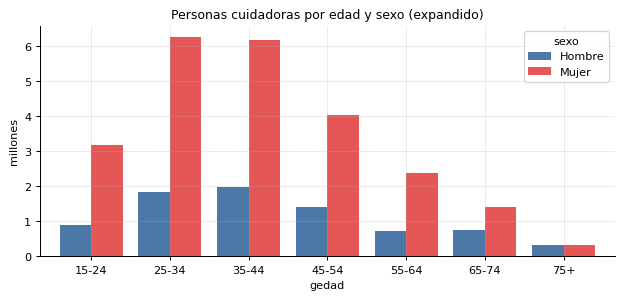


P6_7: En promedio, ¿cuántas horas a la semana dedica de manera exclusiva al cuidado de (NOMBRE(S))?
   válidos=636  min=1.0  p50=21.0  p90=70.0  max=98.0  | valores >168 (imposibles como horas/semana): 0

P6_26: En promedio, ¿cuántas horas a la semana dedica de manera exclusiva al cuidado de (NOMBRE(S))?
   válidos=4599  min=1.0  p50=28.0  p90=70.0  max=98.0  | valores >168 (imposibles como horas/semana): 0

P6_6_1: ¿Cuánto tiempo lleva cuidando a (NOMBRE(S))? - AÑOS
   válidos=636  min=0.0  p50=5.0  p90=20.0  max=99.0  | valores >168 (imposibles como horas/semana): 0

P6_6_2: ¿Cuánto tiempo lleva cuidando a (NOMBRE(S))? - MESES
   válidos=636  min=0.0  p50=0.0  p90=5.0  max=99.0  | valores >168 (imposibles como horas/semana): 0


In [14]:
# Edad y sexo de quienes cuidan vs. población general (¿quién carga con el cuidado?)
r15 = E['res'][E['res'].EDAD >= 15]
sh_pob = (r15.groupby('SEXO').FAC_HOG.sum() / r15.FAC_HOG.sum() * 100).rename('% de la población 15+')
sh_cui = (c.groupby('SEXO').FAC_CUI.sum() / c.FAC_CUI.sum() * 100).rename('% de las personas cuidadoras')
sh = pd.concat([sh_pob, sh_cui], axis=1); sh.index = [SEXO[_k(i)] for i in sh.index]; display(sh)
p_m, se_m, _ = prop('cui', 'SEXO', 2); print(f'Mujeres entre cuidadoras: {p_m:.1f}% (IC95 {p_m-1.96*se_m:.1f}–{p_m+1.96*se_m:.1f})')

c['gedad'] = pd.cut(c.EDAD, [14, 24, 34, 44, 54, 64, 74, 120], labels=['15-24', '25-34', '35-44', '45-54', '55-64', '65-74', '75+'])
pir = c.groupby(['gedad', 'sexo']).FAC_CUI.sum().unstack() / 1e6
ax = pir.plot.bar(figsize=(7, 3.4), color=['#4c78a8', '#e45756'], width=.8); ax.set_ylabel('millones'); ax.set_title('Personas cuidadoras por edad y sexo (expandido)'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# Horas semanales de cuidado exclusivo y duración del rol
for v in ['P6_7', 'P6_26', 'P6_6_1', 'P6_6_2']:
    if v in c:
        s = c[v]; print(f'\n{v}: {etiqueta("cui", v)[:100]}\n   válidos={s.notna().sum()}  min={s.min()}  p50={s.median()}  p90={s.quantile(.9)}  max={s.max()}  | valores >168 (imposibles como horas/semana): {(s > 168).sum()}')

P6_7: horas/semana dedicadas de forma exclusiva al cuidado de la persona principal (cuidadoras con dato)
  n = 636 | cuantiles ponderados: {'p10': 7.0, 'p25': 12.0, 'p50': 25.0, 'p75': 49.0, 'p90': 70.0}


,sexo,n,media_pond,p10,p25,p50,p75,p90,pct_>=40h,pct_>=84h
0,Hombre,184,29.259,7.000,12.000,21.000,42.000,68.000,28.243,6.179
1,Mujer,452,33.889,7.000,14.000,28.000,49.000,70.000,34.871,6.584


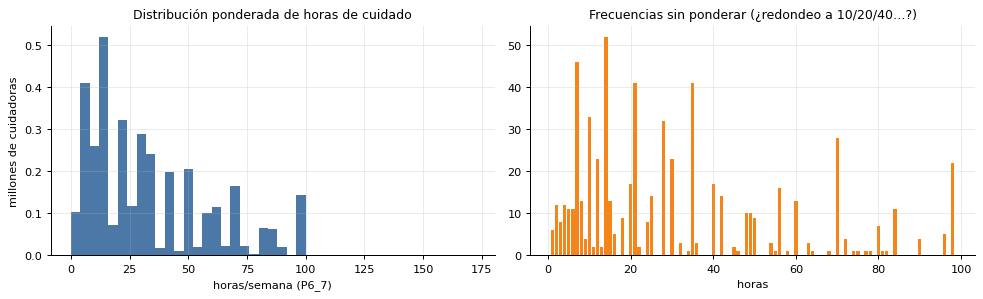

Horas redondeadas: % de respuestas en múltiplos de 10: 23.7 | en múltiplos de 5: 36.8


In [15]:
def cuantiles_pond(x, w, qs=(.1, .25, .5, .75, .9)):
    o = np.argsort(x); x, w = np.asarray(x)[o], np.asarray(w)[o]; cw = np.cumsum(w) / w.sum()
    return {f'p{int(q*100)}': float(x[np.searchsorted(cw, q)]) for q in qs}

horas = c[c.P6_7.notna() & (c.P6_7 <= 168)].copy()
print('P6_7: horas/semana dedicadas de forma exclusiva al cuidado de la persona principal (cuidadoras con dato)')
print('  n =', len(horas), '| cuantiles ponderados:', cuantiles_pond(horas.P6_7, horas.FAC_CUI))
tabla = []
for g, d in horas.groupby('sexo'):
    tabla.append({'sexo': g, 'n': len(d), 'media_pond': np.average(d.P6_7, weights=d.FAC_CUI), **cuantiles_pond(d.P6_7, d.FAC_CUI),
                  'pct_>=40h': 100 * d.FAC_CUI[d.P6_7 >= 40].sum() / d.FAC_CUI.sum(), 'pct_>=84h': 100 * d.FAC_CUI[d.P6_7 >= 84].sum() / d.FAC_CUI.sum()})
display(pd.DataFrame(tabla))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(horas.P6_7.clip(upper=168), bins=np.arange(0, 175, 4), weights=horas.FAC_CUI / 1e6, color='#4c78a8'); ax[0].set_xlabel('horas/semana (P6_7)'); ax[0].set_ylabel('millones de cuidadoras'); ax[0].set_title('Distribución ponderada de horas de cuidado')
vc = horas.P6_7.round().value_counts().sort_index(); ax[1].bar(vc.index[:100], vc.values[:100], color='#f58518'); ax[1].set_title('Frecuencias sin ponderar (¿redondeo a 10/20/40…?)'); ax[1].set_xlabel('horas'); plt.tight_layout(); plt.show()
print('Horas redondeadas: % de respuestas en múltiplos de 10:', round(100 * (horas.P6_7 % 10 == 0).mean(), 1), '| en múltiplos de 5:', round(100 * (horas.P6_7 % 5 == 0).mean(), 1))

### 2.10 Persona elegida (`tper_ele`, 15–60 años) y hogares unipersonales

La persona elegida responde un módulo más largo (trabajo, cuidados recibidos/dados, corresponsabilidad, normas). Su universo es **15–60 años** por diseño: no sirve para describir a personas de 61+ que cuidan.

In [16]:
e = E['ele']
for v in ['CUIDADOS', 'COND_DISC', 'CPEA', 'NIVEL']:
    print(f'\n{v} — {etiqueta("ele", v)} (tper_ele):'); display(dist('ele', v))
print('\nHogar unipersonal (thog_unip): sexo, y condición de cuidado a/de otros hogares')
for v in ['SEXO', 'COND_DISC']:
    print(f'\n{v} — {etiqueta("uni", v)}:'); display(dist('uni', v))
for v in ['CC_OH', 'CR_COH']:
    p, se, n = marca('uni', v); print(f'{v} — {etiqueta("uni", v)}: {p:.1f}% (IC95 {p-1.96*se:.1f}–{p+1.96*se:.1f}), n marcadas = {n}')
print('Edad de personas en hogar unipersonal (ponderada):', (E['uni'].groupby(pd.cut(E['uni'].EDAD, [17, 29, 44, 59, 74, 120])).FAC_UNI.sum() / E['uni'].FAC_UNI.sum() * 100).round(1).to_dict())


CUIDADOS — Cuidados (tper_ele):


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
0,1,Si realizó cuidados,2283,34.399,0.861,32.711,36.087
1,2,No realizó cuidados,3296,65.601,0.861,63.913,67.289



COND_DISC — Condición de discapacidad y/o dependencia (tper_ele):


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
0,1,Sí,159,2.537,0.272,2.004,3.070
1,2,No,5420,97.463,0.272,96.930,97.996



CPEA — Condición de actividad económica (tper_ele):


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
0,1,Población económicamente activa,4145,70.998,0.947,69.141,72.854
1,2,Población no económicamente activa,1434,29.002,0.947,27.146,30.859


... (4 outputs left out)


COND_DISC — Condición de discapacidad y/o dependencia:


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
0,1,Sí,91,9.453,1.311,6.883,12.022
1,2,No,837,90.547,1.311,87.978,93.117


CC_OH — Condición de cuidados a otros hogares: 11.2% (IC95 8.6–13.8), n marcadas = 120


CR_COH — Condición de recibir cuidados de otros hogares: 9.9% (IC95 7.6–12.2), n marcadas = 102
Edad de personas en hogar unipersonal (ponderada): {Interval(17, 29, closed='right'): 9.4, Interval(29, 44, closed='right'): 19.1, Interval(44, 59, closed='right'): 27.6, Interval(59, 74, closed='right'): 32.2, Interval(74, 120, closed='right'): 11.7}


### 2.11 Validación: ¿los microdatos reproducen las cifras publicadas que el repo transcribió a mano?

`enasic_2022_cifras_presentacion.csv` se transcribió a mano de la presentación de INEGI. Aquí se intentan reproducir con los microdatos las cifras para las que existe una variable evidente. Que coincida **no** valida el resto de la tabla; que no coincida obliga a revisar la transcripción o el universo.

In [17]:
pub = limpiar_cols(leer_csv(DATOS / 'enasic_2022_cifras_presentacion.csv'))

def sino(k, var, dom=None, patron=r's[ií]'):
    cat = cat_de(k, var) or {}; code = [kk for kk, vv in cat.items() if re.match(patron, vv, re.I)][0]
    return prop(k, var, code, dom=dom)

def pub_val(indicador_re, categoria_re, universo_re='.'):
    m = pub[pub.indicador.str.contains(indicador_re, case=False, regex=True) & pub.categoria.str.contains(categoria_re, case=False, regex=True) & pub.universo.str.contains(universo_re, case=False, regex=True)]
    return float(m.valor.iloc[0]) if len(m) else np.nan

# (a) hogares que contrataron trabajo doméstico: P2_4_1 (entrada por salida) o P2_4_2 (de planta)
h = E['hog'].copy(); si = lambda v: (h[v].map(_k) == [kk for kk, vv in cat_de('hog', v).items() if vv.lower().startswith('s')][0]).astype(float)
h['_dom'] = ((si('P2_4_1') + si('P2_4_2')) > 0).astype(float); h['_enf'] = ((si('P2_4_3') + si('P2_4_4')) > 0).astype(float)
res = []
for nom, col, pubv in [('Hogares con trabajo doméstico contratado (P2_4_1 ó P2_4_2)', '_dom', pub_val('Contrató personal', 'Trabajo doméstico')),
                       ('Hogares con enfermería/cuidadora contratada (P2_4_3 ó P2_4_4)', '_enf', pub_val('Contrató personal', 'Enfermería'))]:
    h['_x'] = 1.0; R, se = razon(h, col, '_x', w='FAC_HOG'); res.append({'indicador': nom, 'microdatos_%': 100 * R, 'ic95_inf': 100 * (R - 1.96 * se), 'ic95_sup': 100 * (R + 1.96 * se), 'publicado_%': pubv})

# (b) personas con discapacidad/dependencia que asisten a institución (P4_9) — universo exacto por confirmar
p, se, n = sino('res', 'P4_9'); res.append({'indicador': 'Asiste a institución/centro (P4_9, universo: quienes la contestan)', 'microdatos_%': p, 'ic95_inf': p - 1.96 * se, 'ic95_sup': p + 1.96 * se, 'publicado_%': pub_val('Asiste a un centro', 'S[ií]')})
# (c) 0–5 años que no asisten: razón “no tiene necesidad, está pequeño” (P3_11)
cat = cat_de('res', 'P3_11'); code = [kk for kk, vv in cat.items() if 'pequeño' in vv.lower()][0]
p, se, n = prop('res', 'P3_11', code); res.append({'indicador': 'No asiste a educación inicial: “no tiene necesidad, está pequeño” (P3_11)', 'microdatos_%': p, 'ic95_inf': p - 1.96 * se, 'ic95_sup': p + 1.96 * se, 'publicado_%': pub_val('Raz[oó]n de no asistencia', 'necesidad')})
# (d) mujeres 15–60 que desean trabajar y no lo hacen: “no tiene quién cuide” (P5_30, tper_ele)
cat = cat_de('ele', 'P5_30'); code = [kk for kk, vv in cat.items() if 'quién le cuide' in vv.lower()][0]
muj = (E['ele'].SEXO.map(_k) == '2'); cuida = (E['ele'].CUIDADOS.map(_k) == '1')
p, se, n = prop('ele', 'P5_30', code, dom=muj & cuida); res.append({'indicador': 'Mujeres cuidadoras 15–60 que desean trabajar y no lo hacen: no tiene quién cuide (P5_30, dominio: mujeres con CUIDADOS=1)', 'microdatos_%': p, 'ic95_inf': p - 1.96 * se, 'ic95_sup': p + 1.96 * se, 'publicado_%': pub_val('Motivo', 'No tiene qui[eé]n cuide')})
val = pd.DataFrame(res); val['diferencia_pp'] = val['microdatos_%'] - val['publicado_%']
val['publicado_dentro_IC95'] = (val['publicado_%'] >= val.ic95_inf) & (val['publicado_%'] <= val.ic95_sup)
display(val)

,indicador,microdatos_%,ic95_inf,ic95_sup,publicado_%,diferencia_pp,publicado_dentro_IC95
0,Hogares con trabajo doméstico contratado (P2_4_1 ó P2_4_2),6.785,5.799,7.770,6.800,-0.015,True
1,Hogares con enfermería/cuidadora contratada (P2_4_3 ó P2_4_4),0.683,0.439,0.928,0.800,-0.117,True
2,"Asiste a institución/centro (P4_9, universo: quienes la contestan)",3.253,1.818,4.687,3.300,-0.047,True
3,"No asiste a educación inicial: “no tiene necesidad, está pequeño” (P3_11)",80.509,77.250,83.769,82.200,-1.691,True
4,Mujeres cuidadoras 15–60 que desean trabajar y no lo hacen: no tiene quién cuide (P5_3...,68.342,60.932,75.752,68.400,-0.058,True


**El universo importa más que la variable.** La última fila reproduce el 68.4 % solo si el dominio son las *mujeres que realizaron cuidados* (`CUIDADOS = 1`). Con todas las mujeres con respuesta sale ~39 %. La tabla siguiente muestra la sensibilidad al universo: es la clase de error que una transcripción sin universo explícito no puede detectar.

In [18]:
cat = cat_de('ele', 'P5_30'); print('Categorías de P5_30:', cat)
code = [kk for kk, vv in cat.items() if 'quién le cuide' in vv.lower()][0]
muj = (E['ele'].SEXO.map(_k) == '2'); cuida = (E['ele'].CUIDADOS.map(_k) == '1')
alt = []
for nombre, dom in [('Mujeres con P5_30 válida (universo usado)', muj), ('Mujeres que realizaron cuidados', muj & cuida), ('Mujeres que NO realizaron cuidados', muj & ~cuida),
                    ('Hombres', ~muj), ('Todas las personas elegidas', pd.Series(True, index=E['ele'].index))]:
    p, se, n = prop('ele', 'P5_30', code, dom=dom); alt.append({'universo': nombre, 'pct_no_tiene_quien_cuide': p, 'ic95_inf': p - 1.96 * se, 'ic95_sup': p + 1.96 * se, 'n_validos': n})
display(pd.DataFrame(alt))
print('Distribución completa de P5_30 entre mujeres:'); display(dist('ele', 'P5_30', dom=muj))
print('Lectura: el universo “mujeres que realizaron cuidados” da 68.3 % (IC95 60.9–75.8), compatible con el 68.4 % publicado; con todas las mujeres con respuesta, 39.0 %. [confirmada] La etiqueta del CSV (“mujeres cuidadoras 15-60”) es correcta; el riesgo está en reutilizar la cifra con otro denominador.')

Categorías de P5_30: {'1': 'Está esperando la respuesta a una solicitud o está apalabrado con un patrón que lo llamará en fecha próxima', '2': 'No hay trabajo en su especialidad, oficio o profesión', '3': 'No cuenta con la escolaridad, los papeles o la experiencia necesaria para realizar un trabajo', '4': 'Piensa que por su edad o por su aspecto no lo aceptarían en un trabajo', '5': 'En su localidad no hay trabajo o solo se realiza en ciertas temporadas del año', '6': 'La inseguridad pública o el exceso de trámites lo desalientan a iniciar una actividad', '7': 'Espera recuperarse de una enfermedad o accidente', '8': 'Está embarazada', '9': 'No tiene quién le cuide a sus hijas(os), personas adultas mayores o personas enfermas', '10': 'No la(o) deja un familiar', '11': 'Otras razones de mercado', '12': 'Otras razones personales'}


,universo,pct_no_tiene_quien_cuide,ic95_inf,ic95_sup,n_validos
0,Mujeres con P5_30 válida (universo usado),39.030,33.089,44.972,466
1,Mujeres que realizaron cuidados,68.342,60.932,75.752,287
2,Mujeres que NO realizaron cuidados,4.213,0.549,7.877,179
3,Hombres,1.990,-0.150,4.130,109
4,Todas las personas elegidas,31.674,26.451,36.897,575


Distribución completa de P5_30 entre mujeres:


,codigo,categoria,n,pct,se,ic95_inf,ic95_sup
0,1,Está esperando la respuesta a una solicitud o está apalabrado con un patrón que lo lla...,15,2.752,1.011,0.770,4.734
1,2,"No hay trabajo en su especialidad, oficio o profesión",11,3.091,1.016,1.100,5.082
2,3,"No cuenta con la escolaridad, los papeles o la experiencia necesaria para realizar un ...",23,5.372,1.456,2.518,8.226
3,4,Piensa que por su edad o por su aspecto no lo aceptarían en un trabajo,23,6.487,1.492,3.563,9.410
4,5,En su localidad no hay trabajo o solo se realiza en ciertas temporadas del año,27,4.534,1.430,1.732,7.337
5,6,La inseguridad pública o el exceso de trámites lo desalientan a iniciar una actividad,2,0.765,0.712,-0.630,2.160
6,7,Espera recuperarse de una enfermedad o accidente,15,2.839,0.950,0.978,4.700
7,8,Está embarazada,7,1.660,0.711,0.266,3.054
8,9,"No tiene quién le cuide a sus hijas(os), personas adultas mayores o personas enfermas",205,39.030,3.031,33.089,44.972
9,10,No la(o) deja un familiar,33,6.006,1.287,3.484,8.527


Lectura: el universo “mujeres que realizaron cuidados” da 68.3 % (IC95 60.9–75.8), compatible con el 68.4 % publicado; con todas las mujeres con respuesta, 39.0 %. [confirmada] La etiqueta del CSV (“mujeres cuidadoras 15-60”) es correcta; el riesgo está en reutilizar la cifra con otro denominador.


### 2.12 Mapa de prevalencias: todas las preguntas Sí/No de las tablas

Para cada variable binaria con ≥ 100 respuestas válidas: % ponderado de “Sí” entre quienes respondieron, con IC95. Es una exploración **amplia**, no inferencial: se muestran miles de comparaciones posibles, así que no se interpretan diferencias pequeñas.

670 variables Sí/No estimadas; guardado en eda_general/prevalencias_si_no_enasic.csv


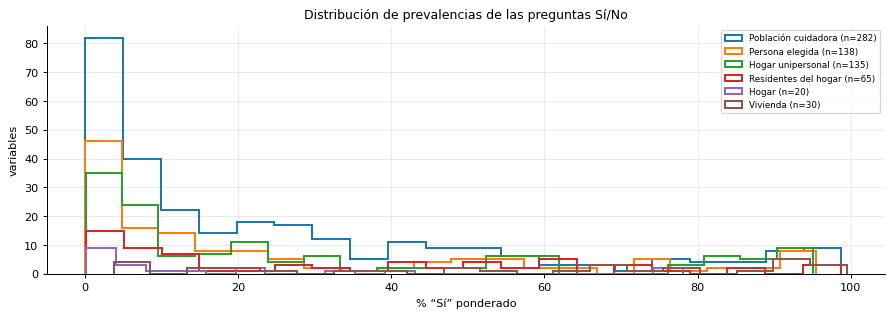

Preguntas Sí/No más frecuentes:


,tabla,var,etiqueta,pct_si,ic95_inf,ic95_sup,n
9,viv,P1_7,¿Hay luz eléctrica en esta vivienda?,99.456,99.212,99.699,6423
38,viv,P2_2,¿Todas las personas que viven en esta vivienda comparten un mismo gasto para comer?,99.065,98.760,99.370,6423
753,cui,P6_20_4,"La semana pasada, ¿usted le(s) hizo compañía o estuvo al pendiente (en la misma vivien...",98.780,97.995,99.566,432
194,res,PN_C0617,Niños - adolecentes de 06-17 años que necesitan cuidados,98.675,98.299,99.050,4413
724,cui,P6_14_08,"La semana pasada, ¿usted le hizo compañía o estuvo al pendiente (en la misma vivienda)?",97.585,96.673,98.498,2076
175,res,PN_C0005,Niños(as) de 00-05 años que necesitan cuidados,97.528,96.476,98.580,1851
176,res,P4_16,Ahora le preguntaré por las niñas y niños de hasta 5 años. La semana pasada a (NOMBRE)...,97.456,96.425,98.488,1810
736,cui,P6_16_7,"Ahora le preguntaré por el cuidado que le(s) dio. La semana pasada, ¿usted le hizo com...",97.199,96.203,98.195,2130
770,cui,P6_22_14,¿Usted le hizo compañía o estuvo al pendiente (en la misma vivienda)?,96.974,94.081,99.867,125
917,cui,P6_48,¿Usted estaría dispuesta(o) a capacitarse para ser cuidador(a) de personas?,96.316,95.547,97.084,2572


Preguntas Sí/No con IC amplio (>±10 pp) — estimaciones frágiles:
24 de 670


In [19]:
def prev_si(k, var):
    cat = cat_de(k, var) or {}; sic = [kk for kk, vv in cat.items() if re.match(r's[ií]', vv, re.I)]
    if not sic: return None
    d = E[k]; ok = d[var].notna() & d[var].map(_k).isin([kk for kk, vv in cat.items() if re.match(r's[ií]|no$', vv, re.I)])
    t = d.assign(_y=((d[var].map(_k) == sic[0]) & ok).astype(float), _x=ok.astype(float))
    R, se = razon(t, '_y', '_x', w=PESO[k]); return 100 * R, 100 * se, int(ok.sum())

bin_vars = CAT[(CAT.tipo == 'binaria Sí/No') & (CAT.n_valido >= 100) & (CAT.n_unicos >= 2) & ~CAT['var'].str.startswith('FILTRO')][['tabla', 'var', 'modulo', 'etiqueta']].copy()
out = [prev_si(r.tabla, r['var']) for _, r in bin_vars.iterrows()]
bin_vars[['pct_si', 'se', 'n']] = pd.DataFrame([o if o else (np.nan, np.nan, 0) for o in out], index=bin_vars.index)
bin_vars['ic95_inf'] = bin_vars.pct_si - 1.96 * bin_vars.se; bin_vars['ic95_sup'] = bin_vars.pct_si + 1.96 * bin_vars.se
bin_vars = bin_vars.dropna(subset=['pct_si'])
bin_vars.to_csv(SALIDA / 'prevalencias_si_no_enasic.csv', index=False, encoding='utf-8')
print(len(bin_vars), 'variables Sí/No estimadas; guardado en eda_general/prevalencias_si_no_enasic.csv')
fig, ax = plt.subplots(figsize=(10, 3.6))
for k in ['cui', 'ele', 'uni', 'res', 'hog', 'viv']:
    s = bin_vars[bin_vars.tabla == k].pct_si
    if len(s): ax.hist(s, bins=20, histtype='step', lw=1.6, label=f'{ENA_DESC[k]} (n={len(s)})')
ax.set_xlabel('% “Sí” ponderado'); ax.set_ylabel('variables'); ax.legend(fontsize=7); ax.set_title('Distribución de prevalencias de las preguntas Sí/No'); plt.tight_layout(); plt.show()
cols = ['tabla', 'var', 'etiqueta', 'pct_si', 'ic95_inf', 'ic95_sup', 'n']
print('Preguntas Sí/No más frecuentes:'); display(bin_vars.sort_values('pct_si', ascending=False).head(15)[cols])
print('Preguntas Sí/No con IC amplio (>±10 pp) — estimaciones frágiles:'); print((bin_vars.se * 1.96 > 10).sum(), 'de', len(bin_vars))

### 2.13 Brechas por sexo en la población cuidadora (exploración con control de comparaciones múltiples)

Con ~300 comparaciones, algunas saldrán “significativas” por azar. Se reporta la brecha de cada pregunta Sí/No entre mujeres y hombres cuidadores y se marca solo lo que supera un umbral de Bonferroni (z > 3.9 ≈ α = 0.05 / 300).

In [20]:
cu = E['cui']; muj = (cu.SEXO.map(_k) == '2').to_numpy(); hom = (cu.SEXO.map(_k) == '1').to_numpy()
def prev_dom(k, var, dom):
    cat = cat_de(k, var) or {}; sic = [kk for kk, vv in cat.items() if re.match(r's[ií]', vv, re.I)][0]; validos = [kk for kk, vv in cat.items() if re.match(r's[ií]|no$', vv, re.I)]
    d = E[k]; ok = (d[var].notna() & d[var].map(_k).isin(validos)).to_numpy() & dom
    t = d.assign(_y=((d[var].map(_k) == sic).to_numpy() & ok).astype(float), _x=ok.astype(float))
    if ok.sum() < 50: return np.nan, np.nan, int(ok.sum())
    R, se = razon(t, '_y', '_x', w=PESO[k]); return 100 * R, 100 * se, int(ok.sum())
filas = []
for _, r in bin_vars[(bin_vars.tabla == 'cui')].iterrows():
    pm, sm, nm = prev_dom('cui', r['var'], muj); ph, sh_, nh = prev_dom('cui', r['var'], hom)
    if np.isnan(pm) or np.isnan(ph): continue
    z = (pm - ph) / np.sqrt(sm ** 2 + sh_ ** 2 + 1e-12)
    filas.append({'var': r['var'], 'etiqueta': r.etiqueta[:90], 'mujeres_%': pm, 'hombres_%': ph, 'brecha_pp': pm - ph, 'z_aprox': z, 'n_muj': nm, 'n_hom': nh})
br = pd.DataFrame(filas); br['supera_Bonferroni'] = br.z_aprox.abs() > 3.9
print(f'{len(br)} comparaciones; {br.supera_Bonferroni.sum()} superan Bonferroni (z aprox. sin covarianza entre dominios → ligeramente conservador).')
display(br[br.supera_Bonferroni].sort_values('brecha_pp', key=abs, ascending=False).head(20))

255 comparaciones; 30 superan Bonferroni (z aprox. sin covarianza entre dominios → ligeramente conservador).


,var,etiqueta,mujeres_%,hombres_%,brecha_pp,z_aprox,n_muj,n_hom,supera_Bonferroni
86,P6_11_3,¿Por el cuidado que usted otorga se siente cansada(o)?,54.751,26.662,28.089,4.809,452,184,True
136,P6_30_3,¿Por el cuidado que usted les otorga se siente cansada(o)?,36.704,13.162,23.541,11.340,3476,1123,True
141,P6_31_1,"Por el cuidado que da a esta(s) persona(s), ¿usted está imposibilitada(o) para trabaja...",27.595,4.920,22.675,18.638,3476,1123,True
97,P6_14_02,"La semana pasada, ¿usted la(o) bañó, aseó, vistió o arregló?",95.128,72.919,22.209,7.628,1670,406,True
87,P6_11_4,¿Por el cuidado que usted otorga se siente deprimida(o)?,37.754,17.033,20.720,4.317,452,184,True
106,P6_16_2,"Ahora le preguntaré por el cuidado que le(s) dio. La semana pasada, ¿usted la(o) ayudó...",58.337,38.132,20.205,5.303,1680,450,True
113,P6_18_1,"Ahora me referiré al cuidado que le(s) dio. La semana pasada, ¿usted la(o) llevó o re...",61.779,79.431,-17.652,-5.138,1098,363,True
125,P6_25_1,"¿Qué medios de transporte utiliza para llevar o recoger a (NOMBRE(S)) de algún lugar, ...",29.298,46.930,-17.631,-7.786,3476,1123,True
130,P6_25_6,"¿Qué medios de transporte utiliza para llevar o recoger a (NOMBRE(S)) de algún lugar, ...",31.589,16.029,15.560,7.823,3476,1123,True
138,P6_30_5,¿Por el cuidado que usted les otorga se siente irritada(o)?,20.639,5.541,15.098,11.857,3476,1123,True


### 2.14 ¿Cuánto de ENASIC ya toca el repo?

Búsqueda textual de cada nombre de variable ENASIC en los scripts `.py` y cuadernos `.ipynb` del primer nivel de `Analysis/` (solo celdas de código; no se revisan subcarpetas como `etoe/` ni `DW/etl/`; los nombres armados con f-strings no se detectan). **Una mención no es un uso analítico**, y un nombre como `P6_7` existe en varias tablas, así que esto es una cota superior; sirve para ubicar módulos que casi nadie ha tocado.

In [21]:
import json
texto = []
for f in list((RAIZ / 'Analysis').glob('*.py')) + list((RAIZ / 'Analysis').glob('*.ipynb')):
    if f.name.startswith('EDA_general'): continue
    try:
        if f.suffix == '.py': texto.append(f.read_text(encoding='utf-8', errors='ignore'))
        else: texto.append('\n'.join(''.join(c['source']) for c in json.loads(f.read_text(encoding='utf-8'))['cells'] if c['cell_type'] == 'code'))
    except Exception as ex:
        print('no se pudo leer', f.name, ex)
corpus = '\n'.join(texto).upper()
toks = set(re.findall(r'[A-Z][A-Z0-9_]{1,}', corpus))
CAT['mencionada_en_repo'] = CAT['var'].str.upper().isin(toks)
u = CAT.groupby(['tabla', 'modulo']).agg(vars=('var', 'size'), mencionadas=('mencionada_en_repo', 'sum')).assign(pct=lambda d: (100 * d.mencionadas / d.vars).round(0))
print('Archivos de código revisados:', len(texto), '| variables ENASIC mencionadas al menos una vez:', int(CAT.mencionada_en_repo.sum()), 'de', len(CAT), f'({100*CAT.mencionada_en_repo.mean():.0f}%)')
display(u.sort_values('pct').head(18))
sin = CAT[(~CAT.mencionada_en_repo) & (CAT.tipo != 'vacía') & CAT.modulo.str.startswith('P') & (CAT.n_valido >= 200)]
print('Variables con ≥200 respuestas válidas que el repo no nombra, por módulo/tabla:'); display(sin.groupby(['tabla', 'modulo']).size().unstack(fill_value=0))
CAT.to_csv(SALIDA / 'catalogo_variables_enasic.csv', index=False, encoding='utf-8')

Archivos de código revisados: 20 | variables ENASIC mencionadas al menos una vez: 133 de 1286 (10%)


vars  mencionadas    pct
tabla modulo                                 
cui   P5              100            0  0.000
ele   P5              100            0  0.000
      P9               71            0  0.000
res   P4              127            0  0.000
uni   P5              100            0  0.000
res   P3               37            0  0.000
viv   P1               37            0  0.000
uni   P8               41            0  0.000
viv   P2                3            0  0.000
hog   P3A              26            2  8.000
ele   P7               48            4  8.000
cui   P7               48            4  8.000
uni   P7               48            4  8.000
      P6              104           15 14.000
hog   P2               30            5 17.000
      derivada/otra    11            2 18.000
cui   P6              251           58 23.000
uni   derivada/otra    16            4 25.000

Variables con ≥200 respuestas válidas que el repo no nombra, por módulo/tabla:


modulo,P1,P2,P3,P3A,P4,P5,P6,P7,P8,P9
tabla,,,,,,,,,,
cui,0,0,0,0,0,95,155,44,0,0
ele,0,0,0,0,0,99,4,44,0,71
hog,0,7,0,24,0,0,0,0,0,0
res,0,0,32,0,70,0,0,0,0,0
uni,0,0,0,0,0,58,1,44,41,0
viv,37,2,0,0,0,0,0,0,0,0


## 3. Fuentes agregadas de CDMX (`Data/investigacion/` y `Analysis/datos/*.csv`)

Tablas pequeñas, ya agregadas, sin factor de expansión ni errores. El riesgo aquí no es el muestreo sino la **procedencia, la unidad y la comparabilidad entre archivos**.

### 3.1 Perfil de cada archivo

In [22]:
INV = RAIZ / 'Data' / 'investigacion'
archivos = sorted(INV.glob('*.csv')) + [f for f in sorted(DATOS.glob('*.csv')) if 'enasic' not in f.name.lower()] + sorted((DATOS / 'contexto_nacional').glob('*.csv'))
AG = {}
for f in archivos:
    AG[f.stem] = limpiar_cols(leer_csv(f))
filas = []
for n, d in AG.items():
    num = d.select_dtypes('number').columns.tolist(); txt = [c for c in d.columns if c not in num]
    filas.append({'archivo': n[:70], 'filas': len(d), 'cols': d.shape[1], 'dup_filas': int(d.duplicated().sum()), 'nulos': int(d.isna().sum().sum()), 'cols_texto': ', '.join(txt)[:60], 'cols_num': ', '.join(num)[:60]})
display(pd.DataFrame(filas))

,archivo,filas,cols,dup_filas,nulos,cols_texto,cols_num
0,Capacidad disponible en residencias permanentes de sector privado para,12,3,0,0,"Alcaldia, Nomenclartura alcaldia",Capacidad_total
1,Centros de día para adultos y adultas mayores del sector público,33,3,0,0,"Tipo, Municipio",Numero_instituciones
2,Horas laborales y de cuidado.,33,4,0,0,"Edad, Sexo, Tipo de trabajo",Horas
3,Personas con Seguridad Social,112,4,0,0,"Edad, sexo, tipo de seguro",valor
4,Población con discapacidad que necesita ayuda para las actividades de,204,4,0,0,"tipo, alcaldia, poblacion",total
5,Población de adultos y adultas mayores por tipo de discapacidad,56,4,0,0,"edad, sexo, tipo_discapacidad",total
6,Población de más de 60 años,102,3,0,0,"NOM_MUN, GRUPO_EDAD",PORCENTAJE
7,Promedio del gasto en cuidados privados,6,4,0,0,"frecuencia, tipo_gasto","total, gasto_promedio"
8,Razón por la que no se usan las guarderías,34,4,0,0,"sexo, institucion, por_que_no_usa_servicios",porcentaje
9,Tiempo promedio en ayudas no pagadas a otros hogares,35,3,0,0,"sexo, grupo_edad",total_horas


### 3.2 Reconciliación de nombres de alcaldía y cobertura territorial

Se toma como catálogo de referencia el Marco Geoestadístico 2025 (INEGI) y se normalizan nombres (sin acentos, abreviaturas, variantes). Después, qué alcaldías aparecen en cada fuente y cuáles faltan.

In [23]:
import shapefile
r_mun = shapefile.Reader(str(DATOS / 'marco_geo_2025' / '09mun'), encoding='latin-1')   # el .cpg declara UTF-8 pero los bytes son latin-1
MUN = pd.DataFrame([dict(zip([f[0] for f in r_mun.fields[1:]], rec)) for rec in r_mun.records()])
ALC = [sin_acentos(x) for x in MUN.NOMGEO]
ABREV = {'AO': 'ALVARO OBREGON', 'AZC': 'AZCAPOTZALCO', 'BJ': 'BENITO JUAREZ', 'COY': 'COYOACAN', 'CUAJ': 'CUAJIMALPA DE MORELOS', 'CUAU': 'CUAUHTEMOC',
         'GAM': 'GUSTAVO A MADERO', 'IZTAC': 'IZTACALCO', 'IZTAP': 'IZTAPALAPA', 'MC': 'LA MAGDALENA CONTRERAS', 'MA': 'MILPA ALTA', 'MH': 'MIGUEL HIDALGO',
         'TLAH': 'TLAHUAC', 'TLAL': 'TLALPAN', 'VC': 'VENUSTIANO CARRANZA', 'XOCH': 'XOCHIMILCO', 'CUAJIMALPA': 'CUAJIMALPA DE MORELOS', 'MAGDALENA CONTRERAS': 'LA MAGDALENA CONTRERAS'}
def alc_norm(x):
    s = sin_acentos(x); return ABREV.get(s, s)
print('Alcaldías en el Marco Geoestadístico 2025:', len(MUN), '| CVE_MUN:', MUN.CVE_MUN.tolist())

COLALC = {'Capacidad disponible en residencias permanentes de sector privado para adultos y adultas mayores': 'Alcaldia',
          'Centros de día para adultos y adultas mayores del sector público': 'Municipio',
          'Población con discapacidad que necesita ayuda para las actividades de la vida diaria': 'alcaldia',
          'Población de más de 60 años': 'NOM_MUN',
          'Proyección de la población por grupos de edad y alcaldía en porcentaje': 'MUN'}
cob = {}
for n, c in COLALC.items():
    s = AG[n][c].map(alc_norm); cob[n[:55]] = {a: (s == a).sum() for a in ALC}
cob = pd.DataFrame(cob).T; cob.columns = [a.title() for a in cob.columns]
display((cob > 0).astype(int).assign(alcaldias_cubiertas=lambda d: d.sum(axis=1)).T)
extra = {n[:55]: sorted(set(AG[n][c].map(alc_norm)) - set(ALC)) for n, c in COLALC.items()}
print('Valores que no son alcaldía (agregados u otros):', extra)
cd_ = AG['Centros de día para adultos y adultas mayores del sector público'].copy(); cd_['alc'] = cd_.Municipio.map(alc_norm)
dup = cd_.groupby(['alc', 'Tipo']).filter(lambda g: len(g) > 1)
print('\nCentros de día: filas que colapsan al normalizar el nombre (misma alcaldía+tipo en 2 grafías):'); display(dup)
print('Total de instituciones si se SUMAN las grafías:', int(cd_.Numero_instituciones.sum()), '| si se toma el MÁXIMO por alcaldía+tipo:', int(cd_.groupby(['alc', 'Tipo']).Numero_instituciones.max().sum()), '→ ¿duplicado o dos registros distintos? [desconocida]; difiere en', int(cd_.Numero_instituciones.sum() - cd_.groupby(['alc', 'Tipo']).Numero_instituciones.max().sum()), 'instituciones')
cap = AG['Capacidad disponible en residencias permanentes de sector privado para adultos y adultas mayores']
print('\nAlcaldías ausentes en capacidad residencial privada:', sorted(set(ALC) - set(cap.Alcaldia.map(alc_norm))), '→ ausencia ≠ cero: no se puede distinguir “no hay residencias” de “no hay dato” [desconocida]')

Alcaldías en el Marco Geoestadístico 2025: 16 | CVE_MUN: ['005', '007', '015', '017', '013', '003', '008', '009', '010', '014', '011', '006', '002', '012', '004', '016']


,Capacidad disponible en residencias permanentes de sect,Centros de día para adultos y adultas mayores del secto,Población con discapacidad que necesita ayuda para las,Población de más de 60 años,Proyección de la población por grupos de edad y alcaldí
Gustavo A Madero,1,1,1,1,1
Iztapalapa,1,1,1,1,1
Cuauhtemoc,1,1,1,1,1
Venustiano Carranza,0,1,1,1,1
Xochimilco,1,1,1,1,1
Coyoacan,1,1,1,1,1
La Magdalena Contreras,1,1,1,1,1
Milpa Alta,0,0,1,1,1
Alvaro Obregon,1,1,1,1,1
Benito Juarez,1,1,1,1,1


Valores que no son alcaldía (agregados u otros): {'Capacidad disponible en residencias permanentes de sect': [], 'Centros de día para adultos y adultas mayores del secto': [], 'Población con discapacidad que necesita ayuda para las ': ['CDMX'], 'Población de más de 60 años': ['CIUDAD DE MEXICO'], 'Proyección de la población por grupos de edad y alcaldí': ['CDMX']}

Centros de día: filas que colapsan al normalizar el nombre (misma alcaldía+tipo en 2 grafías):


,Tipo,Municipio,Numero_instituciones,alc
0,RESIDENCIA DE DIA,ALVARO OBREGON,1,ALVARO OBREGON
3,RESIDENCIA DE DIA,ÁLVARO OBREGÓN,1,ALVARO OBREGON


Total de instituciones si se SUMAN las grafías: 157 | si se toma el MÁXIMO por alcaldía+tipo: 156 → ¿duplicado o dos registros distintos? [desconocida]; difiere en 1 instituciones

Alcaldías ausentes en capacidad residencial privada: ['CUAJIMALPA DE MORELOS', 'MILPA ALTA', 'TLAHUAC', 'VENUSTIANO CARRANZA'] → ausencia ≠ cero: no se puede distinguir “no hay residencias” de “no hay dato” [desconocida]


### 3.3 Población: proyección CONAPO por alcaldía y “población de más de 60 años”

¿Qué es exactamente `PORCENTAJE`? Los README del repo dicen “% de la población total de la CDMX”, con origen y año sin documentar para el archivo de 60+. Se prueba aritméticamente.

Años: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026, 2027, 2028, 2029, 2030] | sexos: ['Hombres', 'Mujeres'] | grupos de edad: 14 | filas por año: [476]


,suma_16_alcaldias_todas_edades_y_sexos,suma_fila_CDMX
AÑO,,
2015,100.000,100.000
2016,100.000,100.000
2017,100.000,100.000
2018,100.000,100.000


¿La fila CDMX = suma de alcaldías (2020, por grupo)? diferencia máxima abs: 7.105427357601002e-15


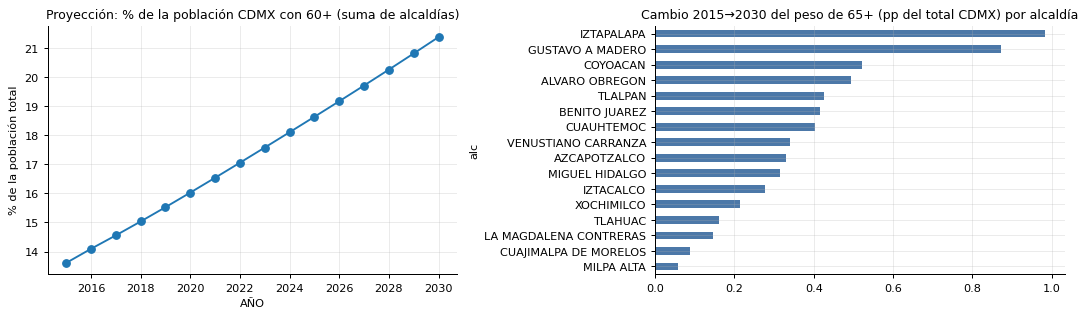

Cambio 2015→2030 de 60+ (pp del total CDMX): 7.76

% de la población de cada alcaldía con 60+ (proyección 2020; normalizado por el peso de la alcaldía):
{'MILPA ALTA': 10.3, 'CUAJIMALPA DE MORELOS': 10.7, 'TLAHUAC': 10.9, 'XOCHIMILCO': 12.8, 'IZTAPALAPA': 13.3, 'LA MAGDALENA CONTRERAS': 14.3, 'TLALPAN': 14.7, 'ALVARO OBREGON': 15.3, 'IZTACALCO': 17.5, 'GUSTAVO A MADERO': 17.6, 'CUAUHTEMOC': 17.8, 'VENUSTIANO CARRANZA': 18.6, 'MIGUEL HIDALGO': 19.1, 'AZCAPOTZALCO': 19.1, 'COYOACAN': 19.9, 'BENITO JUAREZ': 21.7}
Sin normalizar (PORCENTAJE directo) el orden refleja tamaño poblacional, no envejecimiento: correlación de rangos entre 60+/total CDMX y 60+/alcaldía = 0.51


,suma_16_alcaldias,fila_CDMX,dif
GRUPO_EDAD,,,
60 a 64 años,5.098,5.098,-0.000
65 a 69 años,3.867,3.867,-0.000
70 a 74 años,2.907,2.907,0.000
75 a 79 años,1.902,1.902,0.000
80 a 84 años,1.276,1.276,0.000
85 y más,1.145,1.145,0.000


Suma de las 16 alcaldías × 6 grupos de edad (≥60): 16.195 % del total CDMX
Año de la proyección cuyo 60+ se parece más al archivo: 2020 (60+ proyección 16.026 vs archivo 16.195; dif. 0.169 pp) → el año del archivo sigue siendo [desconocida] sin documentación; esto solo lo acota
Si los 60+ por alcaldía del archivo coinciden con el patrón de la proyección de ese año: 1.0 (correlación de rangos)


In [24]:
pr = AG['Proyección de la población por grupos de edad y alcaldía en porcentaje'].copy()
pr['alc'] = pr.MUN.map(alc_norm)
print('Años:', sorted(int(x) for x in pr.AÑO.unique()), '| sexos:', pr.SEXO.unique().tolist(), '| grupos de edad:', pr.EDAD_QUIN.nunique(), '| filas por año:', pr.groupby('AÑO').size().unique())
chk = pr[pr.alc != 'CDMX'].groupby(['AÑO']).PORCENTAJE.sum().rename('suma_16_alcaldias_todas_edades_y_sexos')
chk2 = pr[pr.alc == 'CDMX'].groupby(['AÑO']).PORCENTAJE.sum().rename('suma_fila_CDMX')
display(pd.concat([chk, chk2], axis=1).head(4))
a = pr[(pr.alc != 'CDMX')]
u = a[a.AÑO == 2020].groupby('EDAD_QUIN').PORCENTAJE.sum(); c20 = pr[(pr.alc == 'CDMX') & (pr.AÑO == 2020)].groupby('EDAD_QUIN').PORCENTAJE.sum()
print('¿La fila CDMX = suma de alcaldías (2020, por grupo)? diferencia máxima abs:', float((u - c20).abs().max()))

sx = a.pivot_table(index=['AÑO'], columns='EDAD_QUIN', values='PORCENTAJE', aggfunc='sum')
orden = ['Hasta 4 años', '5 a 9 años', '10 a 14 años', '15 a 19 años', '20 a 24 años', '25 a 29 años', '30 a 34 años', '35 a 39 años', '40 a 44 años', '45 a 49 años', '50 a 54 años', '55 a 59 años', '60 a 64 años', '65 y más']
sx = sx[orden]; sx['60+'] = sx['60 a 64 años'] + sx['65 y más']
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sx[['60+']].plot(ax=ax[0], marker='o', legend=False); ax[0].set_title('Proyección: % de la población CDMX con 60+ (suma de alcaldías)'); ax[0].set_ylabel('% de la población total')
d65 = a[a.EDAD_QUIN == '65 y más'].groupby(['AÑO', 'alc']).PORCENTAJE.sum().unstack()
(d65.loc[2030] - d65.loc[2015]).sort_values().plot.barh(ax=ax[1], color='#4c78a8'); ax[1].set_title('Cambio 2015→2030 del peso de 65+ (pp del total CDMX) por alcaldía'); plt.tight_layout(); plt.show()
print('Cambio 2015→2030 de 60+ (pp del total CDMX):', round(float(sx.loc[2030, '60+'] - sx.loc[2015, '60+']), 2))

# PORCENTAJE es % del TOTAL de CDMX → para comparar alcaldías hay que dividir entre el peso total de cada alcaldía
tot_alc = a[a.AÑO == 2020].groupby('alc').PORCENTAJE.sum(); s60 = a[(a.AÑO == 2020) & a.EDAD_QUIN.isin(['60 a 64 años', '65 y más'])].groupby('alc').PORCENTAJE.sum()
prev60 = (100 * s60 / tot_alc).sort_values()
print('\n% de la población de cada alcaldía con 60+ (proyección 2020; normalizado por el peso de la alcaldía):'); print(prev60.round(1).to_dict())
print('Sin normalizar (PORCENTAJE directo) el orden refleja tamaño poblacional, no envejecimiento: correlación de rangos entre 60+/total CDMX y 60+/alcaldía =', round(float(s60.rank().corr(prev60.rank())), 2))
m60 = AG['Población de más de 60 años'].copy(); m60['alc'] = m60.NOM_MUN.map(alc_norm)
s16 = m60[m60.alc != 'CIUDAD DE MEXICO'].groupby('GRUPO_EDAD').PORCENTAJE.sum(); sc = m60[m60.alc == 'CIUDAD DE MEXICO'].set_index('GRUPO_EDAD').PORCENTAJE
display(pd.concat([s16.rename('suma_16_alcaldias'), sc.rename('fila_CDMX')], axis=1).assign(dif=lambda d: d.suma_16_alcaldias - d.fila_CDMX))
print('Suma de las 16 alcaldías × 6 grupos de edad (≥60):', round(float(m60[m60.alc != 'CIUDAD DE MEXICO'].PORCENTAJE.sum()), 3), '% del total CDMX')
tot60 = float(m60[m60.alc != 'CIUDAD DE MEXICO'].PORCENTAJE.sum()); anio_cercano = int((sx['60+'] - tot60).abs().idxmin())
print('Año de la proyección cuyo 60+ se parece más al archivo:', anio_cercano, f"(60+ proyección {sx.loc[anio_cercano, '60+']:.3f} vs archivo {tot60:.3f}; dif. {abs(sx.loc[anio_cercano, '60+'] - tot60):.3f} pp) → el año del archivo sigue siendo [desconocida] sin documentación; esto solo lo acota")
print('Si los 60+ por alcaldía del archivo coinciden con el patrón de la proyección de ese año:', round(float(m60[m60.alc != 'CIUDAD DE MEXICO'].groupby('alc').PORCENTAJE.sum().rank().corr(a[(a.AÑO == anio_cercano) & a.EDAD_QUIN.isin(['60 a 64 años', '65 y más'])].groupby('alc').PORCENTAJE.sum().rank())), 3), '(correlación de rangos)')

### 3.4 Discapacidad con necesidad de ayuda, por alcaldía y tipo

Antes de usarla: ¿suma de alcaldías = fila CDMX?, ¿“limitación” y “discapacidad” son categorías excluyentes?, ¿se pueden sumar los tipos de dificultad (una persona puede tener varias)?

In [25]:
dd = AG['Población con discapacidad que necesita ayuda para las actividades de la vida diaria'].copy()
dd['alc'] = dd.alcaldia.map(alc_norm)
print('Claves de alcaldía:', sorted(dd.alcaldia.unique()))
es_cdmx = dd.alcaldia.eq('CDMX')
s_alc = dd[~es_cdmx].groupby(['tipo', 'poblacion']).total.sum(); s_cdmx = dd[es_cdmx].set_index(['tipo', 'poblacion']).total
cmp_ = pd.concat([s_alc.rename('suma_alcaldias'), s_cdmx.rename('fila_CDMX')], axis=1); cmp_['dif'] = cmp_.suma_alcaldias - cmp_.fila_CDMX; cmp_['dif_%'] = 100 * cmp_.dif / cmp_.fila_CDMX
display(cmp_)
print('Alcaldías presentes por tipo×dificultad (esperado 16):', dd[~es_cdmx].groupby(['tipo', 'poblacion']).alc.nunique().value_counts().to_dict())
print('Suma de tipos de dificultad CDMX (con solapamiento, NO es población única):', int(s_cdmx.sum()))

Claves de alcaldía: ['AO', 'AZC', 'BJ', 'CDMX', 'COY', 'CUAJ', 'CUAU', 'GAM', 'IZTAC', 'IZTAP', 'MA', 'MC', 'MH', 'TLAH', 'TLAL', 'VC', 'XOCH']


suma_alcaldias  fila_CDMX  dif  dif_%
tipo         poblacion                                                            
Discapacidad para bañarse, vestirse o comer           83313      83313    0  0.000
             para caminar                            244392     244392    0  0.000
             para comunicarse                         59973      59973    0  0.000
             para oír                                114402     114402    0  0.000
             para recordar o concentrarse             85247      85247    0  0.000
             para ver                                210889     210889    0  0.000
Limitación   para bañarse, vestirse o comer           55715      55715    0  0.000
             para caminar                            370694     370694    0  0.000
             para comunicarse                         58894      58894    0  0.000
             para oír                                258883     258883    0  0.000
             para recordar o concentrarse            226944     226944    0  0.000
             para ver                                731480     731480    0  0.000

Alcaldías presentes por tipo×dificultad (esperado 16): {16: 12}
Suma de tipos de dificultad CDMX (con solapamiento, NO es población única): 2500826


### 3.5 Uso del tiempo, gasto y servicios (tablas nacionales/de muestra pequeña)

Tipo de trabajo Cuidado         Laboral        
Sexo            Hombres Mujeres Hombres Mujeres
Edad                                           
11-17             9.700  15.400  31.000  30.300
18-29            15.200  31.600  48.000  39.900
30-39            14.800  28.600  51.600  44.700
40-49            16.600  26.200  52.800  45.100
50-59            16.400  24.400  50.900  41.600
60-69            19.100  23.800  45.100  37.900
70-79            25.400  28.200  36.300  29.300
80-89            45.000  27.100  43.500  22.000
90-99               NaN  18.500     NaN     NaN

Combinaciones edad×sexo×tipo faltantes (cuadrícula completa = 8 edades+90-99 × 2 × 2): 3 celdas faltan → [('90-99', 'Hombres', 'Cuidado'), ('90-99', 'Hombres', 'Laboral'), ('90-99', 'Mujeres', 'Laboral')]


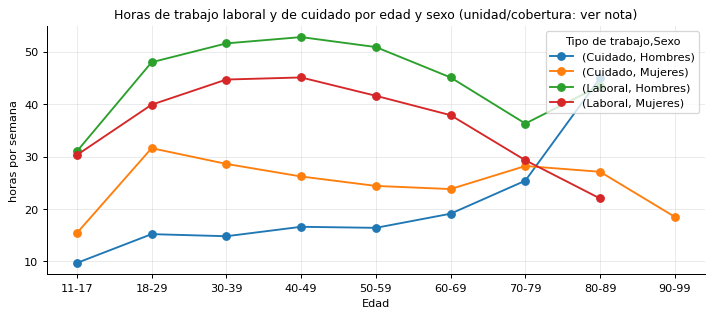

Nota [desconocida]: el archivo no documenta fuente, año ni cobertura geográfica (nacional vs CDMX); no se puede usar en cifras de alcaldía.


,total,frecuencia,tipo_gasto,gasto_promedio
0,3319,No aplica,Servicio doméstico,"1,908.837"
1,282,No aplica,Cuidado de niños,"1,722.961"
2,133,No aplica,Estancias infantiles,"1,355.910"
3,58,No aplica,Educación especial para discapacitados,"1,118.793"
4,1,Una vez al mes,Estancias infantiles,450.000
5,1,Cada Semana,Educación especial para discapacitados,40.000


n por tipo de gasto (columna total): {'Servicio doméstico': 3319, 'Cuidado de niños': 282, 'Estancias infantiles': 1, 'Educación especial para discapacitados': 1} → solo 1 observación en dos filas con frecuencia mensual/semanal: no usable como promedio [confirmada]

Seguridad social: sexo codificado como ['Mujeres', 'hombres'] (¿“hombres” en minúscula = error de captura?); valor rango 0.0 – 11.0512129380054
Combinaciones edad×sexo×seguro: {('IMSS', 'Mujeres'): 14, ('IMSS', 'hombres'): 14, ('ISSSTE', 'Mujeres'): 14, ('ISSSTE', 'hombres'): 14, ('Seguro Popular', 'Mujeres'): 14, ('Seguro Popular', 'hombres'): 14, ('Seguro Privado', 'Mujeres'): 14, ('Seguro Privado', 'hombres'): 14}

Guarderías: instituciones = ['IMSS', 'Seguro Popular', 'ISSSTE', 'IMSS_PEMEX/Defensa/Marina', 'PEMEX/Defensa/Marina', 'ISSSTE_Privado']
Instituciones compuestas (¿categorías mezcladas, doble conteo?): ['IMSS_PEMEX/Defensa/Marina', 'ISSSTE_Privado']
Suma de porcentajes por sexo×institución (¿100?):


institucion,IMSS,IMSS_PEMEX/Defensa/Marina,ISSSTE,ISSSTE_Privado,PEMEX/Defensa/Marina,Seguro Popular
sexo,,,,,,
Hombres,21.200,0.900,8.100,NaN,1.800,9.300
Mujeres,34.700,1.900,7.800,1.000,1.000,12.300


In [26]:
hl = AG['Horas laborales y de cuidado.']
pv = hl.pivot_table(index='Edad', columns=['Tipo de trabajo', 'Sexo'], values='Horas')
display(pv)
print('Combinaciones edad×sexo×tipo faltantes (cuadrícula completa = 8 edades+90-99 × 2 × 2):', 9 * 2 * 2 - len(hl), 'celdas faltan →', sorted(set((e, s, t) for e in hl.Edad.unique() for s in hl.Sexo.unique() for t in hl['Tipo de trabajo'].unique()) - set(zip(hl.Edad, hl.Sexo, hl['Tipo de trabajo']))))
ax = pv.plot(marker='o', figsize=(8, 3.6)); ax.set_ylabel('horas por semana'); ax.set_title('Horas de trabajo laboral y de cuidado por edad y sexo (unidad/cobertura: ver nota)'); plt.tight_layout(); plt.show()
print('Nota [desconocida]: el archivo no documenta fuente, año ni cobertura geográfica (nacional vs CDMX); no se puede usar en cifras de alcaldía.')

gp = AG['Promedio del gasto en cuidados privados']; display(gp)
print('n por tipo de gasto (columna total):', dict(zip(gp.tipo_gasto, gp.total)), '→ solo 1 observación en dos filas con frecuencia mensual/semanal: no usable como promedio [confirmada]')
sg = AG['Personas con Seguridad Social']; print('\nSeguridad social: sexo codificado como', sg.sexo.unique().tolist(), '(¿“hombres” en minúscula = error de captura?); valor rango', sg.valor.min(), '–', sg.valor.max())
print('Combinaciones edad×sexo×seguro:', sg.groupby(['tipo de seguro', 'sexo']).size().to_dict())
gu = AG['Razón por la que no se usan las guarderías']; print('\nGuarderías: instituciones =', gu.institucion.unique().tolist()); print('Instituciones compuestas (¿categorías mezcladas, doble conteo?):', [x for x in gu.institucion.unique() if '_' in x])
print('Suma de porcentajes por sexo×institución (¿100?):'); display(gu.groupby(['sexo', 'institucion']).porcentaje.sum().unstack().round(1))

### 3.6 Contexto nacional: trabajo no remunerado, PIB y presupuesto 2026

Consistencia interna: |horas_totales − (H+M)| máx = 1 | |población − (H+M)| máx = 0 | entidades: 32
Horas por persona recalculadas vs publicadas (diferencia máx. abs, con unidades por confirmar): 0.05


,entidad,hrs_promedio_hombres,hrs_promedio_mujeres,razon_muj_hom
6,Chiapas,10.300,36.300,3.524
31,Zacatecas,11.100,38.300,3.450
20,Puebla,9.000,30.700,3.411
29,Veracruz,10.700,34.700,3.243
24,Sinaloa,9.600,30.500,3.177
17,Nayarit,9.900,30.500,3.081


Rango de la razón mujeres/hombres por entidad: 2.01 – 3.52


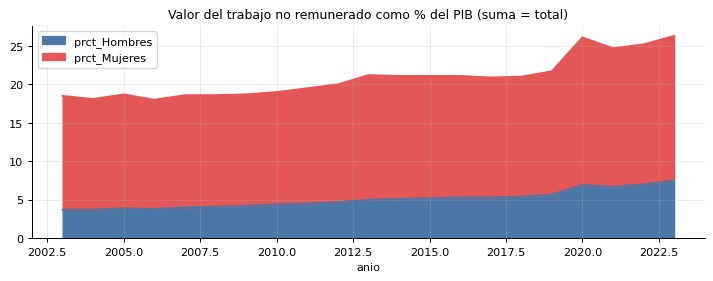

Serie 2003 – 2023 | faltan años: []

PEF 2026 Anexo 31: filas = 47 | instituciones = 26 | monto total (mil M$): 468.6


,institucion,programa_presupuestario,monto,pct,pct_acum
9,Educación,Beca Universal de Educación Básica Rita Cetina,"129,386,000,000.000",27.609,27.609
35,IMSS,Servicios de atención a la salud,"126,925,529,468.000",27.084,54.692
21,Bienestar,Pensión para el Bienestar de las Personas Adultas Mayores,"123,326,567,737.000",26.316,81.008
22,Bienestar,Pensión para el Bienestar de las Personas con Discapacidad Permanente,"28,961,441,920.000",6.180,87.188
34,IMSS,Servicios de guardería,"17,120,100,948.000",3.653,90.841
23,Bienestar,Pensión Mujeres Bienestar,"15,000,000,000.000",3.201,94.042


Top-5 programas concentran 90.8 % del monto → el total no mide “gasto en cuidados”: incluye programas cuya acción transversal es solo una parte de su presupuesto [probable; revisar el texto del anexo].


In [27]:
hn = AG['horas_trabajo_no_remunerado_2019'].copy()
hn['razon_muj_hom'] = hn.hrs_promedio_mujeres / hn.hrs_promedio_hombres
chk = (hn.horas_totales - (hn.horas_hombres + hn.horas_mujeres)).abs().max(); chk2 = (hn.poblacion_total - (hn.poblacion_hombres + hn.poblacion_mujeres)).abs().max()
print('Consistencia interna: |horas_totales − (H+M)| máx =', chk, '| |población − (H+M)| máx =', chk2, '| entidades:', hn.entidad.nunique())
rec = hn.horas_totales / hn.poblacion_total / 1 ; print('Horas por persona recalculadas vs publicadas (diferencia máx. abs, con unidades por confirmar):', round(float((rec - hn.hrs_promedio_total).abs().max()), 2))
display(hn.sort_values('razon_muj_hom', ascending=False)[['entidad', 'hrs_promedio_hombres', 'hrs_promedio_mujeres', 'razon_muj_hom']].head(6))
print('Rango de la razón mujeres/hombres por entidad:', round(hn.razon_muj_hom.min(), 2), '–', round(hn.razon_muj_hom.max(), 2))
tp = AG['trab_norem_pib']; ax = tp.set_index('anio')[['prct_Hombres', 'prct_Mujeres']].plot.area(figsize=(8, 3.2), color=['#4c78a8', '#e45756']); ax.set_title('Valor del trabajo no remunerado como % del PIB (suma = total)'); plt.tight_layout(); plt.show()
print('Serie', int(tp.anio.min()), '–', int(tp.anio.max()), '| faltan años:', sorted(set(range(int(tp.anio.min()), int(tp.anio.max()) + 1)) - set(tp.anio)))
pef = AG['pef2026_anexo31_programas_cuidados'].copy()
print('\nPEF 2026 Anexo 31: filas =', len(pef), '| instituciones =', pef.institucion.nunique(), '| monto total (mil M$):', round(pef.monto.sum() / 1e9, 1))
top = pef.sort_values('monto', ascending=False).assign(pct=lambda d: 100 * d.monto / d.monto.sum()); top['pct_acum'] = top.pct.cumsum()
display(top.head(6)[['institucion', 'programa_presupuestario', 'monto', 'pct', 'pct_acum']])
print('Top-5 programas concentran', round(top.pct.head(5).sum(), 1), '% del monto → el total no mide “gasto en cuidados”: incluye programas cuya acción transversal es solo una parte de su presupuesto [probable; revisar el texto del anexo].')

## 4. Pobreza, marginación y rezago: fuentes nacionales con desagregación municipal/AGEB

Estas fuentes cubren todo el país (o todo CDMX a nivel AGEB), a diferencia de ENASIC. La pregunta de EDA no es solo “qué dicen” sino **a qué nivel geográfico son confiables**.

### 4.1 CONAPO — Índice de marginación 2020 (municipal y estatal)

Municipios: 2469 | entidades: 32 | estatal: 32


columna,CVE_ENT,NOM_ENT,CVE_MUN,NOM_MUN,POB_TOT,ANALF,SBASC,OVSDE,OVSEE,OVSAE,OVPT,VHAC,PL.5000,PO2SM,IM_2020,GM_2020,IMN_2020
tipo,int64,object,int64,object,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,object,float64
pct_nulo,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
unicos,32,32,2469,2328,2402,2462,2466,2431,2435,2417,2458,2448,1186,2447,2469,5,2469
min,1.000,NaN,"1,001.000",NaN,81.000,0.353,5.535,0.000,0.000,0.000,0.000,3.950,0.000,28.453,21.407,NaN,0.335
max,32.000,NaN,"32,058.000",NaN,"1,922,523.000",53.071,88.328,64.450,53.065,81.788,68.150,69.564,100.000,100.000,62.397,NaN,0.977


Grado de marginación: {'Muy bajo': 655, 'Alto': 586, 'Bajo': 530, 'Medio': 494, 'Muy alto': 204}
Correlación de Spearman entre indicadores municipales (nacional):


,ANALF,SBASC,OVSDE,OVSEE,OVSAE,OVPT,VHAC,PL.5000,PO2SM,IM_2020
ANALF,1.000,0.820,0.520,0.600,0.460,0.700,0.680,0.500,0.730,-0.910
SBASC,0.820,1.000,0.370,0.480,0.290,0.600,0.500,0.580,0.720,-0.800
OVSDE,0.520,0.370,1.000,0.510,0.400,0.270,0.430,0.360,0.350,-0.580
OVSEE,0.600,0.480,0.510,1.000,0.540,0.600,0.510,0.420,0.480,-0.720
OVSAE,0.460,0.290,0.400,0.540,1.000,0.530,0.440,0.180,0.320,-0.570
OVPT,0.700,0.600,0.270,0.600,0.530,1.000,0.660,0.370,0.620,-0.780
VHAC,0.680,0.500,0.430,0.510,0.440,0.660,1.000,0.260,0.620,-0.750
PL.5000,0.500,0.580,0.360,0.420,0.180,0.370,0.260,1.000,0.560,-0.640
PO2SM,0.730,0.720,0.350,0.480,0.320,0.620,0.620,0.560,1.000,-0.800
IM_2020,-0.910,-0.800,-0.580,-0.720,-0.570,-0.780,-0.750,-0.640,-0.800,1.000


CDMX: 16 alcaldías | grados: {'Muy bajo': 16} | rango IM_2020: 57.281 – 62.397


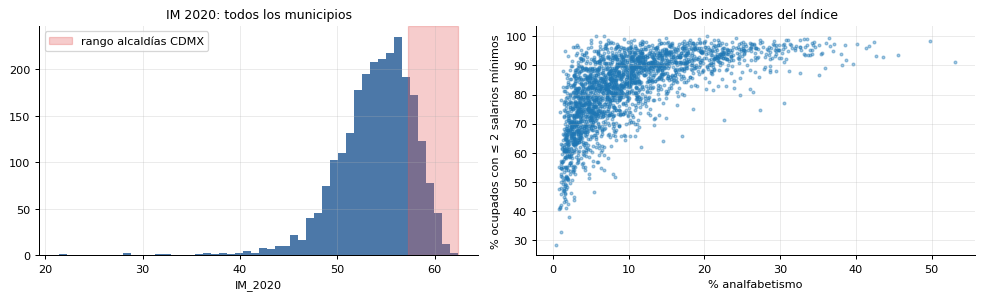

In [28]:
imm = limpiar_cols(leer_csv(DATOS / 'conapo_marginacion' / 'imm_2020.csv')); ime = limpiar_cols(leer_csv(DATOS / 'conapo_marginacion' / 'ime_2020.csv'))
print('Municipios:', len(imm), '| entidades:', imm.CVE_ENT.nunique(), '| estatal:', len(ime))
display(perfil_cols(imm).set_index('columna').T.loc[['tipo', 'pct_nulo', 'unicos', 'min', 'max']])
print('Grado de marginación:', imm.GM_2020.value_counts().to_dict())
ind = ['ANALF', 'SBASC', 'OVSDE', 'OVSEE', 'OVSAE', 'OVPT', 'VHAC', 'PL.5000', 'PO2SM', 'IM_2020']
print('Correlación de Spearman entre indicadores municipales (nacional):'); display(imm[ind].corr(method='spearman').round(2))
cdmx = imm[imm.CVE_ENT.astype(str).str.zfill(2) == '09']
print('CDMX:', len(cdmx), 'alcaldías | grados:', cdmx.GM_2020.value_counts().to_dict(), '| rango IM_2020:', round(cdmx.IM_2020.min(), 3), '–', round(cdmx.IM_2020.max(), 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(imm.IM_2020, bins=50, color='#4c78a8'); ax[0].axvspan(cdmx.IM_2020.min(), cdmx.IM_2020.max(), color='#e45756', alpha=.3, label='rango alcaldías CDMX'); ax[0].legend(); ax[0].set_title('IM 2020: todos los municipios'); ax[0].set_xlabel('IM_2020')
ax[1].scatter(imm.ANALF, imm.PO2SM, s=5, alpha=.4); ax[1].set_xlabel('% analfabetismo'); ax[1].set_ylabel('% ocupados con ≤ 2 salarios mínimos'); ax[1].set_title('Dos indicadores del índice'); plt.tight_layout(); plt.show()

### 4.2 CONEVAL — Índice de rezago social (entidad, localidad, AGEB)

In [29]:
irs_e = limpiar_cols(leer_csv(DATOS / 'coneval_irs' / 'irs_entidad_nacional_2020.csv'))
print('IRS entidad:', irs_e.shape); display(irs_e.head(3))
with zipfile.ZipFile(DATOS / 'coneval_irs' / 'IRS_localidad_2020.csv.zip') as z: irs_l = limpiar_cols(leer_csv(z.open(z.namelist()[0])))
with zipfile.ZipFile(DATOS / 'coneval_irs' / 'grs_ageb_2020.csv.zip') as z: grs = limpiar_cols(leer_csv(z.open(z.namelist()[0]), dtype={'folio_ageb': str, 'clave_ageb': str}))
print('IRS localidad:', irs_l.shape, '| localidades por entidad (top 5):', irs_l.entidad.value_counts().head(5).to_dict() if 'entidad' in irs_l else '')
print('GRS AGEB:', grs.shape, '| entidades:', grs.clave_entidad.nunique(), '| AGEB por entidad (CDMX=09):', int((grs.clave_entidad.astype(str).str.zfill(2) == '09').sum()))
print('Grado de rezago social AGEB (nacional):', grs.grs.value_counts(dropna=False).to_dict())
fn = [c for c in grs.columns if c.startswith('fn_')]
print(f'{len(fn)} columnas fn_* sin documentación en el repo (valores numéricos de otra escala que sus homólogas i_*; ej.:', {c: round(float(grs[c].dropna().iloc[0]), 3) for c in fn[3:6]}, ') → significado [desconocida]; no se usan aquí.')
print('% de AGEB con indicador nulo:'); display((grs[[c for c in grs.columns if c.startswith('i_')]].isna().mean() * 100).round(1).to_frame('pct_nulo').T)
gc = grs[grs.clave_entidad.astype(str).str.zfill(2) == '09']
print('CDMX AGEB:', len(gc), '| grados:', gc.grs.value_counts(dropna=False).to_dict(), '| población CDMX en AGEB:', int(gc.poblacion.sum()))

IRS entidad: (33, 18)


,clave_entidad,entidad_federativa,poblacion,i_analf,i_asistesc,i_edbasinc,i_sdsalud,i_ptierra,i_nosan,i_noagua,i_nodren,i_noelec,i_nolav,i_noref,irs,grs,lugar,entidad
0,0,Nacional,126014024,4.742,6.120,29.593,26.187,3.514,1.930,3.457,4.263,0.765,27.154,12.361,NaN,Sin dato,NaN,Nacional
1,1,Aguascalientes,1425607,2.109,5.012,23.479,18.384,0.751,0.623,0.554,0.616,0.313,13.031,5.394,-1.102,Muy bajo,29.000,Aguascalientes
2,2,Baja California,3769020,1.821,6.514,24.620,22.189,1.973,0.659,2.082,3.473,0.782,17.269,5.071,-0.642,Bajo,26.000,Baja California


IRS localidad: (108149, 20) | localidades por entidad (top 5): {'Veracruz': 12250, 'Chiapas': 11971, 'Oaxaca': 8404, 'Guanajuato': 6111, 'Jalisco': 6109}
GRS AGEB: (61430, 49) | entidades: 32 | AGEB por entidad (CDMX=09): 2410
Grado de rezago social AGEB (nacional): {'Medio': 21576, 'Bajo': 16874, 'Alto': 10264, 'Muy bajo': 8769, 'Muy alto': 3947}
20 columnas fn_* sin documentación en el repo (valores numéricos de otra escala que sus homólogas i_*; ej.: {'fn_i_analf': 0.823, 'fn_i_asistesc_6a14': 13.077, 'fn_i_asistesc_015a24': 85.799} ) → significado [desconocida]; no se usan aquí.
% de AGEB con indicador nulo:


,i_analf,i_asistesc_6a14,i_asistesc_015a24,i_edbasinc,i_sdsalud,i_hacinamiento,i_noagua,i_nosan,i_nodren,i_noelec,i_ptierra,i_nolav,i_noref,i_notelefono_fijo,i_nocelular,i_nocomputadora,i_nointernet
pct_nulo,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


CDMX AGEB: 2410 | grados: {'Bajo': 1234, 'Muy bajo': 948, 'Medio': 200, 'Alto': 22, 'Muy alto': 6} | población CDMX en AGEB: 9130248


### 4.3 CONEVAL — Pobreza municipal 2010/2015/2020 por grupo poblacional (9 hojas)

La hoja trae, por municipio, cada indicador con su **marca de precisión estadística** (✔ precisa · ⚠ aceptable · ❌ sin precisión) en una columna contigua al valor. Se reestructura a formato largo para medir *qué fracción de las estimaciones es utilizable*, por grupo e indicador.

In [30]:
XLSX = DATOS / 'CONEVAL_pobreza_grupos_poblacionales_municipal_2010_2015_2020.xlsx'
def leer_hoja_coneval(hoja):
    raw = pd.read_excel(XLSX, sheet_name=hoja, header=None)
    h1 = raw.iloc[6].ffill().astype(str); h2 = raw.iloc[7].astype(str)   # encabezados en las filas 7 y 8 de la hoja
    cols = [f'{a}|{b}' for a, b in zip(h1, h2)]
    df = raw.iloc[8:].copy(); df.columns = cols
    cm = [c for c in cols if c.startswith('Clave municipio')][0]; nm = [c for c in cols if c.startswith('Municipio')][0]; ne = [c for c in cols if c.startswith('Entidad')][0]
    df = df[df[cm].astype(str).str.fullmatch(r'\d{5}')]
    filas = []
    for c in cols:
        ind, sub = c.split('|')
        if sub.startswith('Porcentaje'):
            anio = int(sub[-4:]); cp = f'{ind}|Precisión estadística {anio}'
            if cp in df.columns:
                v = pd.to_numeric(df[c], errors='coerce')
                filas.append(pd.DataFrame({'grupo': hoja, 'cve_mun': df[cm].astype(str), 'municipio': df[nm], 'entidad': df[ne], 'indicador': ind, 'anio': anio, 'valor': v.values, 'precision': df[cp].astype(str).values}))
    return pd.concat(filas)

hojas = pd.ExcelFile(XLSX).sheet_names
CON = pd.concat([leer_hoja_coneval(h) for h in hojas], ignore_index=True)
CON['indicador'] = CON.indicador.str.strip()   # un encabezado trae espacio inicial
CON['precision'] = CON.precision.replace({'✔': 'precisa', '⚠': 'aceptable', '❌': 'sin precisión'})
print('Registros (grupo × municipio × indicador × año):', len(CON), '| municipios:', CON.cve_mun.nunique(), '| indicadores:', CON.indicador.nunique())
print('Indicadores:', CON.indicador.unique().tolist())
print('Valores no numéricos (“-” = no estimable) → % de registros sin valor:', round(100 * CON.valor.isna().mean(), 1))
tab = CON[CON.anio == 2020].pivot_table(index='grupo', columns='precision', values='valor', aggfunc='size', fill_value=0)
tab = (100 * tab.div(tab.sum(axis=1), axis=0)).round(1); tab['n_registros'] = CON[CON.anio == 2020].groupby('grupo').size()
print('\nPrecisión de las estimaciones municipales 2020, por grupo poblacional (% de registros):'); display(tab)
cd2 = CON[(CON.anio == 2020) & (CON.cve_mun.str.startswith('09'))]
print('Solo CDMX (16 alcaldías), 2020 — % precisa/aceptable/sin precisión por grupo:'); display((100 * cd2.pivot_table(index='grupo', columns='precision', values='valor', aggfunc='size', fill_value=0).pipe(lambda d: d.div(d.sum(axis=1), axis=0))).round(1))

Registros (grupo × municipio × indicador × año): 513216 | municipios: 2469 | indicadores: 8
Indicadores: ['Población en situación de pobreza', 'Población con ingreso inferior a la línea de pobreza por ingresos', 'Población con carencia por rezago educativo', 'Población con carencia por acceso a los servicios de salud', 'Población con carencia por acceso a la seguridad social', 'Población con carencia por calidad y espacios de la vivienda', 'Población con carencia por acceso a los servicios básicos en la vivienda', 'Población con carencia por acceso a la alimentación']
Valores no numéricos (“-” = no estimable) → % de registros sin valor: 11.6

Precisión de las estimaciones municipales 2020, por grupo poblacional (% de registros):


precision,aceptable,n.d.,precisa,sin precisión,n_registros
grupo,,,,,
adultmay,26.600,0.400,56.600,16.500,19752
adultos,15.400,0.100,78.400,6.000,19752
hombres,13.800,0.100,80.800,5.300,19752
jovenes,19.900,0.200,70.600,9.300,19752
mujeres,14.400,0.200,79.600,5.800,19752
nna,16.500,0.200,75.700,7.600,19752
pobindigena,15.200,8.400,48.600,27.800,19640
rural,21.000,0.800,64.700,13.500,19568
urbano,13.100,0.700,80.000,6.200,13352


Solo CDMX (16 alcaldías), 2020 — % precisa/aceptable/sin precisión por grupo:


precision,aceptable,n.d.,precisa,sin precisión
grupo,,,,
adultmay,14.800,0.000,68.000,17.200
adultos,10.200,0.000,77.300,12.500
hombres,8.600,0.000,79.700,11.700
jovenes,10.200,0.000,76.600,13.300
mujeres,7.000,0.000,81.200,11.700
nna,10.900,0.000,77.300,11.700
pobindigena,18.000,3.900,56.200,21.900
rural,19.600,0.000,62.500,17.900
urbano,7.000,0.000,82.000,10.900


In [31]:
pob = CON[(CON.indicador == 'Población en situación de pobreza') & (CON.anio == 2020)]
sel = pob[pob.cve_mun.str.startswith('09')].pivot_table(index='municipio', columns='grupo', values='valor').round(1)
print('Pobreza 2020 (% de la población del grupo) por alcaldía y grupo — CDMX:'); display(sel[[c for c in ['adultmay', 'mujeres', 'hombres', 'nna', 'jovenes', 'adultos'] if c in sel.columns]])
q = CON[(CON.indicador.str.contains('seguridad social')) & (CON.anio == 2020) & (CON.grupo == 'adultmay')]
print('Carencia por seguridad social en 65+ (2020): mediana nacional', round(q.valor.median(), 1), '| mediana CDMX', round(q[q.cve_mun.str.startswith('09')].valor.median(), 1))
print('Municipios con ≥1 indicador “sin precisión” en 65+ (nacional, 2020):', round(100 * (CON[(CON.grupo == 'adultmay') & (CON.anio == 2020)].assign(sp=lambda d: d.precision == 'sin precisión').groupby('cve_mun').sp.any().mean()), 1), '%')

Pobreza 2020 (% de la población del grupo) por alcaldía y grupo — CDMX:


grupo,adultmay,mujeres,hombres,nna,jovenes,adultos
municipio,,,,,,
Azcapotzalco,16.300,24.200,24.200,33.600,27.400,21.100
Benito Juárez,5.600,7.800,8.000,13.500,9.000,6.700
Coyoacán,15.900,26.800,27.400,37.400,32.000,24.700
Cuajimalpa de Morelos,19.700,31.600,33.500,43.100,35.900,28.400
Cuauhtémoc,13.000,21.700,20.000,34.100,23.000,16.900
Gustavo A. Madero,23.100,33.100,34.500,43.900,37.100,30.600
Iztacalco,18.600,25.300,25.000,34.700,28.100,21.400
Iztapalapa,30.700,43.900,43.900,54.100,46.800,39.900
La Magdalena Contreras,30.400,42.000,43.100,53.100,46.900,38.300


Carencia por seguridad social en 65+ (2020): mediana nacional 10.2 | mediana CDMX 9.8
Municipios con ≥1 indicador “sin precisión” en 65+ (nacional, 2020): 67.2 %


### 4.4 ENIGH 2022 con medición de pobreza (CONEVAL): ¿hasta dónde sube la desagregación?

Microdatos de personas (`pobreza22`): 309 534 personas. Se estima la pobreza con diseño (estrato = `est_dis`, UPM = `upm`, factor = `factor`) a nivel nacional y por entidad, para ver **cuándo el intervalo deja de ser informativo** — en particular para personas de 65+ en CDMX.

Personas: 309534 | entidades: 32 | población expandida (M): 128.9 | personas CDMX (ent=9): 8396 | UPM CDMX: 423
Personas sin clasificación de pobreza (pobreza = NaN): 14 → se excluyen del denominador


Pobreza nacional 2022: 36.3% (IC95 35.7–36.9)


Entidades con CV ≤ 30% (referencia habitual de “estimación utilizable”): {'65+': 32, 'todas las personas': 32} de {'65+': 32, 'todas las personas': 32}


,ent,dominio,n,pobreza_%,ic95_±,cv_%,ic_util
8,9,todas las personas,8396,23.968,2.305,4.907,True
8,9,65+,976,16.742,3.085,9.401,True


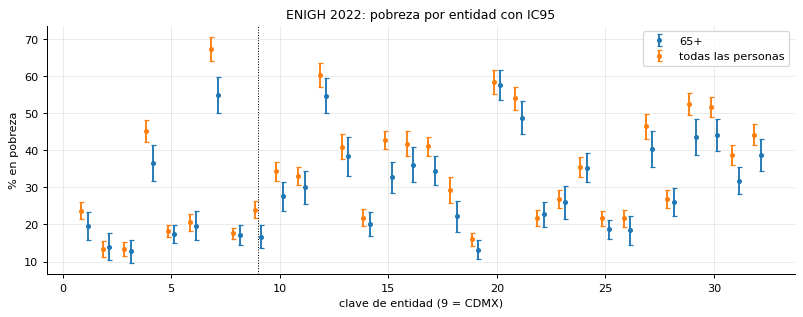

In [32]:
with zipfile.ZipFile(DATOS / 'enigh2022_coneval' / 'pobreza22.csv.zip') as z:
    cols = ['ent', 'factor', 'upm', 'est_dis', 'edad', 'sexo', 'pobreza', 'pobreza_e', 'ic_asalud', 'ic_segsoc', 'ictpc', 'discap', 'hli', 'tam_loc', 'pam', 'ing_pam']
    en = pd.read_csv(z.open('pobreza22.csv'), usecols=cols)
print('Personas:', len(en), '| entidades:', en.ent.nunique(), '| población expandida (M):', round(en.factor.sum() / 1e6, 1), '| personas CDMX (ent=9):', int((en.ent == 9).sum()), '| UPM CDMX:', en[en.ent == 9].upm.nunique())
print('Personas sin clasificación de pobreza (pobreza = NaN):', int(en.pobreza.isna().sum()), '→ se excluyen del denominador')
en['_x'] = en.pobreza.notna().astype(float); en['pobre'] = en.pobreza.fillna(0).astype(float)
R, se = razon(en, 'pobre', '_x', w='factor', h='est_dis', c='upm'); print(f'Pobreza nacional 2022: {100*R:.1f}% (IC95 {100*(R-1.96*se):.1f}–{100*(R+1.96*se):.1f})')
def por_ent(dom_label, dom):
    filas = []
    for e in sorted(en.ent.unique()):
        m = (en.ent == e) & dom & (en._x > 0); t = en.assign(_y=en.pobre * m, _d=m.astype(float))
        if m.sum() < 30: continue
        R, se = razon(t, '_y', '_d', w='factor', h='est_dis', c='upm'); filas.append({'ent': int(e), 'dominio': dom_label, 'n': int(m.sum()), 'pobreza_%': 100 * R, 'ic95_±': 196 * se, 'cv_%': 100 * se / R if R > 0 else np.nan})
    return pd.DataFrame(filas)
todas = por_ent('todas las personas', en.edad >= 0); mayores = por_ent('65+', en.edad >= 65)
res = pd.concat([todas, mayores]); res['ic_util'] = res['cv_%'] <= 30
print('Entidades con CV ≤ 30% (referencia habitual de “estimación utilizable”):', res.groupby('dominio').ic_util.sum().to_dict(), 'de', res.groupby('dominio').ent.nunique().to_dict())
display(res[res.ent == 9])
fig, ax = plt.subplots(figsize=(9, 3.6))
for dom, g in res.groupby('dominio'): ax.errorbar(g.ent + (.15 if dom == '65+' else -.15), g['pobreza_%'], yerr=g['ic95_±'], fmt='o', ms=3, label=dom, capsize=2)
ax.axvline(9, color='k', lw=.8, ls=':'); ax.set_xlabel('clave de entidad (9 = CDMX)'); ax.set_ylabel('% en pobreza'); ax.legend(); ax.set_title('ENIGH 2022: pobreza por entidad con IC95'); plt.tight_layout(); plt.show()

**¿Y por alcaldía?** La versión pública de ENIGH incluye `ubica_geo`. Se mide qué pasaría si se intentara bajar la desagregación a esa clave en CDMX:

In [33]:
with zipfile.ZipFile(DATOS / 'enigh2022_coneval' / 'pobreza22.csv.zip') as z:
    eg = pd.read_csv(z.open('pobreza22.csv'), usecols=['ent', 'ubica_geo', 'factor', 'upm', 'est_dis', 'edad', 'pobreza'])
eg = eg[eg.ent == 9].copy(); eg['_x'] = eg.pobreza.notna().astype(float); eg['pobre'] = eg.pobreza.fillna(0).astype(float)
print('ubica_geo distintos en CDMX:', eg.ubica_geo.nunique(), '| ejemplo de códigos:', sorted(eg.ubica_geo.unique())[:6])
filas = []
for g, d in eg.groupby('ubica_geo'):
    for nom, dom in [('todas', d.edad >= 0), ('65+', d.edad >= 65)]:
        t = eg.assign(_y=eg.pobre * ((eg.ubica_geo == g) & (eg.edad >= (65 if nom == '65+' else 0))) * eg._x, _d=((eg.ubica_geo == g) & (eg.edad >= (65 if nom == '65+' else 0))).astype(float) * eg._x)
        if t._d.sum() < 10: continue
        R, se = razon(t, '_y', '_d', w='factor', h='est_dis', c='upm')
        filas.append({'ubica_geo': int(g), 'dominio': nom, 'n_personas': int((dom).sum()), 'n_UPM': d.upm.nunique(), 'pobreza_%': 100 * R, 'ic95_±': 196 * se, 'cv_%': 100 * se / R if R > 0 else np.nan})
ea = pd.DataFrame(filas); display(ea.pivot_table(index='ubica_geo', columns='dominio', values=['n_personas', 'n_UPM', 'pobreza_%', 'cv_%']).round(1))
print('CV ≤ 30% en:', int((ea[ea.dominio == "65+"]['cv_%'] <= 30).sum()), 'de', ea[ea.dominio == '65+'].shape[0], 'claves (65+) |', int((ea[ea.dominio == "todas"]['cv_%'] <= 30).sum()), 'de', ea[ea.dominio == 'todas'].shape[0], 'claves (todas las edades)')

ubica_geo distintos en CDMX: 16 | ejemplo de códigos: [np.int64(9002), np.int64(9003), np.int64(9004), np.int64(9005), np.int64(9006), np.int64(9007)]


cv_%         n_UPM        n_personas           pobreza_%       
dominio      65+  todas    65+  todas        65+     todas       65+  todas
ubica_geo                                                                  
9002      26.300 24.800 30.000 30.000     82.000   494.000    15.100 14.500
9003      33.000 21.700 25.000 25.000     60.000   404.000    17.100 25.000
9004      44.000 19.000 25.000 25.000     53.000   488.000    10.500 21.300
9005      27.000 16.200 29.000 29.000     57.000   513.000    29.100 31.200
9006      39.900 22.800 19.000 19.000     39.000   299.000    14.900 23.800
9007      23.200 14.300 38.000 38.000     94.000   779.000    23.200 35.000
9008      34.600 21.200 22.000 22.000     32.000   390.000    30.100 20.100
9009      31.200 16.800 19.000 19.000     44.000   991.000    35.600 44.900
9010      42.500 24.500 25.000 25.000     83.000   446.000    11.700 19.700
9011      33.600 14.400 26.000 26.000     66.000   648.000    26.800 34.600
9012      41.300 21.300 27.000 27.000     85.000   681.000    13.300 21.400
9013      56.900 16.000 35.000 35.000     84.000 1,007.000    12.000 29.500
9014      66.500 51.400 29.000 29.000     49.000   282.000     9.800  3.300
9015      47.400 41.800 31.000 31.000     52.000   377.000     8.100 13.600
9016         NaN 83.100 17.000 17.000     28.000   176.000     0.000  6.500
9017      25.700 19.800 26.000 26.000     68.000   421.000    19.900 26.200

CV ≤ 30% en: 4 de 16 claves (65+) | 13 de 16 claves (todas las edades)


## 5. Censo 2020 por AGEB/manzana (CDMX), rezago social por AGEB y Marco Geoestadístico

### 5.1 Censo de Población y Vivienda 2020 — CDMX, AGEB urbana y manzana

In [34]:
CEN_F = 'ageb_mza_urbana_09_cpv2020/conjunto_de_datos/conjunto_de_datos_ageb_urbana_09_cpv2020.csv'
with zipfile.ZipFile(DATOS / 'censo2020_ageb' / 'ageb_mza_urbana_09_cpv2020_csv.zip') as z:
    cen = pd.read_csv(z.open(CEN_F), dtype=str, low_memory=False)
cen['nivel'] = np.select([cen.MUN.eq('000'), cen.LOC.eq('0000'), cen.AGEB.eq('0000'), cen.MZA.eq('000')], ['entidad', 'municipio', 'localidad', 'AGEB'], default='manzana')
print('Filas:', len(cen), '| columnas:', cen.shape[1]); print(cen.nivel.value_counts().to_dict())
num = [c for c in cen.columns if c not in ('ENTIDAD', 'NOM_ENT', 'MUN', 'NOM_MUN', 'LOC', 'NOM_LOC', 'AGEB', 'MZA', 'nivel')]
for c in num: cen[c] = pd.to_numeric(cen[c].replace({'*': np.nan, 'N/D': np.nan}), errors='coerce')
sup = pd.DataFrame({n: cen[cen.nivel == n][['POBTOT', 'P_60YMAS', 'POB65_MAS', 'PCON_DISC', 'PSINDER', 'PHOGJEF_F']].isna().mean() * 100 for n in ['AGEB', 'manzana']}).round(1)
print('\n% de celdas suprimidas (“*”) por nivel — la supresión por confidencialidad crece al bajar de AGEB a manzana:'); display(sup)
ag = cen[cen.nivel == 'AGEB'].copy(); ag['cvegeo'] = ag.ENTIDAD + ag.MUN + ag.LOC + ag.AGEB
print('AGEB en el censo (nivel AGEB):', len(ag), '| claves únicas:', ag.cvegeo.nunique(), '| población total en AGEB:', int(ag.POBTOT.sum()), '| manzanas:', int((cen.nivel == 'manzana').sum()))
print('\nDistribución de población por AGEB:'); print(ag.POBTOT.describe(percentiles=[.1, .5, .9]).round(0).to_dict())
ag['p60'] = ag.P_60YMAS; sorted_ = ag.sort_values('p60', ascending=False).p60.dropna()
print(f"Concentración de los 60+: 10 % de AGEB con más 60+ concentra {100 * sorted_.head(int(.1 * len(sorted_))).sum() / sorted_.sum():.1f} % de los 60+ (con dato); {int(ag.p60.isna().sum())} AGEB sin dato de 60+ por supresión")
alc_c = ag.groupby('NOM_MUN').agg(pob=('POBTOT', 'sum'), p60=('P_60YMAS', 'sum'), disc=('PCON_DISC', 'sum'), sin_ss=('PSINDER', 'sum')); alc_c['pct60'] = 100 * alc_c.p60 / alc_c.pob
display(alc_c.sort_values('pct60', ascending=False).round(1))

Filas: 68941 | columnas: 231
{'manzana': 66456, 'AGEB': 2433, 'localidad': 35, 'municipio': 16, 'entidad': 1}



% de celdas suprimidas (“*”) por nivel — la supresión por confidencialidad crece al bajar de AGEB a manzana:


,AGEB,manzana
POBTOT,0.000,0.000
P_60YMAS,0.700,7.200
POB65_MAS,0.900,11.100
PCON_DISC,1.100,22.100
PSINDER,0.600,5.400
PHOGJEF_F,0.500,3.600


AGEB en el censo (nivel AGEB): 2433 | claves únicas: 2433 | población total en AGEB: 9145632 | manzanas: 66456

Distribución de población por AGEB:
{'count': 2433.0, 'mean': 3759.0, 'std': 2433.0, 'min': 0.0, '10%': 1015.0, '50%': 3396.0, '90%': 6912.0, 'max': 21198.0}
Concentración de los 60+: 10 % de AGEB con más 60+ concentra 21.6 % de los 60+ (con dato); 17 AGEB sin dato de 60+ por supresión


,pob,p60,disc,sin_ss,pct60
NOM_MUN,,,,,
Coyoacán,614447,"126,592.000","34,445.000","160,961.000",20.600
Benito Juárez,434153,"87,344.000","18,216.000","87,197.000",20.100
Azcapotzalco,432205,"78,649.000","23,999.000","90,370.000",18.200
Venustiano Carranza,443704,"78,964.000","25,474.000","125,162.000",17.800
Iztacalco,404695,"70,906.000","24,446.000","110,114.000",17.500
Gustavo A. Madero,1173351,"203,469.000","68,708.000","300,891.000",17.300
Cuauhtémoc,545884,"93,807.000","29,123.000","153,800.000",17.200
Miguel Hidalgo,414470,"71,107.000","17,766.000","79,700.000",17.200
Álvaro Obregón,759003,"122,310.000","38,168.000","187,306.000",16.100


### 5.2 Cruce AGEB: censo × rezago social (CONEVAL) × geometrías (Marco Geoestadístico 2025)

In [35]:
r_a = shapefile.Reader(str(DATOS / 'marco_geo_2025' / '09a'), encoding='latin-1')
geo = pd.DataFrame([dict(zip([f[0] for f in r_a.fields[1:]], rec)) for rec in r_a.records()])
gc = grs[grs.clave_entidad.astype(str).str.zfill(2) == '09'].copy()
gc['cvegeo'] = gc.folio_ageb.astype(str)   # folio_ageb de 13 caracteres = ENT(2)+MUN(3)+LOC(4)+AGEB(4); clave_municipio/localidad en el GRS ya vienen concatenadas con la entidad
print('Ejemplo de claves → censo:', ag.cvegeo.iloc[0], '| GRS:', gc.cvegeo.iloc[0], '| Marco geo:', geo.CVEGEO.iloc[0])
S = {'censo (AGEB)': set(ag.cvegeo), 'GRS (AGEB)': set(gc.cvegeo), 'Marco Geo 2025 (AGEB)': set(geo.CVEGEO)}
mat = pd.DataFrame({a: {b: len(S[a] & S[b]) for b in S} for a in S}); display(mat)
print('Claves del censo que no están en el marco geo:', len(S['censo (AGEB)'] - S['Marco Geo 2025 (AGEB)']), '| del marco geo sin censo:', len(S['Marco Geo 2025 (AGEB)'] - S['censo (AGEB)']), '| GRS sin marco geo:', len(S['GRS (AGEB)'] - S['Marco Geo 2025 (AGEB)']))
for c_ in ['poblacion', 'i_sdsalud', 'i_edbasinc', 'i_nointernet']:
    gc[c_] = pd.to_numeric(gc[c_], errors='coerce')
cg = ag.merge(gc[['cvegeo', 'poblacion', 'grs', 'i_sdsalud', 'i_edbasinc', 'i_nointernet']], on='cvegeo', how='inner')
print('AGEB con censo y GRS:', len(cg), '| diferencia de población censo vs GRS: mediana', float((cg.POBTOT - cg.poblacion).median()), 'máx abs', float((cg.POBTOT - cg.poblacion).abs().max()))
orden = ['Muy bajo', 'Bajo', 'Medio', 'Alto', 'Muy alto']
cg['pct60'] = 100 * cg.P_60YMAS / cg.POBTOT
display(cg.groupby('grs').agg(AGEB=('cvegeo', 'size'), pob=('POBTOT', 'sum'), pct60_mediano=('pct60', 'median'), pct_sinsalud_med=('i_sdsalud', 'median')).reindex(orden).round(1))
print('Correlación de Spearman AGEB: % 60+ vs % sin servicios de salud (GRS) =', round(float(cg[['pct60', 'i_sdsalud']].corr(method='spearman').iloc[0, 1]), 3), '| vs % sin internet =', round(float(cg[['pct60', 'i_nointernet']].corr(method='spearman').iloc[0, 1]), 3))

Ejemplo de claves → censo: 0900200010010 | GRS: 0900200010010 | Marco geo: 0901100011323


,censo (AGEB),GRS (AGEB),Marco Geo 2025 (AGEB)
censo (AGEB),2433,2410,2430
GRS (AGEB),2410,2410,2409
Marco Geo 2025 (AGEB),2430,2409,2430


Claves del censo que no están en el marco geo: 3 | del marco geo sin censo: 0 | GRS sin marco geo: 1
AGEB con censo y GRS: 2410 | diferencia de población censo vs GRS: mediana 0.0 máx abs 0.0


,AGEB,pob,pct60_mediano,pct_sinsalud_med
grs,,,,
Muy bajo,948,2878873,22.200,21.900
Bajo,1234,5433303,15.300,28.600
Medio,200,776546,10.200,34.400
Alto,22,41245,7.700,34.500
Muy alto,6,281,11.800,100.000


Correlación de Spearman AGEB: % 60+ vs % sin servicios de salud (GRS) = -0.455 | vs % sin internet = -0.686


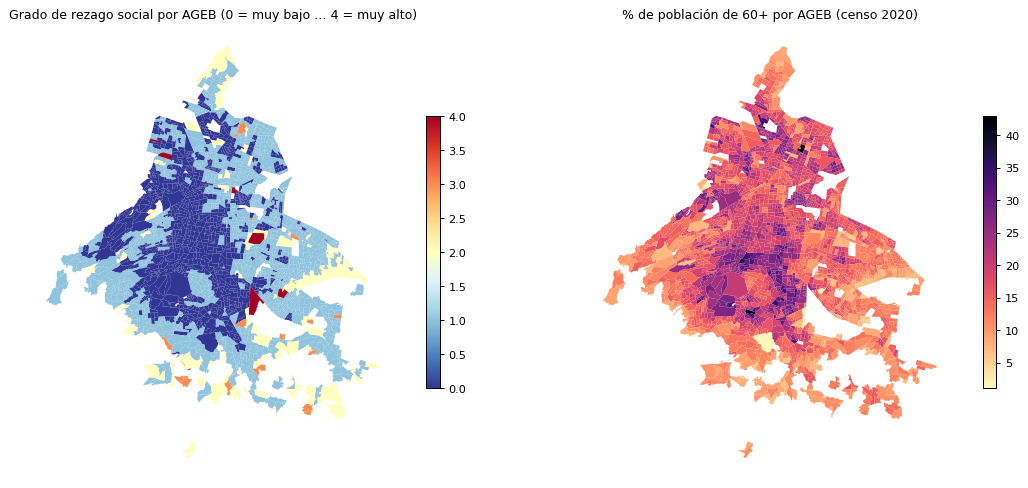

AGEB dibujadas: 2409 y 2409 de 2430 polígonos


In [36]:
from matplotlib.collections import PolyCollection
def poligonos(reader):
    out = {}
    for sh, rec in zip(reader.shapes(), reader.records()):
        pts = np.array(sh.points); parts = list(sh.parts) + [len(pts)]
        out[rec['CVEGEO']] = [pts[parts[i]:parts[i + 1]] for i in range(len(parts) - 1)]
    return out
POLI = poligonos(r_a)
def mapa(ax, valores, titulo, cmap='viridis', categorias=None):
    keys = [k for k in POLI if k in valores.index]; polys = [p for k in keys for p in POLI[k]]
    nparts = [len(POLI[k]) for k in keys]; v = np.repeat(valores.loc[keys].to_numpy(), nparts)
    pc = PolyCollection(polys, array=v, cmap=cmap, edgecolors='none'); ax.add_collection(pc); ax.autoscale(); ax.set_aspect('equal'); ax.set_axis_off(); ax.set_title(titulo)
    plt.colorbar(pc, ax=ax, shrink=.6); return len(keys)
cod = {g: i for i, g in enumerate(orden)}
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
n1 = mapa(ax[0], gc.set_index('cvegeo').grs.map(cod), 'Grado de rezago social por AGEB (0 = muy bajo … 4 = muy alto)', 'RdYlBu_r')
cg2 = cg.set_index('cvegeo'); n2 = mapa(ax[1], cg2.pct60, '% de población de 60+ por AGEB (censo 2020)', 'magma_r'); plt.tight_layout(); plt.show()
print('AGEB dibujadas:', n1, 'y', n2, 'de', len(POLI), 'polígonos')

## 6. DENUE (INEGI, mayo 2026) — establecimientos de CDMX

462 732 líneas (≈ 462 mil establecimientos). Unidad de observación: **establecimiento**, sin factor de expansión. Se lee solo lo necesario. Atención: el archivo trae campos de contacto (teléfono, correo, razón social) que son públicos en DENUE pero **no deben exponerse en entregables** que no los necesiten.

In [37]:
DEN = RAIZ / 'Data' / 'raw' / 'denue_inegi_09_.csv'
if DEN.exists():
    den = pd.read_csv(DEN, encoding='latin-1', low_memory=False, dtype=str,
                      usecols=['id', 'nom_estab', 'raz_social', 'codigo_act', 'nombre_act', 'per_ocu', 'cve_mun', 'municipio', 'ageb', 'manzana', 'telefono', 'correoelec', 'www', 'tipoUniEco', 'latitud', 'longitud', 'fecha_alta', 'cod_postal'])
    fuente_den = DEN.name
else:
    with zipfile.ZipFile(RAIZ / 'denue_09_csv.zip') as z:
        den = pd.read_csv(z.open('conjunto_de_datos/denue_inegi_09_.csv'), encoding='latin-1', low_memory=False, dtype=str,
                          usecols=['id', 'nom_estab', 'raz_social', 'codigo_act', 'nombre_act', 'per_ocu', 'cve_mun', 'municipio', 'ageb', 'manzana', 'telefono', 'correoelec', 'www', 'tipoUniEco', 'latitud', 'longitud', 'fecha_alta', 'cod_postal'])
    fuente_den = 'denue_09_csv.zip'
print('Fuente:', fuente_den, '| establecimientos:', len(den), '| id únicos:', den.id.nunique(), '| MB en memoria:', round(den.memory_usage(deep=True).sum() / 1e6))
pc = (den.isna().mean() * 100).round(1).sort_values(ascending=False); print('% vacío por campo:'); display(pc.to_frame('pct_nulo').T)
print('\nCampos de contacto/identificación con contenido (% de establecimientos):', {c: round(100 * den[c].notna().mean(), 1) for c in ['telefono', 'correoelec', 'www', 'raz_social']})
den['lat'] = pd.to_numeric(den.latitud, errors='coerce'); den['lon'] = pd.to_numeric(den.longitud, errors='coerce')
bbox_ok = den.lat.between(19.0, 19.65) & den.lon.between(-99.4, -98.9)
print('Coordenadas ausentes:', int(den.lat.isna().sum()), '| fuera de la caja de CDMX (lat 19.0–19.65, lon −99.4…−98.9):', int((~bbox_ok & den.lat.notna()).sum()))

Fuente: denue_inegi_09_.csv | establecimientos: 462732 | id únicos: 462732 | MB en memoria: 535
% vacío por campo:


,www,correoelec,raz_social,telefono,nom_estab,id,cod_postal,codigo_act,nombre_act,per_ocu,ageb,municipio,cve_mun,manzana,tipoUniEco,latitud,longitud,fecha_alta
pct_nulo,89.400,77.400,74.100,64.400,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000



Campos de contacto/identificación con contenido (% de establecimientos): {'telefono': np.float64(35.6), 'correoelec': np.float64(22.6), 'www': np.float64(10.6), 'raz_social': np.float64(25.9)}


Coordenadas ausentes: 0 | fuera de la caja de CDMX (lat 19.0–19.65, lon −99.4…−98.9): 3


Establecimientos por sector SCIAN (2 dígitos):


,%,n
sector,,
Comercio menudeo,45.900,212251
Otros servicios,14.600,67707
Alojamiento/alimentos,12.600,58167
Manufactura,7.000,32316
Salud y asistencia,5.100,23400
Comercio mayoreo,3.400,15525
Prof./técnicos,2.500,11583
Educación,2.300,10591
Apoyo a negocios,1.200,5487



Tamaño (per_ocu):


,%
per_ocu,
0 a 5 personas,84.400
6 a 10 personas,7.000
11 a 30 personas,5.300
31 a 50 personas,1.300
51 a 100 personas,1.000
101 a 250 personas,0.600
251 y más personas,0.400


Establecimientos por alcaldía:


,n,pct
municipio,,
Iztapalapa,88580,19.100
Cuauhtémoc,67535,14.600
Gustavo A. Madero,50927,11.000
Venustiano Carranza,30734,6.600
Tlalpan,26643,5.800
Miguel Hidalgo,25329,5.500
Coyoacán,25011,5.400
Álvaro Obregón,24594,5.300
Benito Juárez,24200,5.200



Fecha de alta (año) — primeros/últimos años y moda: {'min': 2010.0, '50%': 2019.0, 'max': 2026.0} | formato: 2026-04


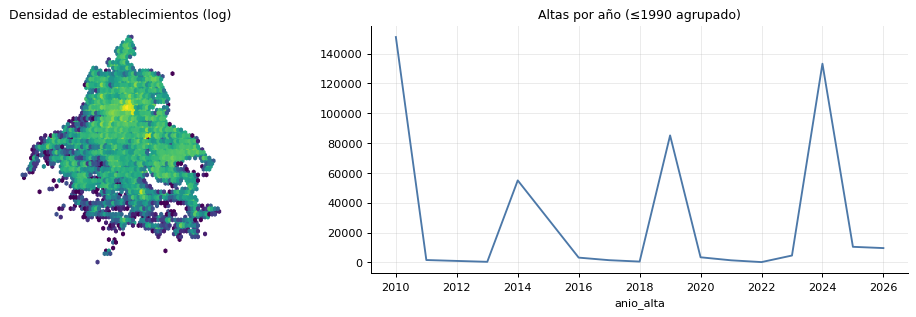

In [38]:
den['sector'] = den.codigo_act.str[:2]; den['subsector'] = den.codigo_act.str[:3]
SECT = {'11': 'Agro', '21': 'Minería', '22': 'Energía/agua', '23': 'Construcción', '31': 'Manufactura', '32': 'Manufactura', '33': 'Manufactura', '43': 'Comercio mayoreo', '46': 'Comercio menudeo',
        '48': 'Transporte', '49': 'Transporte/almacén', '51': 'Información', '52': 'Finanzas', '53': 'Inmobiliarios', '54': 'Prof./técnicos', '55': 'Corporativos', '56': 'Apoyo a negocios',
        '61': 'Educación', '62': 'Salud y asistencia', '71': 'Esparcimiento', '72': 'Alojamiento/alimentos', '81': 'Otros servicios', '93': 'Gobierno'}
s = den.sector.map(SECT).fillna('otro').value_counts(); print('Establecimientos por sector SCIAN (2 dígitos):'); display((s / len(den) * 100).round(1).to_frame('%').join(s.rename('n')))
print('\nTamaño (per_ocu):'); display((den.per_ocu.value_counts(dropna=False, normalize=True) * 100).round(1).to_frame('%'))
mun = den.groupby('municipio').size().sort_values(ascending=False); print('Establecimientos por alcaldía:'); display(mun.to_frame('n').assign(pct=lambda d: (100 * d.n / d.n.sum()).round(1)))
den['anio_alta'] = den.fecha_alta.str[:4]; print('\nFecha de alta (año) — primeros/últimos años y moda:', den.anio_alta.dropna().astype(int).describe()[['min', '50%', 'max']].to_dict(), '| formato:', den.fecha_alta.dropna().iloc[0])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hexbin(den.lon[bbox_ok], den.lat[bbox_ok], gridsize=70, bins='log', cmap='viridis'); ax[0].set_aspect('equal'); ax[0].set_title('Densidad de establecimientos (log)'); ax[0].set_axis_off()
den.anio_alta.dropna().astype(int).clip(lower=1990).value_counts().sort_index().plot(ax=ax[1], color='#4c78a8'); ax[1].set_title('Altas por año (≤1990 agrupado)'); plt.tight_layout(); plt.show()

### 6.1 DENUE × catálogo SCIAN de cuidado del repo

`Analysis/catalogo_scian_cuidado.csv` define qué clases cuentan como “oferta de cuidado”. Se verifica qué parte del catálogo existe realmente en DENUE y cuántos establecimientos aporta cada clase.

In [39]:
cat_sc = limpiar_cols(leer_csv(RAIZ / 'Analysis' / 'catalogo_scian_cuidado.csv', dtype=str)); print(cat_sc.shape, list(cat_sc.columns)); display(cat_sc.head(3))
col_cod = [c for c in cat_sc.columns if re.search(r'codigo|scian|clase', c, re.I)][0]
cod_cat = set(cat_sc[col_cod].astype(str).str.strip())
den_cod = den.codigo_act.value_counts(); en_den = den_cod[den_cod.index.isin(cod_cat)]
print(f'Clases del catálogo: {len(cod_cat)} | presentes en DENUE CDMX: {len(en_den)} | establecimientos totales en esas clases: {int(en_den.sum())} ({100*en_den.sum()/len(den):.2f}% del DENUE)')
print('Clases del catálogo sin ningún establecimiento en CDMX:', sorted(cod_cat - set(den_cod.index))[:15])
nm = den.drop_duplicates('codigo_act').set_index('codigo_act').nombre_act
display(pd.DataFrame({'establecimientos': en_den, 'clase': nm.reindex(en_den.index)}).sort_values('establecimientos', ascending=False).head(12))

(14, 4) ['codigo_act', 'grupo', 'poblacion_atendida', 'nota']


,codigo_act,grupo,poblacion_atendida,nota
0,623311,nucleo,Personas mayores (residencial),Asilos y otras residencias del sector privado
1,623312,nucleo,Personas mayores (residencial),Asilos y otras residencias del sector público
2,624121,nucleo,Personas mayores y con discapacidad (diurno),Centros de día del sector privado


Clases del catálogo: 14 | presentes en DENUE CDMX: 14 | establecimientos totales en esas clases: 1454 (0.31% del DENUE)
Clases del catálogo sin ningún establecimiento en CDMX: []


,establecimientos,clase
codigo_act,,
621341,536,"Consultorios del sector privado de audiología y de terapia ocupacional, física y del l..."
624411,340,Guarderías del sector privado
624412,263,Guarderías del sector público
624122,104,Centros del sector público dedicados a la atención y cuidado diurno de ancianos y disc...
623311,88,Asilos y otras residencias del sector privado para el cuidado de ancianos
621342,23,"Consultorios del sector público de audiología y de terapia ocupacional, física y del l..."
624121,22,Centros del sector privado dedicados a la atención y cuidado diurno de ancianos y disc...
623312,21,Asilos y otras residencias del sector público para el cuidado de ancianos
623211,17,Residencias del sector privado para el cuidado de personas con problemas de retardo me...


## 7. Data Warehouse del repo (`DW/observatorio_dw.sqlite`)

El DW es **derivado** (resultados de scripts), no una fuente primaria; se explora para saber qué contiene y si es coherente con las fuentes.

In [40]:
DW = str(RAIZ / 'DW' / 'observatorio_dw.sqlite')
con = sqlite3.connect(f'file:{DW}?mode=ro', uri=True)   # solo lectura: el EDA no modifica el DW
objs = pd.read_sql("select name, type from sqlite_master where type in ('table','view') order by type, name", con)
cnt = {n: con.execute(f'select count(*) from "{n}"').fetchone()[0] for n in objs.name}
objs['filas'] = objs.name.map(cnt); objs['grupo'] = objs.name.str.extract(r'^(dim|fact|stg|etl|v)_?')[0].fillna('otro')
print('Objetos en el DW:', len(objs)); display(objs.groupby(['type', 'grupo']).agg(objetos=('name', 'size'), filas=('filas', 'sum')))
print('Hechos y dimensiones:'); display(objs[objs.grupo.isin(['dim', 'fact'])].sort_values('filas', ascending=False))

Objetos en el DW: 115


objetos  filas
type  grupo                
table dim         13   5211
      etl          4    112
      fact         5  63871
      stg         81   7013
view  v           12  13421

Hechos y dimensiones:


,name,type,filas,grupo
20,fact_indicador_territorial,table,54018,fact
21,fact_resultado_modelo,table,8663,fact
2,dim_geografia,table,2421,dim
0,dim_configuracion,table,2101,dim
19,fact_estimacion_encuesta,table,990,fact
3,dim_indicador,table,317,dim
6,dim_metrica,table,184,dim
17,fact_asequibilidad,table,150,fact
5,dim_medida,table,87,dim
11,dim_segmento,table,58,dim


In [41]:
for t in ['dim_fuente', 'dim_precision', 'dim_modelo', 'etl_run']:
    d = pd.read_sql(f'select * from {t}', con); print(f'--- {t} {d.shape}'); display(d.head(12))
print('--- etl_dq (calidad de datos del ETL):'); display(pd.read_sql('select * from etl_dq limit 40', con))
print('Violaciones de alcance registradas (v_violaciones_alcance):', pd.read_sql('select count(*) n from v_violaciones_alcance', con).n[0])

--- dim_fuente (12, 11)


,fuente_sk,fuente_id,nombre,emisor,origen_tipo,nivel_geo_max,nivel_geo_max_orden,periodo_cubierto,estado_evidencia,permite_afirmar,prohibe_afirmar
0,1,F02,Censo de Poblacion y Vivienda 2020: resultados por AGEB y manzana urbana,INEGI,externa oficial,Manzana urbana,4,2020,Confirmado,"Localizacion de poblacion 0-5, 6-14, 65+ y con discapacidad a nivel manzana; construcc...","Tendencias o series (es decenal); variables no censales (ingreso, uso del tiempo, uso ..."
1,2,F04,Encuesta Nacional para el Sistema de Cuidados (ENASIC) 2022,INEGI,externa oficial,Nacional,1,2022,Confirmado,"Demanda de cuidados, perfil de personas cuidadoras, uso de servicios y necesidades no ...",Estimaciones para la Ciudad de Mexico o por alcaldia; series historicas (no existe edi...
2,3,F09,Directorio Estadistico Nacional de Unidades Economicas (DENUE),INEGI,externa oficial,Coordenadas / manzana,4,Actualizacion continua,Probable,Localizacion de oferta formal de cuidados filtrando SCIAN sector 62; conteo de estable...,"Medir capacidad de atencion o cupos (el DENUE registra ESTRATO DE PERSONAL OCUPADO, no..."
3,4,F20,Indice y Grado de Rezago Social 2020 por AGEB urbana,CONEVAL,externa oficial,"AGEB urbana (2,410 en la CDMX, 99.1% de su poblacion)",4,2020,"Confirmado que el producto existe (CONEVAL, Nota_GRS_AGEB_urbana_2020.pdf, consultado ...",Distribucion de la poblacion por grado de rezago social y por indicador (derechohabien...,Necesidad o demanda de cuidado; tendencias (un solo corte); conclusiones sobre hogares...
4,5,F22,Indices de marginacion 2020 por entidad y municipio,CONAPO,externa oficial,Municipio (alcaldia),3,2020,Confirmado (publicacion de CONAPO con ISBN en los PDF subidos),Que las 16 alcaldias tienen grado de marginacion Muy bajo en 2020 (indice de 57.3 a 62...,Diferencias de vulnerabilidad entre alcaldias (el indice no distingue entre ellas); ne...
5,6,F23,ENIGH 2022: base final de la Medicion multidimensional de la pobreza 2022 (pobreza22.csv),"CONEVAL, con microdatos ENIGH 2022 de INEGI",externa oficial,Entidad federativa,2,Levantamiento 2022 (ingresos en pesos de agosto 2022),"Confirmado (paquete oficial del CONEVAL con programa de calculo, diccionario FD_pobrez...","Proporcion de hogares de la CDMX con persona de 60+ o con discapacidad (47.1%, IC90 45...",Cifras por alcaldia; disposicion a pagar (solo capacidad de pago); gasto en servicios ...
6,7,F24,"Paquete de calculo de la pobreza municipal 2020 (MunEBPH_2020, version corta)",CONEVAL,externa oficial,Municipio,3,2020,Confirmado que es el paquete oficial (CONEVAL publica Manual_usuario_MunEBPH_2020.pdf)...,"Documentar y, en principio, reproducir el metodo de estimacion en areas pequenas (EBP)...",Nada nuevo por si mismo: sus resultados son los mismos que el archivo de pobreza munic...
7,8,P01,Población de más de 60 años.csv (archivo del proyecto),desconocido,archivo del proyecto (productor desconocido),Alcaldía,3,desconocido (ficha 02_fichas_fuentes),ver 02_fichas_fuentes.csv,None,None
8,9,P02,Capacidad disponible en residencias permanentes de sector privado para adultos y adult...,desconocido,archivo del proyecto (productor desconocido),"Alcaldía (12 de 16; faltan VC, TLAH, CUAJ, MA)",3,desconocido (ficha 02_fichas_fuentes),ver 02_fichas_fuentes.csv,None,None
9,10,P03,Población con discapacidad que necesita ayuda para las actividades de la vida diaria.c...,desconocido,archivo del proyecto (productor desconocido),Alcaldía,3,desconocido (ficha 02_fichas_fuentes),ver 02_fichas_fuentes.csv,None,None


--- dim_precision (5, 5)


,precision_sk,clase,orden,semaforo,regla
0,0,no aplica,0,gris,"la cifra no es una estimación con CV (conteo, razón, derivada)"
1,1,alta,1,verde,CV < 15 (criterio INEGI)
2,2,moderada,2,ámbar,15 <= CV < 30 (criterio INEGI)
3,3,baja,3,rojo,CV >= 30 (criterio INEGI)
4,4,no estimable,4,rojo,CV no calculable


--- dim_modelo (11, 9)


,modelo_sk,codigo,nombre,tipo,script,decision,alternativa_simple,estado,advertencia
0,1,M11,Focalización: ¿a quién ofrecer primero el relevo?,modelo supervisado,"Analysis/B_enasic_cuidadoras.ipynb, sección 11 (y ampliación del 13 oct 2026)",¿A quién primero? (orden de atención entre cuidadoras),"Regla «40 h o más» y horas en continuo, al mismo cupo","versión 1, exploratoria: el objetivo que usa quedó superado por DEC-OBJ-002 (1 nov 202...",Entrenado con la ENASIC nacional; no validado para la población de una institución.
1,2,M18,"Tipología de AGEB urbanas (k-means, 4 tipos)",agrupamiento,"Analysis/D_tipologia_territorial_ageb.ipynb, sección 18",¿Dónde hacer el piloto?,Regla 60+ × internet (4 grupos) e índice CP1 en 4 grupos,exploratorio; sin doble revisión,"Describe población (Censo 2020), no demanda de cuidado."
2,3,M19,Costo de la hora por tipo de jornada,cálculo de costo,Analysis/19_costo_hora_por_jornada.py,"¿Cuánto cuesta? (relevo diurno, mixto o nocturno)",No aplica: cálculo aritmético del piso legal; no estima nada,sin doble revisión; probable: arts. 60 y 61 de la LFT pendientes de verificar en el DOF,Sin prestaciones.
3,4,M20,"Sostenibilidad del relevo por horas (costo, copago, escala y financiamiento)",escenario,Analysis/20_modelo_sostenibilidad.py (supuestos en resultados/20_modelo_sostenibilidad...,¿Cuánto cuesta? (financiamiento en la CDMX),No aplica: escenarios con supuestos declarados; no es un modelo predictivo,"sin doble revisión; ilustrativo en los bloques de escala, financiamiento y costo evitado",Aceptación y costo de operación son supuestos sin fuente; hogares elegibles inferidos ...
4,5,M21,Escalera de reglas y modelos para priorizar cuidadoras,modelo supervisado,Analysis/21_priorizacion_cuidadoras.py,¿A quién primero? (comparación de reglas R0 a R5),R1: regla «40 h o más» al cupo de la regla; R0: azar,"versión 1, exploratoria: el objetivo que usa quedó superado por DEC-OBJ-002 (1 nov 202...",21_tarjeta_puntos.csv se ajustó con SALUD_FISICA y NO es la tarjeta vigente (ver scrip...
5,6,M22,Tarjeta de puntos (objetivo: algún daño),tarjeta de puntos,Analysis/22_tarjeta_puntos.py,¿A quién primero? (instrumento de priorización),Regla «40 h o más» con la misma tasa de selección,"versión 1, exploratoria: el objetivo que usa quedó superado por DEC-OBJ-002 (1 nov 202...","En el bloque de personas mayores abvd1, abvd3 y clin1 valen 0 porque no se preguntó (3..."
6,7,M23,Segmentación de cuidadoras por clases latentes,clases latentes,Analysis/23_segmentacion_cuidadoras.ipynb,¿Quién lo carga? (perfiles más allá de las horas),"Regla de dificultad (2 grupos), regla de dificultad + 40 h e intensidad en 3 grupos",exploratorio; sin doble revisión,Las clases son probabilísticas: no se asignan a personas ni sirven como criterio de el...
7,8,M24,Regla sin pesos para ordenar alcaldías por brecha de oferta,regla de decisión,Analysis/24_prioridad_zonas.py,¿En qué orden atender las zonas?,No aplica: es la alternativa simple; se contrasta con un índice con pesos (M25),sin doble revisión,"No hay variable de resultado observada: no se valida, solo se mide su sensibilidad. El..."
8,9,M25,Prueba: índice con pesos frente a la regla sin pesos,prueba de sensibilidad,Analysis/25_prueba_indice_con_pesos.py,¿En qué orden atender las zonas? (¿conviene ponderar?),La regla sin pesos del script 24,sin doble revisión,El peso es una decisión normativa que los datos no resuelven.
9,10,M26,"Diagnóstico previo a la focalización v2 (muestra, escalera de información y candidatos...",diagnóstico descriptivo,Analysis/26_diagnostico_previo_focalizacion.py,¿A quién primero? (qué objetivo y qué predictores admite la muestra),No aplica: describe la muestra y la regla «40 h o más»; no elige objetivo,"exploratorio; posterior a los resultados de 11, 21 y 22; sin doble revisión",La tabla de candidatos a objetivo NO sirve para elegirlo: el objetivo se fija por cons...


--- etl_run (1, 6)


,run_id,inicio,fin,estado,version_etl,raiz_repo
0,20,2026-11-03T03:38:59,2026-11-03T03:39:14,ok con advertencias,1.1.0,/sessions/rcw-012w6vc4k9ntae3xyt6bv1pa/mnt/Downloads--pp26-2


--- etl_dq (calidad de datos del ETL):


,run_id,codigo,severidad,descripcion,paso,detalle
0,20,DQ01,error,Integridad referencial: ninguna clave foránea huérfana,1,0 huérfanas
1,20,DQ02,error,"Conteos de control: filas de origen = filas cargadas + rechazadas (6 estimaciones, 2 a...",1,
2,20,DQ03,error,Alcance: ningún hecho está en un nivel geográfico más fino que el que permite su fuente,1,0 violaciones: []
3,20,DQ04,error,Protección de datos: ninguna columna de staging parece identificar a una persona,1,[]
4,20,DQ05,error,Rango: toda proporción estimada está entre 0 y 100,1,"encuesta 0, asequibilidad 0"
5,20,DQ05b,advertencia,"Intervalos de confianza dentro de [0,100] (los de Wald pueden salirse; el DW no los re...",0,"49 intervalos fuera de rango: 03_enasic_barreras_estimaciones.csv: 3 (mín li90 -1.4, m..."
6,20,DQ06,advertencia,Intervalos: li90 ≤ estimación ≤ ls90 (tolerancia 0.06 por redondeo),1,"encuesta 0, asequibilidad 0"
7,20,DQ07,advertencia,Precisión: la clase publicada coincide con la regla del INEGI aplicada al CV,1,0 filas: []
8,20,DQ08,error,Totales de control: núcleo = 235 (bitácora 20 sept); participaciones suman 100,1,"{'dependencia_severa_pct_cdmx': 99.9, 'oferta_nucleo_estab': 235.0, 'oferta_nucleo_pct..."
9,20,DQ08b,advertencia,"Total de control: población CDMX del Censo 2020 = 9,209,944",1,suma 9209944


Violaciones de alcance registradas (v_violaciones_alcance): 0


In [42]:
cobg = pd.read_sql('select * from v_cobertura_geografica', con); display(cobg)
cobt = pd.read_sql('select * from v_cobertura_temporal', con); display(cobt)
fe = pd.read_sql('select * from fact_estimacion_encuesta limit 5', con); print('fact_estimacion_encuesta columnas:', list(fe.columns))
tot = pd.read_sql('select * from fact_estimacion_encuesta', con)
for c in [c for c in tot.columns if tot[c].nunique() <= 12 and tot[c].dtype == object][:6]: print(c, tot[c].value_counts().head(8).to_dict())

,medida_codigo,medida,alcaldia_sin_dato
0,plazas_residencias_privadas,Plazas en residencias permanentes privadas,Cuajimalpa de Morelos
1,plazas_residencias_privadas,Plazas en residencias permanentes privadas,Milpa Alta
2,plazas_residencias_privadas,Plazas en residencias permanentes privadas,Tláhuac
3,plazas_residencias_privadas,Plazas en residencias permanentes privadas,Venustiano Carranza
4,plazas_por_1000_personas_adl,"Plazas por 1,000 personas con dificultad para actividades de la vida diaria",Cuajimalpa de Morelos
5,plazas_por_1000_personas_adl,"Plazas por 1,000 personas con dificultad para actividades de la vida diaria",Milpa Alta
6,plazas_por_1000_personas_adl,"Plazas por 1,000 personas con dificultad para actividades de la vida diaria",Tláhuac
7,plazas_por_1000_personas_adl,"Plazas por 1,000 personas con dificultad para actividades de la vida diaria",Venustiano Carranza
8,prioridad_pct_en_5_ageb,% del volumen (cuartil) en sus 5 AGEB con más 60+,Benito Juárez


,fuente_id,fuente,tabla_hecho,n_periodos_distintos,periodos,permite_tendencia
0,F02,Censo de Poblacion y Vivienda 2020: resultados por AGEB y manzana urbana,fact_indicador_territorial,1,2020,0
1,F02,Censo de Poblacion y Vivienda 2020: resultados por AGEB y manzana urbana,fact_resultado_modelo,1,2020,0
2,F04,Encuesta Nacional para el Sistema de Cuidados (ENASIC) 2022,fact_asequibilidad,1,2022,0
3,F04,Encuesta Nacional para el Sistema de Cuidados (ENASIC) 2022,fact_estimacion_encuesta,1,2022,0
4,F04,Encuesta Nacional para el Sistema de Cuidados (ENASIC) 2022,fact_resultado_modelo,1,2022,0
5,F09,Directorio Estadistico Nacional de Unidades Economicas (DENUE),fact_indicador_territorial,1,mayo 2026,0
6,F20,Indice y Grado de Rezago Social 2020 por AGEB urbana,fact_indicador_territorial,1,2020,0
7,F22,Indices de marginacion 2020 por entidad y municipio,fact_indicador_territorial,1,2020,0
8,F23,ENIGH 2022: base final de la Medicion multidimensional de la pobreza 2022 (pobreza22.csv),fact_asequibilidad,1,2022,0
9,F23,ENIGH 2022: base final de la Medicion multidimensional de la pobreza 2022 (pobreza22.csv),fact_indicador_territorial,1,2022,0


fact_estimacion_encuesta columnas: ['estimacion_id', 'indicador_sk', 'segmento_sk', 'geografia_sk', 'periodo_sk', 'fuente_sk', 'precision_sk', 'estimacion', 'se', 'cv', 'li90', 'ls90', 'n_muestra_dominio', 'n_muestra_si', 'total_expandido', 'dif_pp', 'dif_li90', 'dif_ls90', 'dif_significativa', 'archivo_origen', 'fila_origen', 'run_id']
archivo_origen {'12b_segmentacion_series.csv': 449, '12_segmentacion_estimaciones.csv': 249, '07_enasic_necesidad_vs_norma_estimaciones.csv': 166, '03_enasic_barreras_estimaciones.csv': 69, '16_perfil_grupo_problema.csv': 22, '30_perfil_grupo_salud3.csv': 22, '04_contratacion_por_quintil.csv': 10, '29_grupo_problema_salud3.csv': 3}


## 8. Cruces entre fuentes: ¿cuadran las cifras de población y qué nivel territorial admite cada una?

### 8.1 Población de CDMX según cada fuente (2020) y por alcaldía

In [43]:
def pob_coneval(hoja):
    raw = pd.read_excel(XLSX, sheet_name=hoja, header=None)
    h1 = raw.iloc[6].ffill().astype(str); h2 = raw.iloc[7].astype(str); d = raw.iloc[8:].copy(); d.columns = [f'{a}|{b}' for a, b in zip(h1, h2)]
    cm = [c for c in d.columns if c.startswith('Clave municipio')][0]; cp = [c for c in d.columns if c.startswith('Población total') and c.endswith('2020')][0]
    d = d[d[cm].astype(str).str.fullmatch(r'\d{5}')]; return pd.Series(pd.to_numeric(d[cp], errors='coerce').values, index=d[cm].astype(str).values)
pc_adm = pob_coneval('adultmay'); pc_muj = pob_coneval('mujeres')
mun_c = cen[cen.nivel == 'municipio'][['MUN', 'NOM_MUN', 'POBTOT', 'POB65_MAS', 'P_60YMAS']].copy(); mun_c['cve'] = '09' + mun_c.MUN
imm9 = imm[imm.CVE_ENT.astype(str).str.zfill(2) == '09'].copy(); imm9['cve'] = '09' + (imm9.CVE_MUN.astype(int) % 1000).astype(str).str.zfill(3)
comp = mun_c.set_index('cve')[['NOM_MUN', 'POBTOT', 'POB65_MAS']].rename(columns={'POBTOT': 'censo_pobtot', 'POB65_MAS': 'censo_65mas'})
comp['conapo_imm_pobtot'] = imm9.set_index('cve').POB_TOT; comp['coneval_mujeres_total'] = pc_muj.reindex(comp.index); comp['coneval_65mas_total'] = pc_adm.reindex(comp.index)
comp['grs_ageb_pobtot'] = gc.assign(cve=gc.folio_ageb.str[:5]).groupby('cve').poblacion.sum()
comp['dif_censo_vs_conapo_%'] = 100 * (comp.conapo_imm_pobtot - comp.censo_pobtot) / comp.censo_pobtot
comp['dif_65mas_censo_vs_coneval_%'] = 100 * (comp.coneval_65mas_total - comp.censo_65mas) / comp.censo_65mas
display(comp.round(1)); print('Totales CDMX:', {c: int(comp[c].sum()) for c in ['censo_pobtot', 'conapo_imm_pobtot', 'grs_ageb_pobtot', 'censo_65mas', 'coneval_65mas_total']})
print('Población suma AGEB urbanas (censo):', int(ag.POBTOT.sum()), '| suma niveles municipio:', int(mun_c.POBTOT.sum()), '→ diferencia = población fuera de AGEB urbana (rural/localidades): ', int(mun_c.POBTOT.sum() - ag.POBTOT.sum()))

,NOM_MUN,censo_pobtot,censo_65mas,conapo_imm_pobtot,coneval_mujeres_total,coneval_65mas_total,grs_ageb_pobtot,dif_censo_vs_conapo_%,dif_65mas_censo_vs_coneval_%
cve,,,,,,,,,
09002,Azcapotzalco,432205,"54,863.000",432205,"214,113.000","54,425.000",432205,0.000,-0.800
09003,Coyoacán,614447,"90,448.000",614447,"298,623.000","89,394.000",614447,0.000,-1.200
09004,Cuajimalpa de Morelos,217686,"16,760.000",217686,"105,169.000","21,798.000",212735,0.000,30.100
09005,Gustavo A. Madero,1173351,"141,375.000",1173351,"587,469.000","151,056.000",1165167,0.000,6.800
09006,Iztacalco,404695,"49,074.000",404695,"200,417.000","47,874.000",404695,0.000,-2.400
09007,Iztapalapa,1835486,"174,312.000",1835486,"913,990.000","178,837.000",1835454,0.000,2.600
09008,La Magdalena Contreras,247622,"26,066.000",247622,"126,231.000","27,751.000",246428,0.000,6.500
09009,Milpa Alta,152685,"10,741.000",152685,"82,689.000","11,062.000",128710,0.000,3.000
09010,Álvaro Obregón,759137,"83,813.000",759137,"377,552.000","87,576.000",759003,0.000,4.500


Totales CDMX: {'censo_pobtot': 9209944, 'conapo_imm_pobtot': 9209944, 'grs_ageb_pobtot': 9130248, 'censo_65mas': 1022105, 'coneval_65mas_total': 1035870}
Población suma AGEB urbanas (censo): 9145632 | suma niveles municipio: 9209944 → diferencia = población fuera de AGEB urbana (rural/localidades):  64312


### 8.2 ¿Qué nivel territorial admite cada fuente? (derivado de lo medido arriba, no de lo declarado)

In [44]:
cv65 = ea[ea.dominio == '65+']['cv_%']
mat = pd.DataFrame([
    ('ENASIC 2022', 'Ninguno: sin variable geográfica en las 6 tablas (§2.2)', 'No', 'Nacional (representatividad estatal: [desconocida] con lo que hay en el repo)'),
    ('ENIGH 2022 (pobreza22)', f'Entidad; ubica_geo trae 16 claves en CDMX, pero con CV ≤ 30 % en {(cv65 <= 30).sum()} de {cv65.notna().sum()} (65+)', 'No', 'Entidad'),
    ('CONEVAL pobreza municipal 2010-2020', 'Municipio/alcaldía, con marca de precisión por celda', 'Condicionado a la marca de precisión', 'Alcaldía (solo celdas ✔/⚠)'),
    ('CONAPO marginación 2020', 'Municipio; en CDMX las 16 alcaldías son “Muy bajo”', 'Sí, pero sin poder discriminante dentro de CDMX', 'Alcaldía'),
    ('CONEVAL IRS/GRS 2020', 'Localidad y AGEB urbana (2,410 AGEB en CDMX)', 'Sí', 'AGEB'),
    ('Censo 2020 (AGEB y manzana)', 'Manzana; supresión “*” sube de AGEB a manzana (§5.1)', 'Sí', 'AGEB (manzana con supresión)'),
    ('DENUE 05/2026', 'Coordenadas; 3 puntos fuera de CDMX', 'Sí', 'Punto/AGEB'),
    ('Proyección población por alcaldía', 'Alcaldía × quinquenio × sexo × año 2015-2030', 'Sí (PORCENTAJE es del total CDMX)', 'Alcaldía'),
    ('Capacidad residencias privadas', '12 de 16 alcaldías; ausencia ≠ 0 (§3.2)', 'Parcial', 'Alcaldía (12/16)'),
    ('Centros de día públicos', '15 de 16 alcaldías; Milpa Alta ausente', 'Parcial', 'Alcaldía (15/16)'),
    ('Horas laborales y de cuidado; seguridad social; guarderías; gasto privado', 'Sin dimensión geográfica ni fuente/año documentados', 'No', '[desconocida]'),
    ('Horas de trabajo no remunerado 2019; PEF 2026', 'Entidad / programa presupuestario', 'No (contexto nacional)', 'Entidad'),
], columns=['fuente', 'nivel geográfico observado', 'conclusión por alcaldía', 'unidad máxima defendible'])
display(mat)

,fuente,nivel geográfico observado,conclusión por alcaldía,unidad máxima defendible
0,ENASIC 2022,Ninguno: sin variable geográfica en las 6 tablas (§2.2),No,Nacional (representatividad estatal: [desconocida] con lo que hay en el repo)
1,ENIGH 2022 (pobreza22),"Entidad; ubica_geo trae 16 claves en CDMX, pero con CV ≤ 30 % en 4 de 15 (65+)",No,Entidad
2,CONEVAL pobreza municipal 2010-2020,"Municipio/alcaldía, con marca de precisión por celda",Condicionado a la marca de precisión,Alcaldía (solo celdas ✔/⚠)
3,CONAPO marginación 2020,Municipio; en CDMX las 16 alcaldías son “Muy bajo”,"Sí, pero sin poder discriminante dentro de CDMX",Alcaldía
4,CONEVAL IRS/GRS 2020,"Localidad y AGEB urbana (2,410 AGEB en CDMX)",Sí,AGEB
5,Censo 2020 (AGEB y manzana),Manzana; supresión “*” sube de AGEB a manzana (§5.1),Sí,AGEB (manzana con supresión)
6,DENUE 05/2026,Coordenadas; 3 puntos fuera de CDMX,Sí,Punto/AGEB
7,Proyección población por alcaldía,Alcaldía × quinquenio × sexo × año 2015-2030,Sí (PORCENTAJE es del total CDMX),Alcaldía
8,Capacidad residencias privadas,12 de 16 alcaldías; ausencia ≠ 0 (§3.2),Parcial,Alcaldía (12/16)
9,Centros de día públicos,15 de 16 alcaldías; Milpa Alta ausente,Parcial,Alcaldía (15/16)


## 9. Qué se sabe, qué no y qué hacer con ello

### 9.1 ENASIC — qué es y qué no es  *(todas [confirmada] salvo marca explícita)*

- **Cobertura.** 6 tablas, 1 286 variables (§2.4), 6 423 viviendas, 6 508 hogares, 21 776 residentes, 5 579 personas elegidas (15–60 años), 5 677 personas cuidadoras (15+) y 928 hogares unipersonales. Integridad referencial perfecta entre tablas (§2.2).
- **No es geolocalizable.** Ninguna tabla trae entidad, municipio ni localidad; `LLAVEVIV` = UPM + 2 dígitos. El metadato público solo declara cobertura espacial «Estados Unidos Mexicanos» y no menciona representatividad estatal. La representatividad estatal es **[desconocida]** con lo que hay en el repo; lo único defendible es **nacional**. Cualquier cifra “por alcaldía” con ENASIC es una importación de otra fuente, no una estimación.
- **Diseño.** 148 estratos, 896 UPM; efecto de diseño de Kish por pesos entre 1.8 y 2.2 → la muestra de cuidadoras (5 677) equivale a ~3 200 observaciones por pesos; la de hogares unipersonales a ~510 y 17 de sus estratos tienen una sola UPM (el error se subestima ahí). Expande a 128.9 M de personas (CONAPO 2020: 126.0 M, razón 1.023) y 38.8 M de hogares.
- **Lo que ya está medido con IC.** El 75.1 % de las cuidadoras son mujeres (IC95 73.8–76.3) frente a 53.2 % de la población de 15+; 61.5 % de las cuidadoras son PEA; 68.9 % cuidan a un solo tipo de población (§2.9). El 78.1 % de los hogares “necesita cuidados”, **pero la definición incluye niñez**: 40.8 % por 6–17, 32.0 % por 60+, 21.6 % por 0–5, 12.7 % por discapacidad (§2.8). No sirve como “tamaño de mercado”.
- **Las cifras transcritas a mano reproducen** con los microdatos (5 de 5; §2.11) **si** se usa el universo correcto. El 68.4 % (“no tiene quién cuide”) solo sale con *mujeres que realizaron cuidados* (68.3 %); con todas las mujeres con respuesta sale 39.0 %. El riesgo no es la transcripción: es reutilizar la cifra con otro denominador.
- **Problemas de calidad concretos.** (i) El catálogo de `CT_NHA` está mal etiquetado en ambas tablas (`cui`, `ele`): muestra “Población no económicamente activa” para el código 2 y deja el 3 sin etiqueta; la variable no es interpretable con el diccionario público. (ii) Redondeo de edades: Whipple 114 (residentes), 119 (persona elegida), 110 (cuidadoras), 104 (unipersonales); “muy preciso” sería < 105. (iii) 24 de 670 preguntas Sí/No tienen IC95 de ± más de 10 pp. (iv) Las horas de cuidado están repartidas en preguntas distintas según el tipo de persona cuidada (`P6_7`: n = 636, solo cuidado por discapacidad/dependencia; `P6_26`: n = 4 599): **no hay una única variable de “horas de cuidado”** y el 23.7 % de las respuestas de `P6_7` caen en múltiplos de 10.
- **Variables “marca”.** `PB_*`, `CC_OH` y `CR_COH` solo traen el código 1 (o vacío); promediar sin tratar el vacío como “no” da 100 % falso (me pasó en la primera versión de este cuaderno).
- **Brechas por sexo entre cuidadoras.** 30 de 255 comparaciones superan Bonferroni; las mayores: “imposibilitada(o) para trabajar por el cuidado” 27.6 % mujeres vs 4.9 % hombres; “se siente cansada(o)” 36.7 % vs 13.2 %; “disminuyó su tiempo de sueño” 29.7 % vs 15.4 % (§2.13). Son asociaciones descriptivas, no causales.

### 9.2 Fuentes agregadas y de contexto

- **`PORCENTAJE` es el % del total de CDMX**, no de la alcaldía (suma 100 en cada año). Sin normalizar, el orden por alcaldía refleja tamaño poblacional (correlación de rangos 0.51 con el envejecimiento real). Normalizado: 60+ va de 10.3 % (Milpa Alta) a 21.7 % (Benito Juárez) en la proyección 2020 (§3.3).
- **Año del archivo “Población de más de 60 años”:** su total (16.195 % del total CDMX) se parece más a la proyección de **2020** (16.026 %), con el mismo orden de alcaldías (Spearman 1.0). Eso lo **acota**, no lo documenta: año y origen siguen **[desconocida]**.
- **Cobertura incompleta, no ceros.** Capacidad residencial privada: 12 de 16 alcaldías (faltan Cuajimalpa, Milpa Alta, Tláhuac, Venustiano Carranza). Centros de día públicos: 15 de 16 (falta Milpa Alta) y una fila con grafía duplicada en Álvaro Obregón (157 vs 156 instituciones según se sume o no). Si algo rellena esas celdas con 0, afirma algo que la fuente no dice.
- **Archivos sin procedencia:** horas laborales y de cuidado, seguridad social, guarderías (categorías compuestas como `IMSS_PEMEX/Defensa/Marina`, `ISSSTE_Privado`; “hombres” en minúscula), gasto privado (dos filas con n = 1). No se pueden usar en afirmaciones con fuente/año/cobertura hasta documentarlos.
- **PEF 2026 Anexo 31:** 5 programas concentran 90.8 % del monto (Beca Rita Cetina 27.6 %, IMSS salud 27.1 %, Pensión Adultos Mayores 26.3 %…). El total no es “gasto en cuidados”; mezcla programas con una acción transversal de cuidado **[probable]**.
- **Trabajo no remunerado 2019:** las mujeres dedican entre 2.0 y 3.5 veces las horas de los hombres según la entidad (Chiapas 3.5×). Internamente consistente (suma H+M = total; ±1 por redondeo).

### 9.3 Territorio: lo que sí y lo que no admite cada fuente

- **ENIGH 2022** trae `ubica_geo` con 16 claves en CDMX, tentadora para “pobreza por alcaldía”. Con 65+ solo **4 de 15** claves tienen CV ≤ 30 % (13 de 16 con todas las edades): no es una base defendible para alcaldías. A nivel entidad sí: CDMX 24.0 % (±2.3 pp); 65+ 16.7 % (±3.1 pp). La regla del proyecto (“sin conclusiones por alcaldía con encuestas nacionales”) **queda respaldada por los datos**, no solo por precaución.
- **CONEVAL municipal 2010–2020** sí llega a alcaldía, pero 17.2 % de las estimaciones 2020 de 65+ en CDMX son “sin precisión” (16.5 % a nivel nacional); 67.2 % de los municipios del país tiene al menos un indicador de 65+ “sin precisión”. Hay que filtrar por la marca ✔/⚠, no usar todo el cuadro.
- **CONAPO marginación:** las 16 alcaldías son “Muy bajo” (IM 57.3–62.4): no discrimina dentro de CDMX.
- **AGEB (Censo × GRS × Marco Geo).** 2 433 AGEB urbanas en el censo, 2 410 con GRS (todas con censo), 2 430 con polígono (3 AGEB del censo sin polígono, 1 del GRS sin polígono). La supresión por confidencialidad sube de 0.7 % de AGEB a 7.2 % de manzanas para 60+ (y 22.1 % para discapacidad): bajar a manzana cuesta datos.
- **Los 60+ se concentran donde el rezago es *menor*.** Mediana de % 60+ por AGEB: 22.2 % en rezago “Muy bajo”, 15.3 % en “Bajo”, 10.2 % en “Medio”; Spearman −0.46 con “% sin servicios de salud” y −0.69 con “% sin internet” (§5.2). Sumar “rezago” y “60+” en un índice territorial mezcla dos señales con relación **inversa**: el AGEB con más personas mayores suele ser el de menor rezago. (Los 6 AGEB “Muy alto” suman 281 habitantes: artefacto de tamaño.)
- **Las poblaciones cuadran, con una excepción.** Censo = CONAPO en las 16 alcaldías (diferencia 0); GRS cubre 99.1 % de la población. En cambio, el total de 65+ de CONEVAL difiere del censo: Cuajimalpa +30.1 %, Miguel Hidalgo +12.3 %, GAM +6.8 %, Cuauhtémoc −8.0 % (§8.1). Causa **[desconocida]** (¿otra definición de 65+? ¿otra base de cálculo?).
- **DENUE:** 462 732 establecimientos, ids únicos; 84.4 % con 0–5 personas ocupadas; 45.9 % comercio al por menor. Las 14 clases SCIAN del catálogo de cuidado existen todas en CDMX y suman 1 454 establecimientos (0.31 % del DENUE), de los cuales 536 son consultorios de audiología/terapia (clase 621341), la clase más numerosa. El archivo trae contacto (teléfono 35.6 %, correo 22.6 %, web 10.6 %, razón social 25.9 %): público en origen, pero no debe viajar a entregables que no lo necesiten.

### 9.4 Lo que esto cuestiona (para discutir, no para dar por válido)

1. **“Nicho mapeado” puede ser “nicho acotado por las variables que ya conocíamos”.** El catálogo (§2.4) y la búsqueda de uso (§2.14) muestran módulos enteros con ninguna o muy pocas menciones literales de sus variables en `Analysis/`: `P9` de la persona elegida (71 variables; abre con «Durante su infancia y adolescencia… ¿quién…?»), `P8` del hogar unipersonal (41; «Cuando usted se enferma, ¿quién la(o) cuida regularmente?»), `P4` de residentes (127; cuidados recibidos la semana pasada), `P5` de empleo y condiciones laborales (100 por tabla) y `P7` (48; ~8 % mencionado). Son menciones literales: variables construidas con f-strings no se detectan, y la mención no es uso. Aun así, eso no prueba que valgan la pena; solo que no hay evidencia de que se evaluaron.
2. **Toda priorización territorial combina fuentes con unidades distintas.** ENASIC aporta *quién* (perfil), el Censo/GRS/DENUE aportan *dónde*, y no hay variable que permita verificar que el perfil de ENASIC se parece al de una alcaldía concreta. Es un supuesto de transportabilidad **[probable que sea razonable, no verificable aquí]**.
3. **El tamaño efectivo manda.** Cualquier modelo sobre horas de cuidado a personas con discapacidad/dependencia (`P6_7`) descansa en 636 cuidadoras (~una décima parte de las 5 677), y con sub-grupos por sexo/edad se cae a decenas. La regla “comparar contra una alternativa simple” importa más cuanto menor es la n.
4. **“Hay datos” ≠ “hay cobertura”.** 4 de 16 alcaldías sin dato de residencias privadas, 1 sin centros de día, varios archivos sin fuente documentada: cualquier mapa o índice que los trate como cero o los ignore silenciosamente decide algo sin decirlo.

### 9.5 Preguntas abiertas y qué falta para cerrarlas

| # | Pregunta | Estado | Qué haría falta |
|---|---|---|---|
| 1 | ¿ENASIC admite representatividad estatal? | **[desconocida]** | Documento metodológico / diseño muestral de INEGI (no está en el repo) |
| 2 | Significado de `CT_NHA` (código 3) | **[desconocida]** | Nota técnica/catálogo oficial |
| 3 | Año y origen de “Población de más de 60 años”, “Capacidad residencial” y “Discapacidad con ayuda” | **[probable 2020]** solo el primero | Pedir la fuente a quien los subió |
| 4 | Por qué CONEVAL-65+ difiere del censo en Cuajimalpa (+30 %) y Miguel Hidalgo (+12 %) | **[desconocida]** | Revisar la definición de grupo “adultmay” en la metodología CONEVAL |
| 5 | ¿Las 4 alcaldías sin dato de residencias privadas tienen 0 o no se registraron? | **[desconocida]** | Consultar el registro/directorio original |
| 6 | Las 3 AGEB del censo sin polígono y la AGEB del GRS sin polígono | **[confirmada]** que existen | Revisar claves AGEB en Marco Geo 2025 vs. censo 2020 |
| 7 | ¿Qué módulos de ENASIC conviene explorar a fondo? | Abierta | Decidir criterio *antes* de mirar resultados (evitar elegir por lo que “sale bonito”) |

### 9.6 Archivos que produjo este cuaderno

Solo metadatos y agregados (sin microdatos), en `Analysis/eda_general/`: `catalogo_variables_enasic.csv` (1 286 filas: etiqueta, tipo, nulos, categoría modal, menciones en el repo) y `prevalencias_si_no_enasic.csv` (670 preguntas Sí/No con IC95). El cuaderno **no modifica** ningún otro archivo del repo; el DW se abrió en modo solo lectura.